In [ ]:
import torch
import os
import numpy as np

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/Waste_Sorting_PBL/PackWISE_dataset_v2.zip"

print("Dataset ZIP found:", os.path.exists(ZIP_PATH))

Dataset ZIP found: True


In [ ]:
import zipfile
import os

DATASET_DIR = "/content/PackWISE"

os.makedirs(DATASET_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)

    if level <= 2:
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:8]:
            print(f"{indent}  {file}")

PackWISE/
  convert_dataset_to_yolo_format.py
  PackWISE_title_page.jpg
  readme.txt
  category_distribution.pdf
  data/
    train.json
    val.json
    test.json
    val/
      Vollstrom1_frame00076_Probe00038_00039.jpg
      Vollstrom1_frame00186_Probe00095.jpg
      Vollstrom2_frame00028_Probe00014.jpg
      Vollstrom6_frame00014_Probe00007.jpg
      Vollstrom1_frame00162_Probe00082_00083.jpg
      Vollstrom6_frame00056_Probe00028_00029.jpg
      Vollstrom1_frame00151_Probe00077.jpg
      Vollstrom2_frame00188_Probe00096.jpg
    test/
      Vollstrom1_frame00227_Probe00116.jpg
      Vollstrom6_frame00101_Probe00051_00052.jpg
      Vollstrom6_frame00064_Probe00032_00033.jpg
      Vollstrom1_frame00074_Probe00037_00038.jpg
      Vollstrom2_frame00052_Probe00026_00027.jpg
      Vollstrom1_frame00094_Probe00048.jpg
      Vollstrom2_frame00266_Probe00136.jpg
      Vollstrom6_frame00102_Probe00052.jpg
    train/
      Vollstrom2_frame00222_Probe00113_00114.jpg
      Vollstrom2_frame00029_

In [ ]:
import os
import json

DATA_DIR = "/content/PackWISE/data"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")
TEST_DIR  = os.path.join(DATA_DIR, "test")

TRAIN_JSON = os.path.join(DATA_DIR, "train.json")
VAL_JSON   = os.path.join(DATA_DIR, "val.json")
TEST_JSON  = os.path.join(DATA_DIR, "test.json")

with open(TRAIN_JSON, "r") as f:
    train_data = json.load(f)

with open(VAL_JSON, "r") as f:
    val_data = json.load(f)

with open(TEST_JSON, "r") as f:
    test_data = json.load(f)

print("Train images:", len(train_data["images"]))
print("Validation images:", len(val_data["images"]))
print("Test images:", len(test_data["images"]))

print("\nTrain annotations:", len(train_data["annotations"]))
print("Validation annotations:", len(val_data["annotations"]))
print("Test annotations:", len(test_data["annotations"]))

print("\nNumber of classes:", len(train_data["categories"]))

Train images: 410
Validation images: 88
Test images: 88

Train annotations: 4669
Validation annotations: 990
Test annotations: 1054

Number of classes: 23


In [ ]:
print("PACKWISE CLASSES\n")

for category in train_data["categories"]:
    print(category["id"], "->", category["name"])

PACKWISE CLASSES

1 -> undefined
2 -> plastic-foil/bag
3 -> aluminium-coated-foil
4 -> paper-bag
5 -> beverage-carton
6 -> plastic-other
7 -> plastic-lid
8 -> plastic-cup/pot
9 -> blister
10 -> metal-can
11 -> metal-foil
12 -> net
13 -> metal-lid
14 -> tissue
15 -> wood
16 -> paper-other
17 -> foamed-plastic
18 -> textile
19 -> plastic-bottle
20 -> ribbon/tape
21 -> metal-other
22 -> tube
23 -> paper-cup/pot


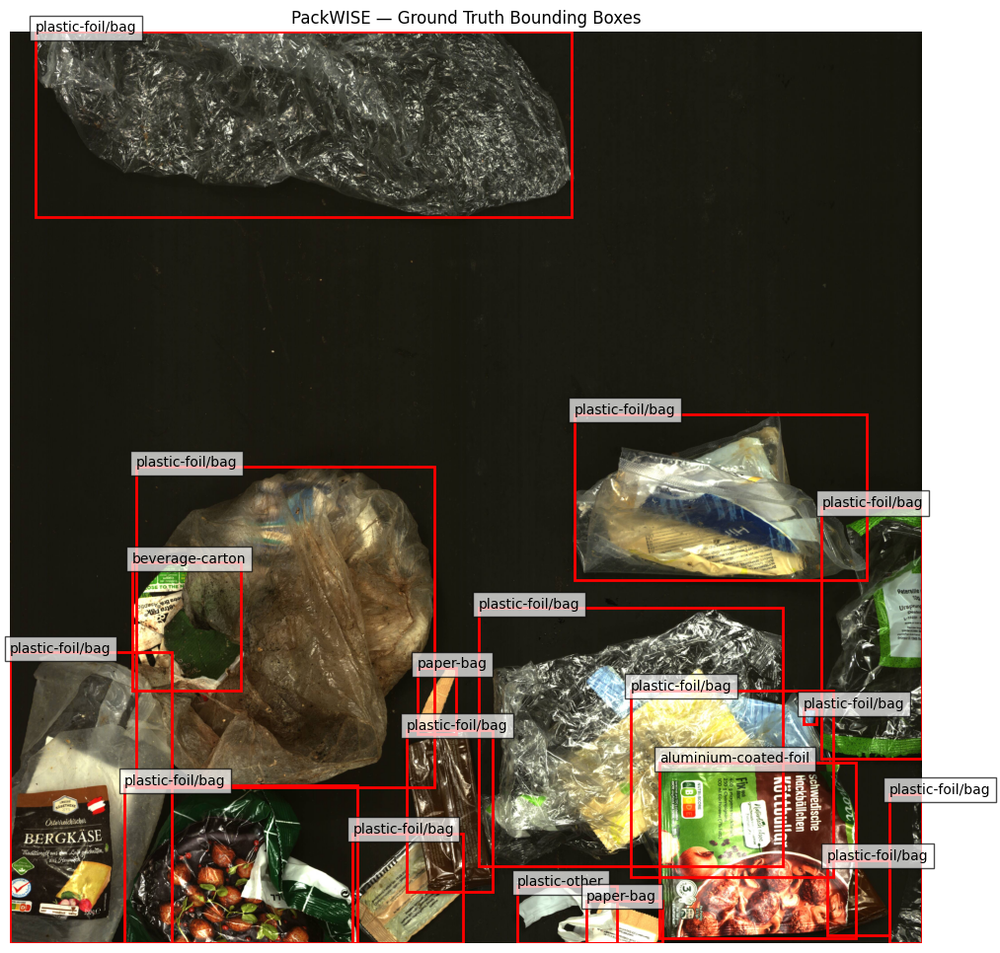

In [ ]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# First training image
image_info = train_data["images"][0]

image_id = image_info["id"]
image_name = image_info["file_name"]

image_path = os.path.join(TRAIN_DIR, image_name)

# OpenCV -> RGB
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Category ID -> Name
category_map = {
    cat["id"]: cat["name"]
    for cat in train_data["categories"]
}

# Annotations belonging to this image
annotations = [
    ann for ann in train_data["annotations"]
    if ann["image_id"] == image_id
]

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(image)

for ann in annotations:

    x, y, w, h = ann["bbox"]

    rectangle = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rectangle)

    class_name = category_map[ann["category_id"]]

    ax.text(
        x,
        y,
        class_name,
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.7)
    )

ax.axis("off")
plt.title("PackWISE — Ground Truth Bounding Boxes")
plt.show()

In [ ]:
%cd /content/PackWISE

!python convert_dataset_to_yolo_format.py

/content/PackWISE
generated YOLO text files in the folders train, val, and test.
generated yaml file at: /content/PackWISE/data/yolo.yaml


In [ ]:
with open("/content/PackWISE/data/yolo.yaml", "r") as f:
    print(f.read())

names:
  0: undefined
  1: plastic-foil/bag
  2: aluminium-coated-foil
  3: paper-bag
  4: beverage-carton
  5: plastic-other
  6: plastic-lid
  7: plastic-cup/pot
  8: blister
  9: metal-can
  10: metal-foil
  11: net
  12: metal-lid
  13: tissue
  14: wood
  15: paper-other
  16: foamed-plastic
  17: textile
  18: plastic-bottle
  19: ribbon/tape
  20: metal-other
  21: tube
  22: paper-cup/pot
path: /content/PackWISE/data
train: train
val: val



In [ ]:
import os

train_files = os.listdir("/content/PackWISE/data/train")

jpg_files = [f for f in train_files if f.endswith(".jpg")]
txt_files = [f for f in train_files if f.endswith(".txt")]

print("Training images:", len(jpg_files))
print("YOLO label files:", len(txt_files))

print("\nExample label files:")
print(txt_files[:5])

Training images: 410
YOLO label files: 410

Example label files:
['Vollstrom1_frame00226_Probe00115_00116.txt', 'Vollstrom1_frame00012_Probe00006.txt', 'Vollstrom1_frame00024_Probe00012.txt', 'Vollstrom1_frame00198_Probe00101.txt', 'Vollstrom1_frame00022_Probe00011.txt']


In [ ]:
import os

for split in ["train", "val", "test"]:
    folder = f"/content/PackWISE/data/{split}"

    images = [f for f in os.listdir(folder) if f.endswith(".jpg")]
    labels = [f for f in os.listdir(folder) if f.endswith(".txt")]

    print(f"{split.upper()}: Images = {len(images)}, Labels = {len(labels)}")

TRAIN: Images = 410, Labels = 410
VAL: Images = 88, Labels = 88
TEST: Images = 88, Labels = 88


In [ ]:
!pip install -q ultralytics

In [ ]:
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CUDA available: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO

# Small pretrained YOLO model
model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/PackWISE/data/yolo.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/WasteSortingRuns",
    name="baseline_yolo",
    pretrained=True,
    seed=42
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PackWISE/data/yolo.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo, nbs=64, nms=None, opset=None, optimize=Fa

In [ ]:
import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/Waste_Sorting_PBL/models"
os.makedirs(SAVE_DIR, exist_ok=True)

shutil.copy(
    "/content/WasteSortingRuns/baseline_yolo/weights/best.pt",
    f"{SAVE_DIR}/baseline_yolo_best.pt"
)

shutil.copy(
    "/content/WasteSortingRuns/baseline_yolo/weights/last.pt",
    f"{SAVE_DIR}/baseline_yolo_last.pt"
)

print("Baseline weights saved successfully!")

Baseline weights saved successfully!


In [ ]:
from ultralytics import YOLO

baseline_path = "/content/drive/MyDrive/Waste_Sorting_PBL/models/baseline_yolo_best.pt"

model_final = YOLO(baseline_path)

final_results = model_final.train(
    data="/content/PackWISE/data/yolo.yaml",
    epochs=40,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=10,
    project="/content/WasteSortingRuns",
    name="final_yolo",
    seed=42,
    pretrained=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PackWISE/data/yolo.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Waste_Sorting_PBL/models/baseline_yolo_best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

In [ ]:
import os
import shutil

FINAL_DIR = "/content/drive/MyDrive/Waste_Sorting_PBL/models"
os.makedirs(FINAL_DIR, exist_ok=True)

shutil.copy(
    "/content/WasteSortingRuns/final_yolo/weights/best.pt",
    f"{FINAL_DIR}/final_yolo_best.pt"
)

print("FINAL MODEL SAVED ✅")
print(f"{FINAL_DIR}/final_yolo_best.pt")

FINAL MODEL SAVED ✅
/content/drive/MyDrive/Waste_Sorting_PBL/models/final_yolo_best.pt


In [ ]:
import yaml

yaml_path = "/content/PackWISE/data/yolo.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

data["test"] = "test"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(open(yaml_path).read())

names:
  0: undefined
  1: plastic-foil/bag
  2: aluminium-coated-foil
  3: paper-bag
  4: beverage-carton
  5: plastic-other
  6: plastic-lid
  7: plastic-cup/pot
  8: blister
  9: metal-can
  10: metal-foil
  11: net
  12: metal-lid
  13: tissue
  14: wood
  15: paper-other
  16: foamed-plastic
  17: textile
  18: plastic-bottle
  19: ribbon/tape
  20: metal-other
  21: tube
  22: paper-cup/pot
path: /content/PackWISE/data
train: train
val: val
test: test



In [ ]:
from ultralytics import YOLO

FINAL_MODEL = "/content/drive/MyDrive/Waste_Sorting_PBL/models/final_yolo_best.pt"

model = YOLO(FINAL_MODEL)

print("Final YOLO model loaded successfully ✅")

Final YOLO model loaded successfully ✅


In [ ]:
test_results = model.val(
    data="/content/PackWISE/data/yolo.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/WasteSortingRuns",
    name="final_test"
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,602,397 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2944.4±473.6 MB/s, size: 687.6 KB)
val: Scanning /content/PackWISE/data/test... 88 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 88/88 1.4Kit/s 0.1s
val: New cache created: /content/PackWISE/data/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.1it/s 9.8s
                   all         88       1054      0.389      0.365      0.313      0.264
             undefined         42         83       0.35      0.265      0.253      0.161
      plastic-foil/bag         78        354      0.386      0.729      0.578      0.435
 aluminium-coated-foil         39         73      0.305      0.603       0.36      0.288
             paper-bag         16         20      0.106        0.1     0.0287     0.026

In [ ]:
print("\n===== FINAL TEST RESULTS =====")
print(f"Precision    : {test_results.box.mp:.4f}")
print(f"Recall       : {test_results.box.mr:.4f}")
print(f"mAP@50       : {test_results.box.map50:.4f}")
print(f"mAP@50-95    : {test_results.box.map:.4f}")


===== FINAL TEST RESULTS =====
Precision    : 0.3893
Recall       : 0.3647
mAP@50       : 0.3132
mAP@50-95    : 0.2640


In [ ]:
import shutil
import os

src = "/content/WasteSortingRuns/final_test"
dst = "/content/drive/MyDrive/Waste_Sorting_PBL/results/final_test"

os.makedirs(os.path.dirname(dst), exist_ok=True)

if os.path.exists(dst):
    shutil.rmtree(dst)

shutil.copytree(src, dst)

print("Test results saved to Drive ✅")

Test results saved to Drive ✅


In [ ]:
from ultralytics import YOLO
import os
import random
import matplotlib.pyplot as plt
import cv2

model = YOLO(
    "/content/drive/MyDrive/Waste_Sorting_PBL/models/final_yolo_best.pt"
)

TEST_DIR = "/content/PackWISE/data/test"

test_images = [
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith(".jpg")
]

random.seed(42)
sample_images = random.sample(test_images, 3)

results = model.predict(
    source=sample_images,
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/WasteSortingRuns",
    name="sample_predictions"
)

print("Predictions complete ✅")


0: 640x640 2 plastic-foil/bags, 1 beverage-carton, 2 plastic-lids, 1 plastic-cup/pot, 1 blister, 2 tissues, 1 paper-other, 5.9ms
1: 640x640 1 undefined, 3 plastic-foil/bags, 1 plastic-other, 1 plastic-cup/pot, 5.9ms
2: 640x640 4 plastic-foil/bags, 5.9ms
Speed: 3.8ms preprocess, 5.9ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/WasteSortingRuns/sample_predictions
Predictions complete ✅


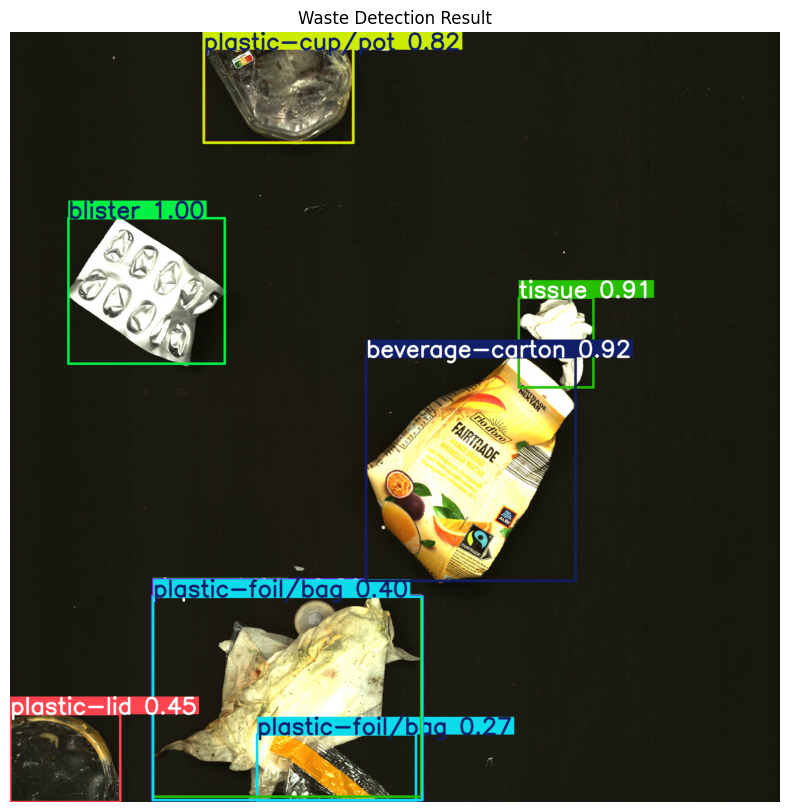

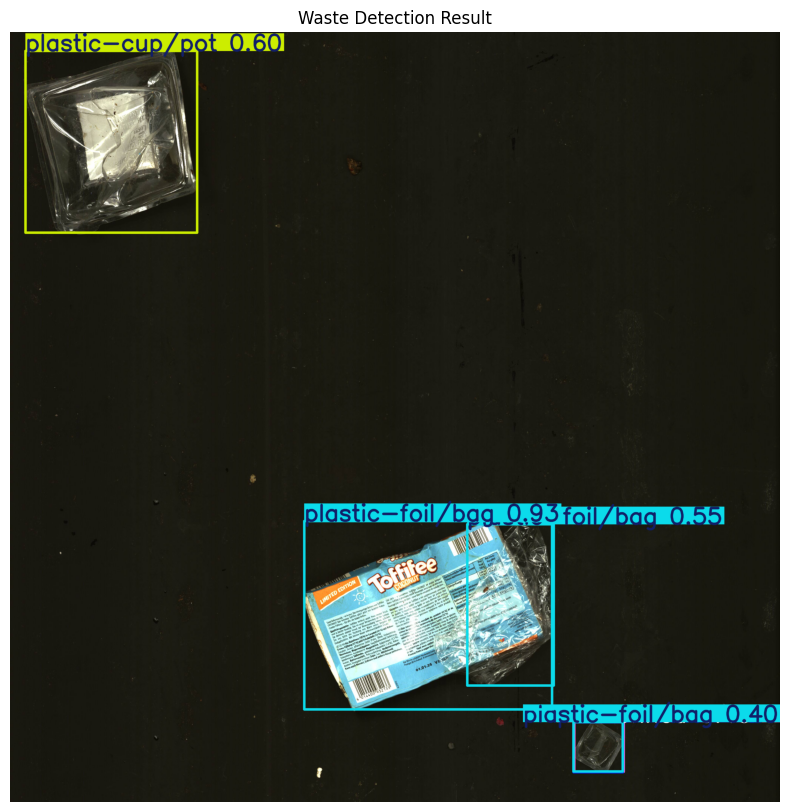

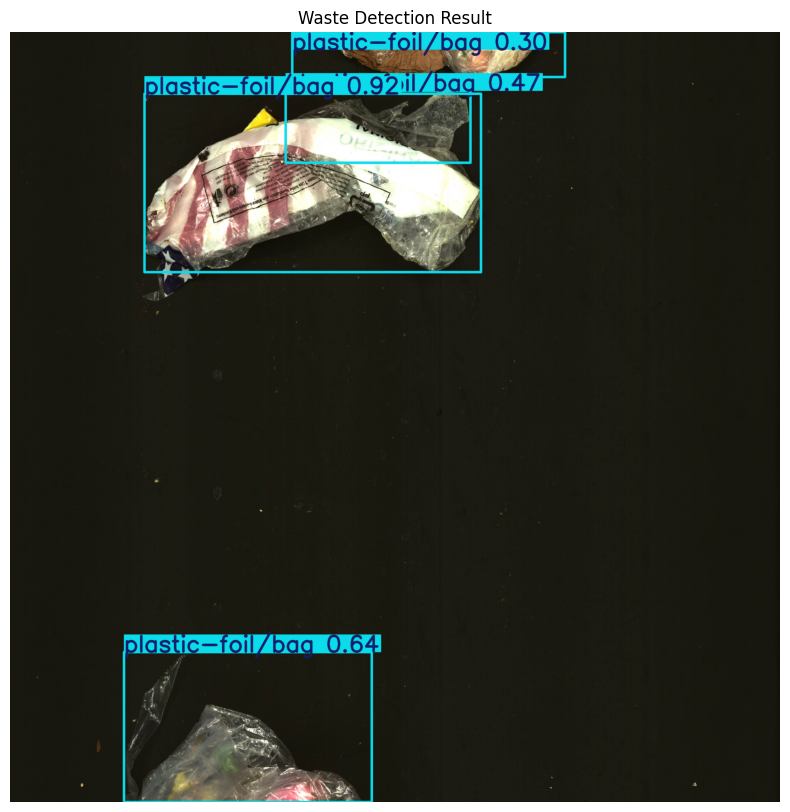

In [ ]:
for result in results:

    plotted = result.plot()

    plotted = cv2.cvtColor(
        plotted,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 10))
    plt.imshow(plotted)
    plt.axis("off")
    plt.title("Waste Detection Result")
    plt.show()

In [ ]:
!pip install -q pycocotools

In [ ]:
import json
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

from pycocotools import mask as mask_utils

TRAIN_JSON = "/content/PackWISE/data/train.json"
TRAIN_DIR = "/content/PackWISE/data/train"

with open(TRAIN_JSON, "r") as f:
    coco = json.load(f)

category_map = {
    c["id"]: c["name"]
    for c in coco["categories"]
}

# Find an image that has annotations
image_info = coco["images"][0]
image_id = image_info["id"]

anns = [
    ann for ann in coco["annotations"]
    if ann["image_id"] == image_id
]

print("Image:", image_info["file_name"])
print("Number of objects:", len(anns))

for ann in anns[:5]:
    print(
        category_map[ann["category_id"]],
        "| bbox:", ann["bbox"],
        "| segmentation type:", type(ann["segmentation"])
    )

Image: Vollstrom1_frame00012_Probe00006.jpg
Number of objects: 18
plastic-foil/bag | bbox: [2788, 2960, 907, 840] | segmentation type: <class 'dict'>
paper-bag | bbox: [1829, 2859, 175, 297] | segmentation type: <class 'dict'>
plastic-foil/bag | bbox: [3668, 3722, 280, 336] | segmentation type: <class 'dict'>
plastic-foil/bag | bbox: [3947, 3425, 148, 670] | segmentation type: <class 'dict'>
plastic-foil/bag | bbox: [1539, 3602, 493, 493] | segmentation type: <class 'dict'>


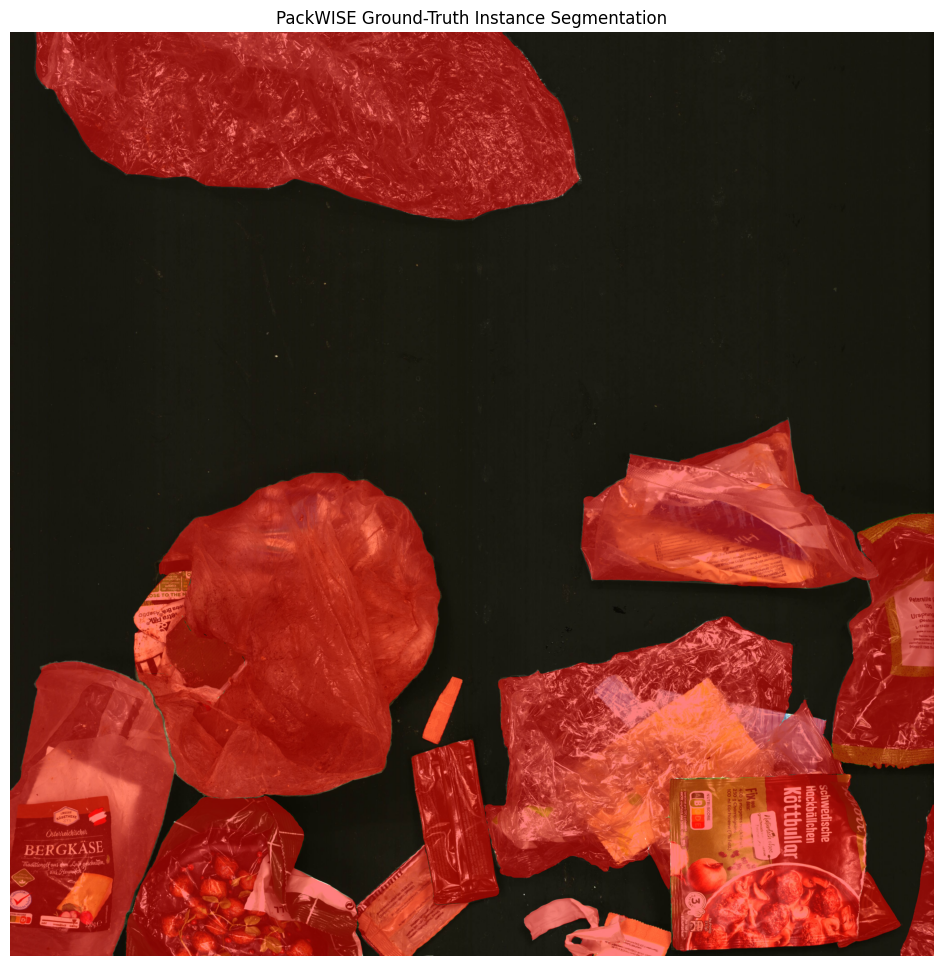

In [ ]:
image_path = os.path.join(
    TRAIN_DIR,
    image_info["file_name"]
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

overlay = image.copy()

for ann in anns:

    segmentation = ann["segmentation"]

    # PackWISE masks are COCO RLE
    mask = mask_utils.decode(segmentation)

    if mask.ndim == 3:
        mask = mask[:, :, 0]

    # Random visible overlay
    overlay[mask.astype(bool)] = (
        0.5 * overlay[mask.astype(bool)]
        + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

plt.figure(figsize=(12, 12))
plt.imshow(overlay)
plt.axis("off")
plt.title("PackWISE Ground-Truth Instance Segmentation")
plt.show()

In [ ]:
from ultralytics.data.converter import convert_coco
import os

SEG_ROOT = "/content/PackWISE_Segmentation"

os.makedirs(SEG_ROOT, exist_ok=True)

print("Segmentation workspace created ✅")

Segmentation workspace created ✅


In [ ]:
import os
import shutil

ANN_DIR = "/content/PackWISE_Segmentation/annotations"
os.makedirs(ANN_DIR, exist_ok=True)

shutil.copy(
    "/content/PackWISE/data/train.json",
    f"{ANN_DIR}/instances_train.json"
)

shutil.copy(
    "/content/PackWISE/data/val.json",
    f"{ANN_DIR}/instances_val.json"
)

print("COCO annotations copied ✅")

COCO annotations copied ✅


In [ ]:
from ultralytics.data.converter import convert_coco

convert_coco(
    labels_dir="/content/PackWISE_Segmentation/annotations",
    save_dir="/content/PackWISE_Segmentation/converted",
    use_segments=True,
    use_keypoints=False,
    cls91to80=False
)

print("Segmentation conversion complete ✅")

requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 401ms
Prepared 1 package in 315ms
Installed 1 package in 5ms
 + faster-coco-eval==1.8.0

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Annotations /content/PackWISE_Segmentation/annotations/instances_train.json: 100% ━━━━━━━━━━━━ 390/390 1.8s/it 12:00
Annotations /content/PackWISE_Segmentation/annotations/instances_val.json: 100% ━━━━━━━━━━━━ 84/84 1.7s/it 2:19
COCO data converted successfully.
Results saved to /content/PackWISE_Segmentation/converted
Segmentation conversion complete ✅


In [ ]:
import os

BASE = "/content/PackWISE_Segmentation/converted"

for root, dirs, files in os.walk(BASE):
    level = root.replace(BASE, "").count(os.sep)

    if level <= 4:
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:8]:
            print(f"{indent}  {file}")

converted/
  labels/
    val/
      Vollstrom2_frame00116_Probe00059.txt
      Vollstrom2_frame00054_Probe00027_00028.txt
      Vollstrom2_frame00106_Probe00054.txt
      Vollstrom2_frame00175_Probe00089_00090.txt
      Vollstrom6_frame00020_Probe00010.txt
      Vollstrom1_frame00206_Probe00105.txt
      Vollstrom2_frame00070_Probe00035_00036.txt
      Vollstrom2_frame00153_Probe00078.txt
    train/
      Vollstrom1_frame00226_Probe00115_00116.txt
      Vollstrom1_frame00012_Probe00006.txt
      Vollstrom1_frame00024_Probe00012.txt
      Vollstrom1_frame00198_Probe00101.txt
      Vollstrom1_frame00022_Probe00011.txt
      Vollstrom2_frame00065_Probe00033.txt
      Vollstrom6_frame00029_Probe00014_00015.txt
      Vollstrom1_frame00216_Probe00110_00111.txt
  images/


In [ ]:
import os

for root, dirs, files in os.walk(
    "/content/PackWISE_Segmentation/converted"
):
    txts = [f for f in files if f.endswith(".txt")]

    if txts:
        print(root, "->", len(txts), "label files")

/content/PackWISE_Segmentation/converted/labels/val -> 84 label files
/content/PackWISE_Segmentation/converted/labels/train -> 390 label files


In [ ]:
import os
import shutil

SEG_BASE = "/content/PackWISE_Segmentation/converted"

SEG_TRAIN_IMAGES = os.path.join(SEG_BASE, "images", "train")
SEG_VAL_IMAGES = os.path.join(SEG_BASE, "images", "val")

os.makedirs(SEG_TRAIN_IMAGES, exist_ok=True)
os.makedirs(SEG_VAL_IMAGES, exist_ok=True)

original_train = "/content/PackWISE/data/train"
original_val = "/content/PackWISE/data/val"

# Copy training images that have segmentation labels
train_labels = os.listdir(os.path.join(SEG_BASE, "labels", "train"))

for label in train_labels:
    image_name = os.path.splitext(label)[0] + ".jpg"
    src = os.path.join(original_train, image_name)
    dst = os.path.join(SEG_TRAIN_IMAGES, image_name)

    if os.path.exists(src):
        shutil.copy2(src, dst)

# Copy validation images that have segmentation labels
val_labels = os.listdir(os.path.join(SEG_BASE, "labels", "val"))

for label in val_labels:
    image_name = os.path.splitext(label)[0] + ".jpg"
    src = os.path.join(original_val, image_name)
    dst = os.path.join(SEG_VAL_IMAGES, image_name)

    if os.path.exists(src):
        shutil.copy2(src, dst)

print("Segmentation images prepared ✅")

Segmentation images prepared ✅


In [ ]:
train_img_count = len([
    f for f in os.listdir(SEG_TRAIN_IMAGES)
    if f.endswith(".jpg")
])

train_label_count = len([
    f for f in os.listdir(f"{SEG_BASE}/labels/train")
    if f.endswith(".txt")
])

val_img_count = len([
    f for f in os.listdir(SEG_VAL_IMAGES)
    if f.endswith(".jpg")
])

val_label_count = len([
    f for f in os.listdir(f"{SEG_BASE}/labels/val")
    if f.endswith(".txt")
])

print("TRAIN")
print("Images:", train_img_count)
print("Labels:", train_label_count)

print("\nVAL")
print("Images:", val_img_count)
print("Labels:", val_label_count)

TRAIN
Images: 390
Labels: 390

VAL
Images: 84
Labels: 84


In [ ]:
import yaml

class_names = [
    "undefined",
    "plastic-foil/bag",
    "aluminium-coated-foil",
    "paper-bag",
    "beverage-carton",
    "plastic-other",
    "plastic-lid",
    "plastic-cup/pot",
    "blister",
    "metal-can",
    "metal-foil",
    "net",
    "metal-lid",
    "tissue",
    "wood",
    "paper-other",
    "foamed-plastic",
    "textile",
    "plastic-bottle",
    "ribbon/tape",
    "metal-other",
    "tube",
    "paper-cup/pot"
]

seg_yaml = {
    "path": SEG_BASE,
    "train": "images/train",
    "val": "images/val",
    "names": {
        i: name for i, name in enumerate(class_names)
    }
}

SEG_YAML = os.path.join(SEG_BASE, "segmentation.yaml")

with open(SEG_YAML, "w") as f:
    yaml.safe_dump(seg_yaml, f, sort_keys=False)

print(open(SEG_YAML).read())

path: /content/PackWISE_Segmentation/converted
train: images/train
val: images/val
names:
  0: undefined
  1: plastic-foil/bag
  2: aluminium-coated-foil
  3: paper-bag
  4: beverage-carton
  5: plastic-other
  6: plastic-lid
  7: plastic-cup/pot
  8: blister
  9: metal-can
  10: metal-foil
  11: net
  12: metal-lid
  13: tissue
  14: wood
  15: paper-other
  16: foamed-plastic
  17: textile
  18: plastic-bottle
  19: ribbon/tape
  20: metal-other
  21: tube
  22: paper-cup/pot



In [ ]:
from ultralytics import YOLO

# Pretrained YOLO11 segmentation model
seg_model = YOLO("yolo11n-seg.pt")

seg_results = seg_model.train(
    data="/content/PackWISE_Segmentation/converted/segmentation.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/WasteSortingRuns",
    name="baseline_segmentation",
    pretrained=True,
    seed=42
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PackWISE_Segmentation/converted/segmentation.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_segmentation, nbs

KeyboardInterrupt: 

In [ ]:
import os

checkpoint = "/content/WasteSortingRuns/baseline_segmentation/weights/last.pt"
best = "/content/WasteSortingRuns/baseline_segmentation/weights/best.pt"

print("Last checkpoint:", os.path.exists(checkpoint))
print("Best checkpoint:", os.path.exists(best))

Last checkpoint: True
Best checkpoint: True


In [ ]:
from ultralytics import YOLO

seg_model = YOLO(
    "/content/WasteSortingRuns/baseline_segmentation/weights/last.pt"
)

seg_model.train(resume=True)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PackWISE_Segmentation/converted/segmentation.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.00037, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/WasteSortingRuns/baseline_segmentation/weights/last.pt, momentum=0.937, mosaic=1

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d4c4fec0ec0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,   

In [ ]:
import os
import shutil

MODEL_DIR = "/content/drive/MyDrive/Waste_Sorting_PBL/models"
os.makedirs(MODEL_DIR, exist_ok=True)

shutil.copy(
    "/content/WasteSortingRuns/baseline_segmentation/weights/best.pt",
    f"{MODEL_DIR}/segmentation_best.pt"
)

print("Segmentation model saved successfully ✅")

Segmentation model saved successfully ✅



image 1/1 /content/PackWISE_Segmentation/converted/images/val/Vollstrom1_frame00136_Probe00069_00070.jpg: 640x640 4 plastic-foil/bags, 1 plastic-cup/pot, 1 tissue, 1 paper-other, 11.1ms
Speed: 3.6ms preprocess, 11.1ms inference, 15.8ms postprocess per image at shape (1, 3, 640, 640)


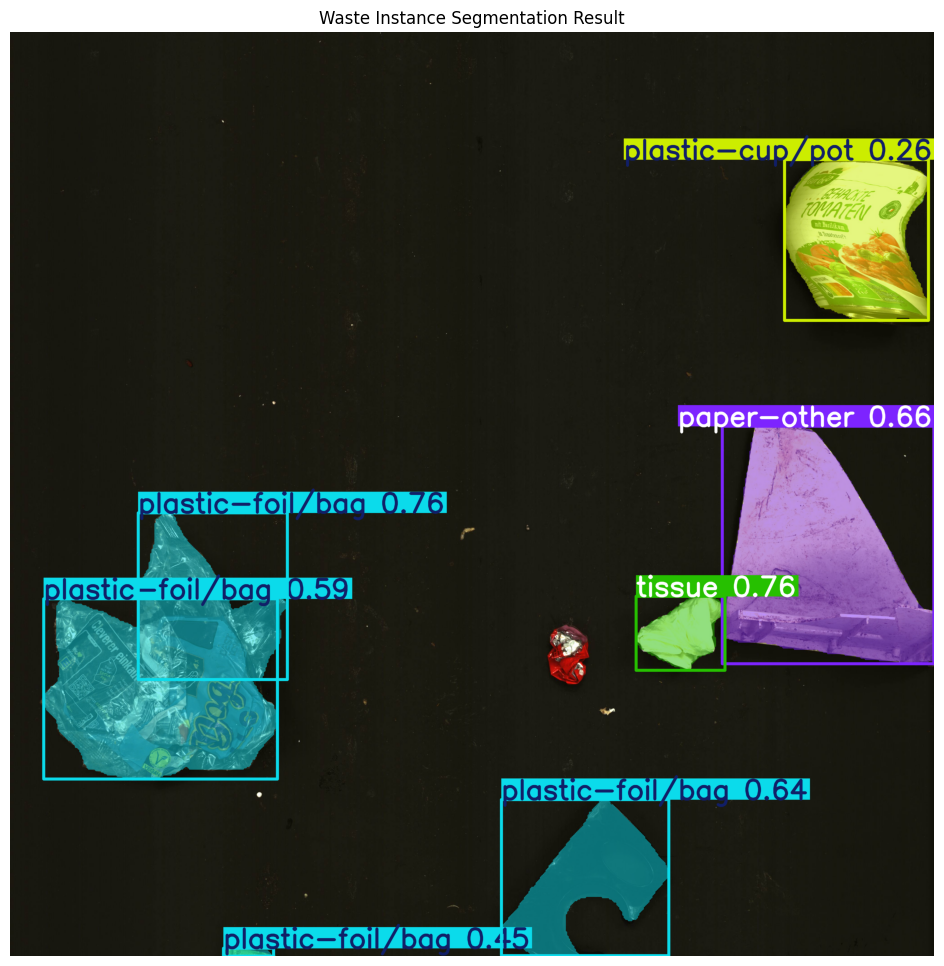

In [ ]:
from ultralytics import YOLO
import random
import os
import cv2
import matplotlib.pyplot as plt

seg_model = YOLO(
    "/content/drive/MyDrive/Waste_Sorting_PBL/models/segmentation_best.pt"
)

VAL_DIR = "/content/PackWISE_Segmentation/converted/images/val"

images = [
    os.path.join(VAL_DIR, f)
    for f in os.listdir(VAL_DIR)
    if f.lower().endswith(".jpg")
]

random.seed(42)
sample = random.choice(images)

results = seg_model.predict(
    source=sample,
    imgsz=640,
    conf=0.25,
    device=0
)

result = results[0]

output = result.plot(
    boxes=True,
    masks=True,
    labels=True
)

output = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 12))
plt.imshow(output)
plt.axis("off")
plt.title("Waste Instance Segmentation Result")
plt.show()

In [ ]:
MATERIAL_GROUPS = {
    "plastic": {
        "plastic-foil/bag",
        "plastic-other",
        "plastic-lid",
        "plastic-cup/pot",
        "foamed-plastic",
        "plastic-bottle"
    },

    "paper": {
        "paper-bag",
        "beverage-carton",
        "tissue",
        "paper-other",
        "paper-cup/pot"
    },

    "metal": {
        "aluminium-coated-foil",
        "metal-can",
        "metal-foil",
        "metal-lid",
        "metal-other"
    },

    "other": {
        "blister",
        "net",
        "wood",
        "textile",
        "ribbon/tape",
        "tube",
        "undefined"
    }
}

print("Material groups created ✅")

Material groups created ✅


In [ ]:
def get_material_group(class_name):

    for material, classes in MATERIAL_GROUPS.items():
        if class_name in classes:
            return material

    return "other"


def check_contamination(detected_classes, expected_material):

    contaminants = []

    for class_name in detected_classes:

        material = get_material_group(class_name)

        if material != expected_material:
            contaminants.append({
                "class": class_name,
                "material": material
            })

    contamination_detected = len(contaminants) > 0

    return contamination_detected, contaminants

In [ ]:
detected_classes = []

if result.boxes is not None:

    for class_id in result.boxes.cls.cpu().numpy():

        class_name = result.names[int(class_id)]

        detected_classes.append(class_name)

print("Detected objects:")

for cls in detected_classes:
    print("-", cls)

Detected objects:
- tissue
- plastic-foil/bag
- paper-other
- plastic-foil/bag
- plastic-foil/bag
- plastic-foil/bag
- plastic-cup/pot


In [ ]:
expected_material = "plastic"

contaminated, contaminants = check_contamination(
    detected_classes,
    expected_material
)

print("\nExpected recycling stream:", expected_material.upper())

if contaminated:

    print("⚠️ CONTAMINATION DETECTED")

    for item in contaminants:
        print(
            f"- {item['class']} "
            f"({item['material']})"
        )

else:

    print("✅ CLEAN RECYCLING STREAM")


Expected recycling stream: PLASTIC
⚠️ CONTAMINATION DETECTED
- tissue (paper)
- paper-other (paper)


In [ ]:
import torch
import torch.nn as nn

class WasteStreamLSTM(nn.Module):

    def __init__(self, input_size=4, hidden_size=32, num_layers=1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 2)

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        return self.fc(last_output)


lstm_model = WasteStreamLSTM().to(device)

print(lstm_model)

WasteStreamLSTM(
  (lstm): LSTM(4, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=2, bias=True)
)


In [ ]:
from ultralytics import YOLO
import os
import numpy as np

detector = YOLO(
    "/content/drive/MyDrive/Waste_Sorting_PBL/models/final_yolo_best.pt"
)

TRAIN_DIR = "/content/PackWISE/data/train"

image_paths = sorted([
    os.path.join(TRAIN_DIR, f)
    for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith(".jpg")
])

def detection_to_features(result):

    counts = {
        "plastic": 0,
        "paper": 0,
        "metal": 0,
        "other": 0
    }

    if result.boxes is not None:

        for class_id in result.boxes.cls.cpu().numpy():

            class_name = result.names[int(class_id)]
            material = get_material_group(class_name)

            counts[material] += 1

    return [
        counts["plastic"],
        counts["paper"],
        counts["metal"],
        counts["other"]
    ]


stream_features = []

for path in image_paths:

    result = detector.predict(
        path,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    features = detection_to_features(result)
    stream_features.append(features)

stream_features = np.array(stream_features, dtype=np.float32)

print("Feature matrix shape:", stream_features.shape)
print("\nFirst 10 frames:")
print(stream_features[:10])

Feature matrix shape: (410, 4)

First 10 frames:
[[         10           3           2           0]
 [          7           2           0           0]
 [          8           0           0           2]
 [          1           0           1           0]
 [          0           0           0           0]
 [          0           0           0           0]
 [          7           2           0           0]
 [         13           4           0           1]
 [          8           1           0           0]
 [          4           0           1           1]]


In [ ]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

SEQUENCE_LENGTH = 5

X_sequences = []
y_labels = []

for i in range(len(stream_features) - SEQUENCE_LENGTH + 1):

    sequence = stream_features[i:i + SEQUENCE_LENGTH]

    # Total material counts across this sequence
    totals = sequence.sum(axis=0)

    # Dominant recycling stream
    dominant_material = np.argmax(totals)

    # Everything outside dominant stream = contamination
    contamination_count = totals.sum() - totals[dominant_material]

    # Prototype label
    label = 1 if contamination_count > 0 else 0

    X_sequences.append(sequence)
    y_labels.append(label)

X_sequences = np.array(X_sequences, dtype=np.float32)
y_labels = np.array(y_labels, dtype=np.int64)

print("Sequences:", X_sequences.shape)
print("Labels:", y_labels.shape)

unique, counts = np.unique(y_labels, return_counts=True)
print("Label distribution:", dict(zip(unique, counts)))

Sequences: (406, 5, 4)
Labels: (406,)
Label distribution: {np.int64(0): np.int64(2), np.int64(1): np.int64(404)}


In [ ]:
unique, counts = np.unique(y_labels, return_counts=True)

for label, count in zip(unique, counts):
    name = "Clean" if label == 0 else "Contaminated"
    print(f"{name}: {count}")

Clean: 2
Contaminated: 404


In [ ]:
import numpy as np

SEQUENCE_LENGTH = 5

# Convert counts to proportions per observation
totals = stream_features.sum(axis=1, keepdims=True)
totals[totals == 0] = 1

normalized_features = stream_features / totals

X_sequences = []
y_targets = []

for i in range(len(normalized_features) - SEQUENCE_LENGTH):

    # Previous 5 observations
    X_sequences.append(
        normalized_features[i:i + SEQUENCE_LENGTH]
    )

    # Predict next observation
    y_targets.append(
        normalized_features[i + SEQUENCE_LENGTH]
    )

X_sequences = np.array(X_sequences, dtype=np.float32)
y_targets = np.array(y_targets, dtype=np.float32)

print("LSTM input shape:", X_sequences.shape)
print("Target shape:", y_targets.shape)

print("\nExample sequence:")
print(X_sequences[0])

print("\nNext-frame target:")
print(y_targets[0])

LSTM input shape: (405, 5, 4)
Target shape: (405, 4)

Example sequence:
[[    0.66667         0.2     0.13333           0]
 [    0.77778     0.22222           0           0]
 [        0.8           0           0         0.2]
 [        0.5           0         0.5           0]
 [          0           0           0           0]]

Next-frame target:
[          0           0           0           0]


In [ ]:
import torch
import torch.nn as nn

class WasteStreamLSTM(nn.Module):
    def __init__(self, input_size=4, hidden_size=32, num_layers=1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        # Predict 4 material proportions
        self.fc = nn.Linear(hidden_size, 4)

    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        prediction = self.fc(last_output)

        return prediction


lstm_model = WasteStreamLSTM().to(device)

print(lstm_model)

WasteStreamLSTM(
  (lstm): LSTM(4, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=4, bias=True)
)


In [ ]:
split_index = int(0.8 * len(X_sequences))

X_train = X_sequences[:split_index]
X_val = X_sequences[split_index:]

y_train = y_targets[:split_index]
y_val = y_targets[split_index:]

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

print("Training sequences:", X_train.shape)
print("Validation sequences:", X_val.shape)

Training sequences: torch.Size([324, 5, 4])
Validation sequences: torch.Size([81, 5, 4])


In [ ]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

epochs = 50

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training
    lstm_model.train()

    X_train_device = X_train.to(device)
    y_train_device = y_train.to(device)

    optimizer.zero_grad()

    predictions = lstm_model(X_train_device)

    loss = criterion(predictions, y_train_device)

    loss.backward()
    optimizer.step()

    # Validation
    lstm_model.eval()

    with torch.no_grad():

        val_predictions = lstm_model(
            X_val.to(device)
        )

        val_loss = criterion(
            val_predictions,
            y_val.to(device)
        )

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {loss.item():.4f} "
            f"Val Loss: {val_loss.item():.4f}"
        )

Epoch [10/50] Train Loss: 0.1421 Val Loss: 0.1381
Epoch [20/50] Train Loss: 0.1009 Val Loss: 0.0942
Epoch [30/50] Train Loss: 0.0647 Val Loss: 0.0573
Epoch [40/50] Train Loss: 0.0427 Val Loss: 0.0395
Epoch [50/50] Train Loss: 0.0407 Val Loss: 0.0410


In [ ]:
import torch
import numpy as np

lstm_model.eval()

with torch.no_grad():
    predictions = lstm_model(
        X_val.to(device)
    ).cpu()

mae = torch.mean(
    torch.abs(predictions - y_val)
).item()

print(f"Validation MAE: {mae:.4f}")

Validation MAE: 0.1417


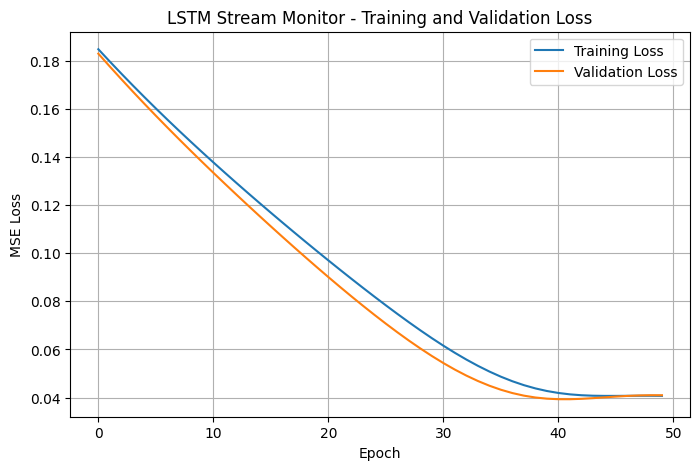

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Stream Monitor - Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [ ]:
material_names = [
    "Plastic",
    "Paper",
    "Metal",
    "Other"
]

sample_index = 0

actual = y_val[sample_index].numpy()
predicted = predictions[sample_index].numpy()

# Keep proportions non-negative
predicted = np.clip(predicted, 0, None)

print("Material      Actual     Predicted")
print("-----------------------------------")

for name, a, p in zip(
    material_names,
    actual,
    predicted
):
    print(f"{name:<12} {a:.3f}      {p:.3f}")

Material      Actual     Predicted
-----------------------------------
Plastic      0.000      0.689
Paper        0.000      0.196
Metal        0.000      0.126
Other        1.000      0.042


In [ ]:
import os
import torch

LSTM_DIR = "/content/drive/MyDrive/Waste_Sorting_PBL/models"
os.makedirs(LSTM_DIR, exist_ok=True)

torch.save(
    lstm_model.state_dict(),
    f"{LSTM_DIR}/waste_stream_lstm.pth"
)

print("LSTM model saved successfully ✅")

LSTM model saved successfully ✅


In [ ]:
import json
from collections import Counter

TRAIN_JSON = "/content/PackWISE/data/train.json"

with open(TRAIN_JSON, "r") as f:
    data = json.load(f)

category_names = {
    cat["id"]: cat["name"]
    for cat in data["categories"]
}

counts = Counter(
    ann["category_id"]
    for ann in data["annotations"]
)

print("TRAINING CATEGORY COUNTS\n")

for category_id, count in sorted(
    counts.items(),
    key=lambda x: x[1]
):
    print(
        f"{category_names[category_id]:25s} : {count}"
    )

TRAINING CATEGORY COUNTS

tube                      : 10
metal-other               : 11
paper-cup/pot             : 14
net                       : 21
wood                      : 22
textile                   : 25
ribbon/tape               : 56
metal-foil                : 56
blister                   : 63
metal-can                 : 76
plastic-bottle            : 101
plastic-lid               : 104
paper-bag                 : 105
beverage-carton           : 118
metal-lid                 : 122
foamed-plastic            : 158
aluminium-coated-foil     : 268
plastic-other             : 335
tissue                    : 335
paper-other               : 339
undefined                 : 365
plastic-cup/pot           : 454
plastic-foil/bag          : 1511


In [ ]:
RARE_THRESHOLD = 30

rare_category_ids = [
    category_id
    for category_id, count in counts.items()
    if count <= RARE_THRESHOLD
]

rare_categories = {
    category_id: category_names[category_id]
    for category_id in rare_category_ids
}

print("Rare categories:\n")

for category_id, name in rare_categories.items():
    print(
        category_id,
        "->",
        name,
        "| instances:",
        counts[category_id]
    )

Rare categories:

12 -> net | instances: 21
15 -> wood | instances: 22
18 -> textile | instances: 25
21 -> metal-other | instances: 11
22 -> tube | instances: 10
23 -> paper-cup/pot | instances: 14


In [ ]:
import os
import cv2
import json

TRAIN_IMG_DIR = "/content/PackWISE/data/train"
RARE_CROP_DIR = "/content/rare_waste_crops"

os.makedirs(RARE_CROP_DIR, exist_ok=True)

# image_id -> filename
image_map = {
    img["id"]: img["file_name"]
    for img in data["images"]
}

crop_count = 0

for ann in data["annotations"]:

    category_id = ann["category_id"]

    # Only rare categories
    if category_id not in rare_category_ids:
        continue

    image_name = image_map[ann["image_id"]]
    image_path = os.path.join(TRAIN_IMG_DIR, image_name)

    image = cv2.imread(image_path)

    if image is None:
        continue

    x, y, w, h = map(int, ann["bbox"])

    # Keep coordinates inside image
    x = max(0, x)
    y = max(0, y)

    x2 = min(image.shape[1], x + w)
    y2 = min(image.shape[0], y + h)

    crop = image[y:y2, x:x2]

    if crop.size == 0:
        continue

    class_name = category_names[category_id].replace("/", "_")

    class_dir = os.path.join(
        RARE_CROP_DIR,
        class_name
    )

    os.makedirs(class_dir, exist_ok=True)

    save_path = os.path.join(
        class_dir,
        f"{crop_count}.jpg"
    )

    cv2.imwrite(save_path, crop)

    crop_count += 1

print("Rare object crops created:", crop_count)

Rare object crops created: 103


In [ ]:
print("\nRare Crop Dataset\n")

total = 0

for folder in sorted(os.listdir(RARE_CROP_DIR)):

    folder_path = os.path.join(
        RARE_CROP_DIR,
        folder
    )

    if os.path.isdir(folder_path):

        count = len([
            f for f in os.listdir(folder_path)
            if f.endswith(".jpg")
        ])

        total += count

        print(f"{folder:25s}: {count}")

print("\nTotal crops:", total)


Rare Crop Dataset

metal-other              : 11
net                      : 21
paper-cup_pot            : 14
textile                  : 25
tube                     : 10
wood                     : 22

Total crops: 103


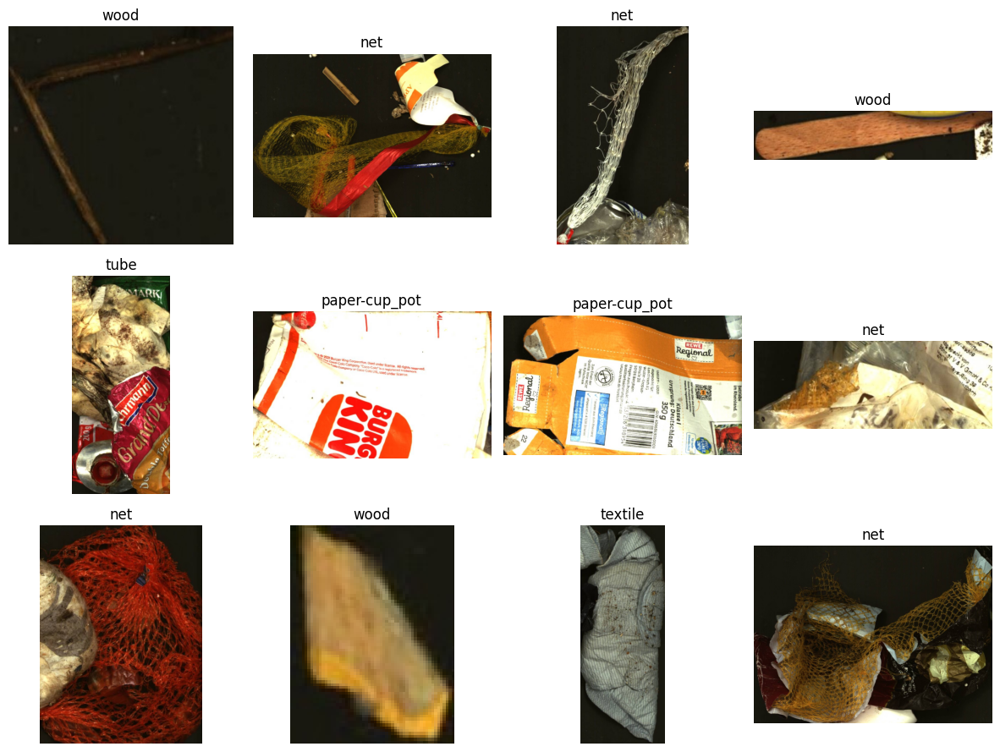

In [ ]:
import matplotlib.pyplot as plt
import random

all_crops = []

for root, dirs, files in os.walk(RARE_CROP_DIR):

    for file in files:

        if file.endswith(".jpg"):
            all_crops.append(
                os.path.join(root, file)
            )

random.seed(42)

samples = random.sample(
    all_crops,
    min(12, len(all_crops))
)

plt.figure(figsize=(12, 9))

for i, path in enumerate(samples):

    image = cv2.imread(path)
    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    class_name = os.path.basename(
        os.path.dirname(path)
    )

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

class RareWasteDataset(Dataset):

    def __init__(self, root_dir, transform=None):

        self.paths = []
        self.labels = []
        self.transform = transform

        self.classes = sorted([
            d for d in os.listdir(root_dir)
            if os.path.isdir(os.path.join(root_dir, d))
        ])

        self.class_to_idx = {
            name: i
            for i, name in enumerate(self.classes)
        }

        for class_name in self.classes:

            folder = os.path.join(root_dir, class_name)

            for file in os.listdir(folder):

                if file.lower().endswith(".jpg"):

                    self.paths.append(
                        os.path.join(folder, file)
                    )

                    self.labels.append(
                        self.class_to_idx[class_name]
                    )

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        image = Image.open(
            self.paths[idx]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, self.labels[idx]


vae_dataset = RareWasteDataset(
    "/content/rare_waste_crops",
    transform
)

vae_loader = DataLoader(
    vae_dataset,
    batch_size=16,
    shuffle=True
)

print("Total VAE images:", len(vae_dataset))
print("Rare classes:", vae_dataset.classes)

images, labels = next(iter(vae_loader))

print("Batch shape:", images.shape)

Total VAE images: 103
Rare classes: ['metal-other', 'net', 'paper-cup_pot', 'textile', 'tube', 'wood']
Batch shape: torch.Size([16, 3, 64, 64])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

LATENT_DIM = 16

class ConvVAE(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.ReLU(),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.ReLU()
        )

        # 64x64 -> 4x4
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)

        self.decoder_input = nn.Linear(
            latent_dim,
            256 * 4 * 4
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Sigmoid()
        )

    def encode(self, x):

        x = self.encoder(x)
        x = x.view(x.size(0), -1)

        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)

        return mu, logvar

    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)

        return mu + eps * std

    def decode(self, z):

        x = self.decoder_input(z)

        x = x.view(
            -1,
            256,
            4,
            4
        )

        return self.decoder(x)

    def forward(self, x):

        mu, logvar = self.encode(x)

        z = self.reparameterize(
            mu,
            logvar
        )

        reconstructed = self.decode(z)

        return reconstructed, mu, logvar


vae = ConvVAE(
    latent_dim=LATENT_DIM
).to(device)

print(vae)

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
  )
  (fc_mu): Linear(in_features=4096, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=4096, out_features=16, bias=True)
  (decoder_input): Linear(in_features=16, out_features=4096, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2

In [ ]:
def vae_loss(reconstructed, original, mu, logvar):

    reconstruction_loss = F.mse_loss(
        reconstructed,
        original,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + kl_loss

In [ ]:
optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=0.001
)

VAE_EPOCHS = 40
vae_losses = []

for epoch in range(VAE_EPOCHS):

    vae.train()
    total_loss = 0

    for images, _ in vae_loader:

        images = images.to(device)

        optimizer.zero_grad()

        reconstructed, mu, logvar = vae(images)

        loss = vae_loss(
            reconstructed,
            images,
            mu,
            logvar
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(vae_dataset)
    vae_losses.append(average_loss)

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch [{epoch+1}/{VAE_EPOCHS}] "
            f"Loss: {average_loss:.4f}"
        )

Epoch [5/40] Loss: 864.6630
Epoch [10/40] Loss: 647.0742
Epoch [15/40] Loss: 536.1405
Epoch [20/40] Loss: 401.4832
Epoch [25/40] Loss: 355.7453
Epoch [30/40] Loss: 311.2165
Epoch [35/40] Loss: 264.7115
Epoch [40/40] Loss: 249.8564


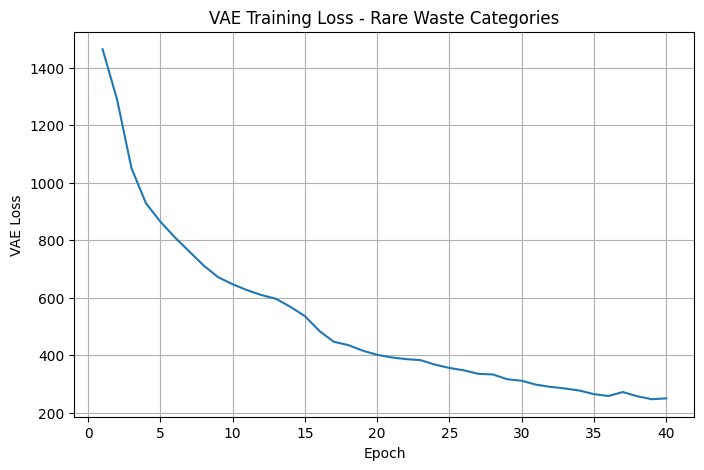

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(range(1, VAE_EPOCHS + 1), vae_losses)

plt.xlabel("Epoch")
plt.ylabel("VAE Loss")
plt.title("VAE Training Loss - Rare Waste Categories")
plt.grid()

plt.show()

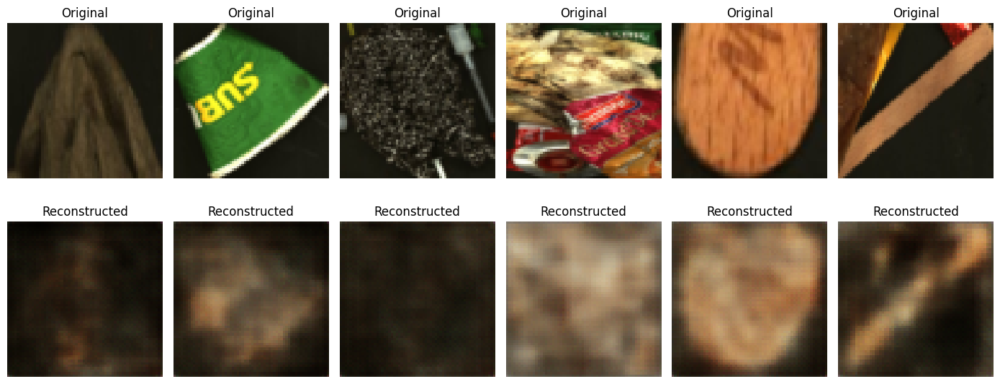

In [ ]:
vae.eval()

images, labels = next(iter(vae_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed, mu, logvar = vae(images)

images = images.cpu()
reconstructed = reconstructed.cpu()

plt.figure(figsize=(14, 6))

for i in range(min(6, len(images))):

    # Original
    plt.subplot(2, 6, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title("Original")
    plt.axis("off")

    # Reconstruction
    plt.subplot(2, 6, i + 7)
    plt.imshow(reconstructed[i].permute(1, 2, 0))
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

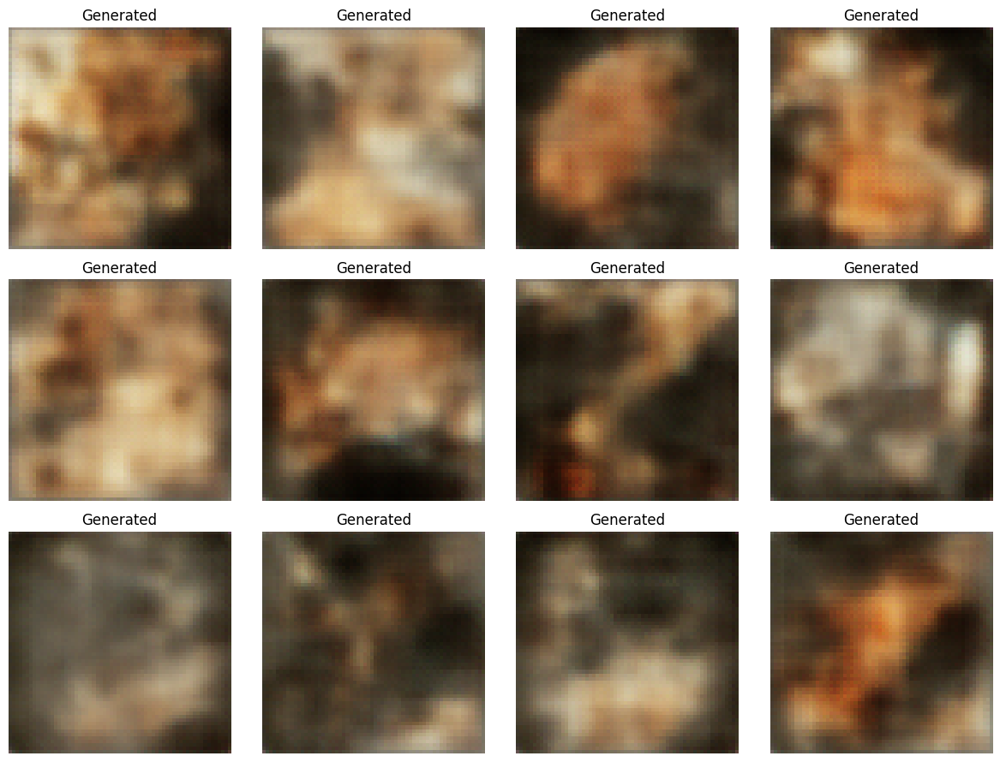

In [ ]:
vae.eval()

with torch.no_grad():

    z = torch.randn(
        12,
        LATENT_DIM
    ).to(device)

    generated = vae.decode(z).cpu()

plt.figure(figsize=(12, 9))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        generated[i].permute(1, 2, 0)
    )

    plt.axis("off")
    plt.title("Generated")

plt.tight_layout()
plt.show()

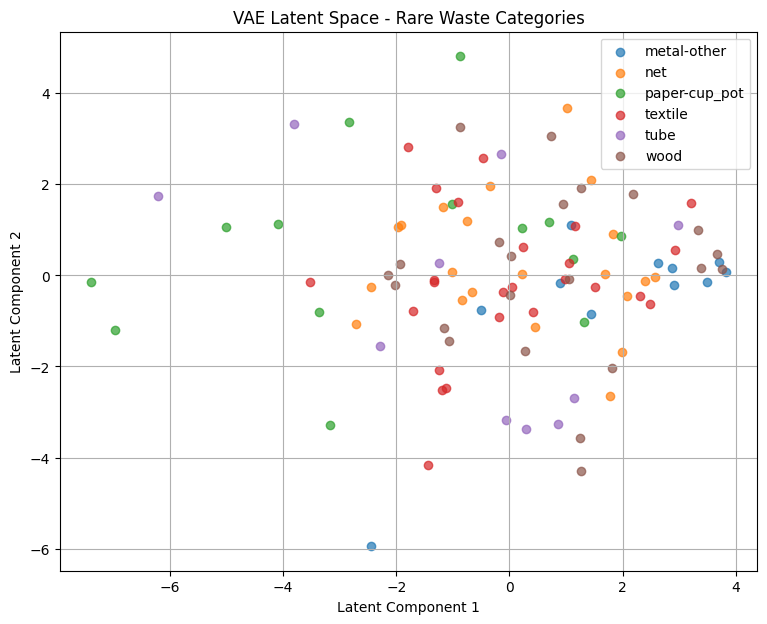

In [ ]:
from sklearn.decomposition import PCA
import numpy as np

vae.eval()

latent_vectors = []
latent_labels = []

with torch.no_grad():

    for images, labels in vae_loader:

        images = images.to(device)

        mu, logvar = vae.encode(images)

        latent_vectors.append(
            mu.cpu().numpy()
        )

        latent_labels.extend(
            labels.numpy()
        )

latent_vectors = np.concatenate(
    latent_vectors,
    axis=0
)

latent_labels = np.array(latent_labels)

pca = PCA(n_components=2)

latent_2d = pca.fit_transform(
    latent_vectors
)

plt.figure(figsize=(9, 7))

for class_index, class_name in enumerate(
    vae_dataset.classes
):

    mask = latent_labels == class_index

    plt.scatter(
        latent_2d[mask, 0],
        latent_2d[mask, 1],
        label=class_name,
        alpha=0.7
    )

plt.xlabel("Latent Component 1")
plt.ylabel("Latent Component 2")
plt.title("VAE Latent Space - Rare Waste Categories")

plt.legend()
plt.grid()

plt.show()

In [ ]:
import os
import torch

MODEL_DIR = "/content/drive/MyDrive/Waste_Sorting_PBL/models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

torch.save(
    vae.state_dict(),
    f"{MODEL_DIR}/rare_waste_vae.pth"
)

print("VAE model saved successfully ✅")

VAE model saved successfully ✅


In [ ]:
import os

APP_DIR = "/content/WasteSortingApp"

folders = [
    APP_DIR,
    f"{APP_DIR}/models",
    f"{APP_DIR}/src",
    f"{APP_DIR}/outputs"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Application folders created ✅")

Application folders created ✅


In [ ]:
import shutil
import os

models_to_copy = {
    "/content/drive/MyDrive/Waste_Sorting_PBL/models/final_yolo_best.pt":
        f"{APP_DIR}/models/detection.pt",

    "/content/drive/MyDrive/Waste_Sorting_PBL/models/segmentation_best.pt":
        f"{APP_DIR}/models/segmentation.pt",

    "/content/drive/MyDrive/Waste_Sorting_PBL/models/waste_stream_lstm.pth":
        f"{APP_DIR}/models/lstm.pth",

    "/content/drive/MyDrive/Waste_Sorting_PBL/models/rare_waste_vae.pth":
        f"{APP_DIR}/models/vae.pth"
}

for src, dst in models_to_copy.items():

    if os.path.exists(src):
        shutil.copy2(src, dst)
        print("✅", os.path.basename(dst))
    else:
        print("❌ MISSING:", src)

✅ detection.pt
✅ segmentation.pt
✅ lstm.pth
✅ vae.pth


In [ ]:
%%writefile /content/WasteSortingApp/src/quality_controller.py

MATERIAL_GROUPS = {
    "plastic": {
        "plastic-foil/bag",
        "plastic-other",
        "plastic-lid",
        "plastic-cup/pot",
        "foamed-plastic",
        "plastic-bottle"
    },

    "paper": {
        "paper-bag",
        "beverage-carton",
        "tissue",
        "paper-other",
        "paper-cup/pot"
    },

    "metal": {
        "aluminium-coated-foil",
        "metal-can",
        "metal-foil",
        "metal-lid",
        "metal-other"
    },

    "other": {
        "blister",
        "net",
        "wood",
        "textile",
        "ribbon/tape",
        "tube",
        "undefined"
    }
}


def get_material_group(class_name):

    for material, classes in MATERIAL_GROUPS.items():
        if class_name in classes:
            return material

    return "other"


def check_contamination(detections, expected_material):

    contaminants = []

    for item in detections:

        material = get_material_group(item["class"])

        if material != expected_material:

            contaminants.append({
                "class": item["class"],
                "material": material,
                "confidence": item["confidence"]
            })

    return len(contaminants) > 0, contaminants

Writing /content/WasteSortingApp/src/quality_controller.py


In [ ]:
%%writefile /content/WasteSortingApp/src/inference.py

from ultralytics import YOLO
import cv2
import time

from src.quality_controller import (
    get_material_group,
    check_contamination
)


class WasteSortingSystem:

    def __init__(
        self,
        detection_model,
        segmentation_model
    ):

        self.detector = YOLO(detection_model)
        self.segmenter = YOLO(segmentation_model)


    def analyze(
        self,
        image_path,
        expected_material="plastic",
        confidence=0.25
    ):

        start_time = time.time()

        # -----------------------
        # Object Detection
        # -----------------------

        det_result = self.detector.predict(
            source=image_path,
            conf=confidence,
            imgsz=640,
            verbose=False
        )[0]

        detections = []

        if det_result.boxes is not None:

            for box in det_result.boxes:

                class_id = int(box.cls[0].item())

                class_name = det_result.names[
                    class_id
                ]

                conf = float(
                    box.conf[0].item()
                )

                detections.append({
                    "class": class_name,
                    "material":
                        get_material_group(
                            class_name
                        ),
                    "confidence": conf
                })

        # -----------------------
        # Contamination
        # -----------------------

        contaminated, contaminants = (
            check_contamination(
                detections,
                expected_material
            )
        )

        # -----------------------
        # Segmentation
        # -----------------------

        seg_result = self.segmenter.predict(
            source=image_path,
            conf=confidence,
            imgsz=640,
            verbose=False
        )[0]

        segmented_image = seg_result.plot(
            boxes=True,
            masks=True,
            labels=True
        )

        segmented_image = cv2.cvtColor(
            segmented_image,
            cv2.COLOR_BGR2RGB
        )

        processing_time = (
            time.time() - start_time
        )

        return {
            "detections": detections,

            "object_count":
                len(detections),

            "contaminated":
                contaminated,

            "contaminants":
                contaminants,

            "segmented_image":
                segmented_image,

            "processing_time":
                processing_time
        }

Writing /content/WasteSortingApp/src/inference.py


In [ ]:
import sys
import os
import random

sys.path.insert(
    0,
    "/content/WasteSortingApp"
)

from src.inference import WasteSortingSystem

system = WasteSortingSystem(
    detection_model=
        "/content/WasteSortingApp/models/detection.pt",

    segmentation_model=
        "/content/WasteSortingApp/models/segmentation.pt"
)

TEST_DIR = "/content/PackWISE/data/test"

test_images = [
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith(".jpg")
]

random.seed(10)

test_image = random.choice(
    test_images
)

result = system.analyze(
    test_image,
    expected_material="plastic",
    confidence=0.25
)

print("Objects detected:", result["object_count"])
print("Contamination:", result["contaminated"])
print(
    "Processing time:",
    round(result["processing_time"], 3),
    "seconds"
)

print("\nDETECTIONS")

for item in result["detections"]:
    print(
        item["class"],
        "|",
        item["material"],
        "|",
        round(item["confidence"], 3)
    )

print("\nCONTAMINANTS")

for item in result["contaminants"]:
    print(
        item["class"],
        "->",
        item["material"]
    )

Objects detected: 9
Contamination: True
Processing time: 0.955 seconds

DETECTIONS
plastic-foil/bag | plastic | 0.943
metal-can | metal | 0.711
plastic-foil/bag | plastic | 0.599
plastic-cup/pot | plastic | 0.547
paper-other | paper | 0.495
ribbon/tape | other | 0.455
plastic-foil/bag | plastic | 0.393
plastic-foil/bag | plastic | 0.372
plastic-lid | plastic | 0.288

CONTAMINANTS
metal-can -> metal
paper-other -> paper
ribbon/tape -> other


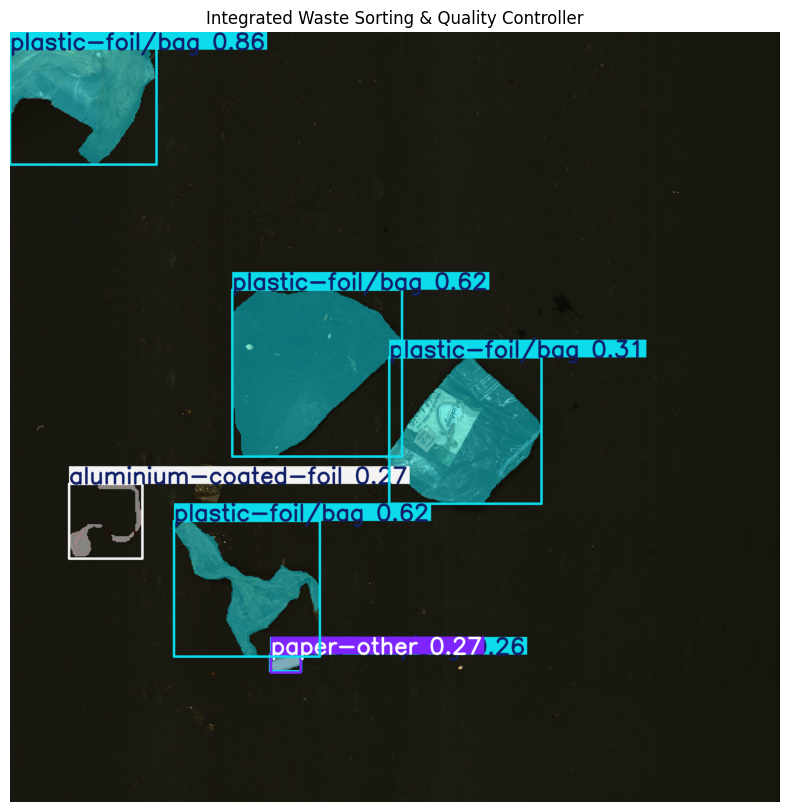

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.imshow(
    result["segmented_image"]
)

plt.axis("off")

plt.title(
    "Integrated Waste Sorting & Quality Controller"
)

plt.show()

In [ ]:
!pip install -q streamlit

In [ ]:
%%writefile /content/WasteSortingApp/app.py

import streamlit as st
import tempfile
import os
import sys
import pandas as pd
from PIL import Image

sys.path.insert(0, os.path.dirname(__file__))

from src.inference import WasteSortingSystem


st.set_page_config(
    page_title="Waste Sorting AI",
    page_icon="♻️",
    layout="wide"
)


@st.cache_resource
def load_system():
    return WasteSortingSystem(
        detection_model="models/detection.pt",
        segmentation_model="models/segmentation.pt"
    )


system = load_system()


st.title("♻️ Waste Sorting & Recycling Quality Controller")

st.write(
    "Deep Learning based waste detection, instance segmentation "
    "and recycling contamination analysis."
)

st.divider()


# -------------------------
# Sidebar
# -------------------------

st.sidebar.header("⚙️ Analysis Settings")

expected_material = st.sidebar.selectbox(
    "Expected Recycling Stream",
    ["plastic", "paper", "metal"]
)

confidence = st.sidebar.slider(
    "Confidence Threshold",
    min_value=0.10,
    max_value=0.90,
    value=0.25,
    step=0.05
)


# -------------------------
# Upload
# -------------------------

uploaded_file = st.file_uploader(
    "Upload a waste image",
    type=["jpg", "jpeg", "png"]
)


if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    col1, col2 = st.columns(2)

    with col1:

        st.subheader("Original Image")

        st.image(
            image,
            use_container_width=True
        )


    if st.button(
        "🔍 Analyze Waste",
        type="primary"
    ):

        with st.spinner(
            "Running deep-learning analysis..."
        ):

            with tempfile.NamedTemporaryFile(
                delete=False,
                suffix=".jpg"
            ) as temp:

                image.save(temp.name)

                result = system.analyze(
                    temp.name,
                    expected_material=expected_material,
                    confidence=confidence
                )

            os.unlink(temp.name)


        # -------------------------
        # Segmentation result
        # -------------------------

        with col2:

            st.subheader("AI Analysis")

            st.image(
                result["segmented_image"],
                use_container_width=True
            )


        st.divider()


        # -------------------------
        # Metrics
        # -------------------------

        m1, m2, m3 = st.columns(3)

        m1.metric(
            "Objects Detected",
            result["object_count"]
        )

        m2.metric(
            "Processing Time",
            f'{result["processing_time"]:.2f} sec'
        )

        m3.metric(
            "Expected Stream",
            expected_material.upper()
        )


        # -------------------------
        # Quality Control
        # -------------------------

        st.subheader(
            "♻️ Recycling Quality Control"
        )

        if result["contaminated"]:

            st.error(
                "⚠️ CONTAMINATION DETECTED"
            )

            st.write(
                "The following materials do not belong "
                f"to the selected {expected_material} stream:"
            )

            for item in result["contaminants"]:

                st.write(
                    f'• **{item["class"]}** '
                    f'→ {item["material"]} '
                    f'({item["confidence"]:.1%})'
                )

        else:

            st.success(
                "✅ CLEAN RECYCLING STREAM"
            )


        # -------------------------
        # Detection table
        # -------------------------

        st.subheader(
            "🔎 Detected Waste Objects"
        )

        if result["detections"]:

            table_data = []

            for item in result["detections"]:

                table_data.append({
                    "Waste Type":
                        item["class"],

                    "Material":
                        item["material"].title(),

                    "Confidence":
                        round(
                            item["confidence"] * 100,
                            2
                        )
                })

            dataframe = pd.DataFrame(
                table_data
            )

            st.dataframe(
                dataframe,
                use_container_width=True
            )

        else:

            st.warning(
                "No waste objects detected."
            )


        st.divider()

        st.caption(
            "Waste Sorting and Recycling Quality Controller | "
            "Deep Learning PBL"
        )

Writing /content/WasteSortingApp/app.py


In [ ]:
%%writefile /content/WasteSortingApp/requirements.txt

streamlit
ultralytics
torch
torchvision
opencv-python-headless
pandas
numpy
Pillow

Writing /content/WasteSortingApp/requirements.txt


In [ ]:
!python -m py_compile /content/WasteSortingApp/app.py
!python -m py_compile /content/WasteSortingApp/src/inference.py
!python -m py_compile /content/WasteSortingApp/src/quality_controller.py

print("Application syntax check PASSED ✅")

Application syntax check PASSED ✅


In [ ]:
%cd /content/WasteSortingApp
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

/content/WasteSortingApp


In [ ]:
import requests
import time

time.sleep(5)

try:
    response = requests.get("http://localhost:8501")
    print("Status:", response.status_code)

    if response.status_code == 200:
        print("Streamlit application is running ✅")
except Exception as e:
    print("Error:", e)

Status: 200
Streamlit application is running ✅


In [ ]:
!cloudflared tunnel --url http://localhost:8501 > /content/cloudflared.log 2>&1 &

In [ ]:
import time
import re

time.sleep(8)

with open("/content/cloudflared.log", "r") as f:
    log = f.read()

urls = re.findall(
    r"https://[a-zA-Z0-9.-]+\.trycloudflare\.com",
    log
)

if urls:
    print("♻️ YOUR WASTE SORTING APP:")
    print(urls[-1])
else:
    print(log)

♻️ YOUR WASTE SORTING APP:
https://handle-makers-ontario-funeral.trycloudflare.com


In [ ]:
import os
from google.colab import files

TEST_DIR = "/content/PackWISE/data/test"

test_images = [
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith(".jpg")
]

sample_path = os.path.join(
    TEST_DIR,
    test_images[0]
)

print("Downloading:", sample_path)

files.download(sample_path)

Downloading: /content/PackWISE/data/test/Vollstrom1_frame00227_Probe00116.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile /content/WasteSortingApp/app.py

import streamlit as st
import tempfile
import os
import sys
import pandas as pd
from PIL import Image
from collections import Counter

sys.path.insert(0, os.path.dirname(__file__))
from src.inference import WasteSortingSystem


# =========================================================
# PAGE CONFIG
# =========================================================

st.set_page_config(
    page_title="EcoSort AI",
    page_icon="♻️",
    layout="wide",
    initial_sidebar_state="expanded"
)


# =========================================================
# CUSTOM CSS
# =========================================================

st.markdown("""
<style>

/* Main page */
.block-container {
    padding-top: 2rem;
    padding-bottom: 3rem;
    max-width: 1400px;
}

/* Hero */
.hero {
    padding: 2.2rem 2.4rem;
    border-radius: 22px;
    background: linear-gradient(135deg, #063b2c 0%, #0d684d 55%, #12805d 100%);
    margin-bottom: 1.6rem;
}

.hero-title {
    color: white;
    font-size: 2.7rem;
    font-weight: 800;
    margin-bottom: 0.4rem;
}

.hero-subtitle {
    color: #d8f3e8;
    font-size: 1.08rem;
    margin-bottom: 1.1rem;
}

/* Badges */
.badge {
    display: inline-block;
    padding: 7px 13px;
    margin-right: 7px;
    margin-bottom: 6px;
    border-radius: 999px;
    background: rgba(255,255,255,0.14);
    color: white;
    font-size: 0.85rem;
    font-weight: 600;
}

/* Section title */
.section-title {
    font-size: 1.35rem;
    font-weight: 750;
    margin-top: 0.7rem;
    margin-bottom: 0.8rem;
}

/* Status cards */
.clean-card {
    padding: 18px 20px;
    border-radius: 16px;
    background: rgba(22, 163, 74, 0.12);
    border: 1px solid rgba(22, 163, 74, 0.35);
    margin-top: 8px;
    margin-bottom: 16px;
}

.alert-card {
    padding: 18px 20px;
    border-radius: 16px;
    background: rgba(220, 38, 38, 0.10);
    border: 1px solid rgba(220, 38, 38, 0.35);
    margin-top: 8px;
    margin-bottom: 16px;
}

/* Footer */
.footer {
    text-align: center;
    opacity: 0.65;
    padding-top: 30px;
    font-size: 0.9rem;
}

/* Upload widget */
[data-testid="stFileUploader"] {
    border-radius: 16px;
}

/* Metric cards */
[data-testid="stMetric"] {
    border: 1px solid rgba(128,128,128,0.18);
    padding: 15px;
    border-radius: 15px;
    background: rgba(128,128,128,0.04);
}

</style>
""", unsafe_allow_html=True)


# =========================================================
# LOAD AI SYSTEM
# =========================================================

@st.cache_resource
def load_system():
    return WasteSortingSystem(
        detection_model="models/detection.pt",
        segmentation_model="models/segmentation.pt"
    )


system = load_system()


# =========================================================
# HERO
# =========================================================

st.markdown("""
<div class="hero">
    <div class="hero-title">♻️ EcoSort AI</div>
    <div class="hero-subtitle">
        Waste Sorting & Recycling Quality Controller
        powered by Deep Learning
    </div>

    <span class="badge">🎯 Object Detection</span>
    <span class="badge">🎨 Instance Segmentation</span>
    <span class="badge">♻️ Material Classification</span>
    <span class="badge">⚠️ Contamination Control</span>
</div>
""", unsafe_allow_html=True)


# =========================================================
# SIDEBAR
# =========================================================

st.sidebar.title("⚙️ Control Panel")

st.sidebar.write(
    "Configure the recycling stream and AI detection threshold."
)

expected_material = st.sidebar.selectbox(
    "Expected Recycling Stream",
    ["plastic", "paper", "metal"],
    format_func=lambda x: x.title()
)

confidence = st.sidebar.slider(
    "Detection Confidence",
    min_value=0.10,
    max_value=0.90,
    value=0.25,
    step=0.05
)

st.sidebar.divider()

st.sidebar.markdown("### 🧠 AI Pipeline")
st.sidebar.write("YOLO11 — Object Detection")
st.sidebar.write("YOLO11-Seg — Instance Segmentation")
st.sidebar.write("LSTM — Stream Monitoring")
st.sidebar.write("VAE — Rare Waste Analysis")

st.sidebar.divider()

st.sidebar.caption(
    "Circular Economy • Deep Learning PBL"
)


# =========================================================
# UPLOAD SECTION
# =========================================================

st.markdown(
    '<div class="section-title">📤 Waste Inspection</div>',
    unsafe_allow_html=True
)

st.write(
    "Upload a conveyor-belt waste image and let the AI inspect "
    "its material composition and recycling quality."
)

uploaded_file = st.file_uploader(
    "Upload waste image",
    type=["jpg", "jpeg", "png"],
    label_visibility="collapsed"
)


# =========================================================
# IMAGE + ANALYSIS
# =========================================================

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    st.markdown(
        '<div class="section-title">🖼️ Inspection Preview</div>',
        unsafe_allow_html=True
    )

    preview1, preview2 = st.columns(2, gap="large")

    with preview1:
        st.markdown("#### Original Image")
        st.image(image, use_container_width=True)

    analyze = st.button(
        "🔍 Run AI Waste Inspection",
        type="primary",
        use_container_width=True
    )

    if analyze:

        with st.spinner(
            "AI models are analysing the waste stream..."
        ):

            with tempfile.NamedTemporaryFile(
                delete=False,
                suffix=".jpg"
            ) as temp:

                image.save(temp.name)

                result = system.analyze(
                    temp.name,
                    expected_material=expected_material,
                    confidence=confidence
                )

            os.unlink(temp.name)


        # =============================================
        # AI IMAGE
        # =============================================

        with preview2:

            st.markdown("#### AI Segmentation & Detection")

            st.image(
                result["segmented_image"],
                use_container_width=True
            )


        # =============================================
        # CALCULATE DASHBOARD VALUES
        # =============================================

        object_count = result["object_count"]
        contaminant_count = len(result["contaminants"])

        if object_count > 0:
            purity = (
                (object_count - contaminant_count)
                / object_count
            ) * 100
        else:
            purity = 0.0

        status = (
            "CONTAMINATED"
            if result["contaminated"]
            else "CLEAN"
        )


        # =============================================
        # KPI DASHBOARD
        # =============================================

        st.divider()

        st.markdown(
            '<div class="section-title">📊 Inspection Summary</div>',
            unsafe_allow_html=True
        )

        k1, k2, k3, k4 = st.columns(4)

        k1.metric(
            "Detected Objects",
            object_count
        )

        k2.metric(
            "Estimated Purity",
            f"{purity:.1f}%"
        )

        k3.metric(
            "Processing Time",
            f'{result["processing_time"]:.2f}s'
        )

        k4.metric(
            "Quality Status",
            status
        )


        # =============================================
        # QUALITY CONTROL
        # =============================================

        st.markdown(
            '<div class="section-title">♻️ Recycling Quality Control</div>',
            unsafe_allow_html=True
        )

        if result["contaminated"]:

            st.markdown(
                f"""
                <div class="alert-card">
                    <b>⚠️ CONTAMINATION DETECTED</b><br><br>
                    The selected stream is
                    <b>{expected_material.upper()}</b>,
                    but foreign material was detected.
                </div>
                """,
                unsafe_allow_html=True
            )

            contaminant_rows = []

            for item in result["contaminants"]:

                contaminant_rows.append({
                    "Waste Type": item["class"],
                    "Detected Material":
                        item["material"].title(),
                    "Confidence":
                        f'{item["confidence"] * 100:.1f}%'
                })

            st.dataframe(
                pd.DataFrame(contaminant_rows),
                use_container_width=True,
                hide_index=True
            )

        else:

            st.markdown(
                f"""
                <div class="clean-card">
                    <b>✅ CLEAN RECYCLING STREAM</b><br><br>
                    All detected objects are compatible with
                    the selected
                    <b>{expected_material.upper()}</b>
                    recycling stream.
                </div>
                """,
                unsafe_allow_html=True
            )


        # =============================================
        # MATERIAL DISTRIBUTION
        # =============================================

        st.markdown(
            '<div class="section-title">🧱 Material Composition</div>',
            unsafe_allow_html=True
        )

        material_counts = Counter(
            item["material"]
            for item in result["detections"]
        )

        material_df = pd.DataFrame({
            "Material": [
                "Plastic",
                "Paper",
                "Metal",
                "Other"
            ],
            "Objects": [
                material_counts.get("plastic", 0),
                material_counts.get("paper", 0),
                material_counts.get("metal", 0),
                material_counts.get("other", 0)
            ]
        })

        chart_col, info_col = st.columns(
            [2, 1],
            gap="large"
        )

        with chart_col:

            st.bar_chart(
                material_df.set_index("Material")
            )

        with info_col:

            st.markdown("#### Material Counts")

            for _, row in material_df.iterrows():

                st.write(
                    f'**{row["Material"]}:** '
                    f'{row["Objects"]}'
                )


        # =============================================
        # DETECTION TABLE
        # =============================================

        st.markdown(
            '<div class="section-title">🔎 Detected Waste Objects</div>',
            unsafe_allow_html=True
        )

        if result["detections"]:

            table_data = []

            for i, item in enumerate(
                result["detections"],
                start=1
            ):

                material = item["material"]

                quality = (
                    "Accepted"
                    if material == expected_material
                    else "Contaminant"
                )

                table_data.append({
                    "#": i,
                    "Waste Type": item["class"],
                    "Material": material.title(),
                    "Confidence":
                        f'{item["confidence"] * 100:.1f}%',
                    "Quality": quality
                })

            st.dataframe(
                pd.DataFrame(table_data),
                use_container_width=True,
                hide_index=True
            )

        else:

            st.warning(
                "No waste objects were detected "
                "at the selected confidence threshold."
            )


        # =============================================
        # MODEL PERFORMANCE
        # =============================================

        st.divider()

        st.markdown(
            '<div class="section-title">🧠 Model Performance</div>',
            unsafe_allow_html=True
        )

        st.caption(
            "Final YOLO detector — unseen PackWISE test set"
        )

        p1, p2, p3, p4 = st.columns(4)

        p1.metric(
            "Precision",
            "38.93%"
        )

        p2.metric(
            "Recall",
            "36.47%"
        )

        p3.metric(
            "mAP@50",
            "31.32%"
        )

        p4.metric(
            "mAP@50–95",
            "26.40%"
        )


        # =============================================
        # HOW IT WORKS
        # =============================================

        with st.expander(
            "ℹ️ How does EcoSort AI work?"
        ):

            st.markdown("""
            **1. Object Detection**
            YOLO detects individual waste objects and predicts
            their waste categories.

            **2. Instance Segmentation**
            YOLO segmentation estimates the pixel-level region
            occupied by each detected waste object.

            **3. Material Mapping**
            Waste categories are mapped into plastic, paper,
            metal and other material groups.

            **4. Recycling Quality Control**
            Detected materials are compared with the expected
            recycling stream to identify contamination.

            **5. Advanced Deep Learning Experiments**
            An LSTM stream-monitoring experiment analyses
            sequential material composition, while a VAE
            explores representations of rare waste categories.
            """)


# =========================================================
# FOOTER
# =========================================================

st.markdown("""
<div class="footer">
    ♻️ EcoSort AI — Waste Sorting & Recycling Quality Controller<br>
    Deep Learning PBL • Circular Economy
</div>
""", unsafe_allow_html=True)

Overwriting /content/WasteSortingApp/app.py


In [ ]:
!python -m py_compile /content/WasteSortingApp/app.py
print("Professional frontend syntax PASSED ✅")

Professional frontend syntax PASSED ✅


In [ ]:
%cd /content/WasteSortingApp
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

/content/WasteSortingApp


In [ ]:
import requests
import time

time.sleep(5)

response = requests.get("http://localhost:8501")
print("Status:", response.status_code)

Status: 200


In [ ]:
!cloudflared tunnel --url http://localhost:8501 > /content/cloudflared.log 2>&1 &

In [ ]:
import time
import re

time.sleep(8)

with open("/content/cloudflared.log", "r") as f:
    log = f.read()

urls = re.findall(
    r"https://[a-zA-Z0-9.-]+\.trycloudflare\.com",
    log
)

if urls:
    print("♻️ ECOSORT AI V2:")
    print(urls[-1])
else:
    print(log)

♻️ ECOSORT AI V2:
https://sustainability-quality-donated-corp.trycloudflare.com


In [ ]:
app_path = "/content/WasteSortingApp/app.py"

with open(app_path, "r") as f:
    code = f.read()

old = '''st.markdown("""
<div class="hero">
    <div class="hero-title">♻️ EcoSort AI</div>
    <div class="hero-subtitle">
        Waste Sorting & Recycling Quality Controller
        powered by Deep Learning
    </div>

    <span class="badge">🎯 Object Detection</span>
    <span class="badge">🎨 Instance Segmentation</span>
    <span class="badge">♻️ Material Classification</span>
    <span class="badge">⚠️ Contamination Control</span>
</div>
""", unsafe_allow_html=True)'''

new = '''st.markdown("""
<div class="hero">
    <div class="hero-title">♻️ EcoSort AI</div>
    <div class="hero-subtitle">
        Waste Sorting & Recycling Quality Controller powered by Deep Learning
    </div>
    <div>
        <span class="badge">🎯 Object Detection</span>
        <span class="badge">🎨 Instance Segmentation</span>
        <span class="badge">♻️ Material Classification</span>
        <span class="badge">⚠️ Contamination Control</span>
    </div>
</div>
""", unsafe_allow_html=True)'''

if old in code:
    code = code.replace(old, new)

    with open(app_path, "w") as f:
        f.write(code)

    print("Hero section fixed ✅")
else:
    print("Old hero block not found — no changes made.")

Hero section fixed ✅


In [ ]:
!python -m py_compile /content/WasteSortingApp/app.py
print("Syntax OK ✅")

Syntax OK ✅


In [ ]:
import shutil
import os

SOURCE = "/content/WasteSortingApp"
BACKUP = "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final"

if os.path.exists(BACKUP):
    shutil.rmtree(BACKUP)

shutil.copytree(SOURCE, BACKUP)

print("FULL APPLICATION BACKUP COMPLETE ✅")
print(BACKUP)

FULL APPLICATION BACKUP COMPLETE ✅
/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final


In [ ]:
for root, dirs, files in os.walk(
    "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final"
):
    level = root.replace(
        "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final",
        ""
    ).count(os.sep)

    if level <= 2:
        indent = "  " * level
        print(indent + os.path.basename(root) + "/")

        for file in files:
            print(indent + "  " + file)

WasteSortingApp_Final/
  app_backup.py
  requirements.txt
  app.py
  outputs/
  models/
    lstm.pth
    segmentation.pt
    detection.pt
    vae.pth
  src/
    inference.py
    quality_controller.py
    __pycache__/
      quality_controller.cpython-313.pyc
      inference.cpython-313.pyc
  __pycache__/
    app.cpython-313.pyc


In [ ]:
import shutil
import os

APP = "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final"

for root, dirs, files in os.walk(APP):
    for d in dirs:
        if d == "__pycache__":
            shutil.rmtree(os.path.join(root, d))

print("Cache cleaned ✅")

Cache cleaned ✅


In [ ]:
gitignore = """
__pycache__/
*.pyc
.ipynb_checkpoints/
.DS_Store
outputs/
"""

with open(f"{APP}/.gitignore", "w") as f:
    f.write(gitignore.strip())

print(".gitignore created ✅")

.gitignore created ✅


In [ ]:
import os

MODEL_DIR = f"{APP}/models"

for file in os.listdir(MODEL_DIR):
    path = os.path.join(MODEL_DIR, file)
    size_mb = os.path.getsize(path) / (1024 * 1024)

    print(f"{file:20s} : {size_mb:.2f} MB")

lstm.pth             : 0.02 MB
segmentation.pt      : 5.76 MB
detection.pt         : 5.26 MB
vae.pth              : 6.04 MB


In [ ]:
%cd /content
!git clone https://github.com/Mansi2106007/EcoSort-AI-Waste-Sorting.git

/content
Cloning into 'EcoSort-AI-Waste-Sorting'...


In [ ]:
import shutil
import os

SOURCE = "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final"
DEST = "/content/EcoSort-AI-Waste-Sorting"

for item in os.listdir(SOURCE):

    src = os.path.join(SOURCE, item)
    dst = os.path.join(DEST, item)

    if os.path.isdir(src):
        if os.path.exists(dst):
            shutil.rmtree(dst)
        shutil.copytree(src, dst)
    else:
        shutil.copy2(src, dst)

print("Final application copied to GitHub repository folder ✅")

Final application copied to GitHub repository folder ✅


In [ ]:
%cd /content/EcoSort-AI-Waste-Sorting
!find . -maxdepth 2 -type f

/content/EcoSort-AI-Waste-Sorting
./.git/HEAD
./.git/config
./.git/description
./.gitignore
./models/lstm.pth
./models/segmentation.pt
./models/detection.pt
./models/vae.pth
./app_backup.py
./src/inference.py
./src/quality_controller.py
./requirements.txt
./app.py


In [ ]:
%%writefile /content/EcoSort-AI-Waste-Sorting/README.md

# ♻️ EcoSort AI — Waste Sorting & Recycling Quality Controller

EcoSort AI is a deep-learning-based application for automated waste inspection in recycling environments.

## Features

- Waste object detection using YOLO
- Instance segmentation of waste objects
- Material classification into Plastic, Paper, Metal and Other
- Recycling contamination detection
- Recycling stream purity estimation
- LSTM-based waste stream monitoring experiment
- VAE-based rare waste category analysis
- Interactive Streamlit dashboard

## Dataset

The project uses the PackWISE waste dataset containing conveyor-belt waste images with object annotations and segmentation masks.

## Final Object Detection Test Results

| Metric | Result |
|---|---:|
| Precision | 38.93% |
| Recall | 36.47% |
| mAP@50 | 31.32% |
| mAP@50-95 | 26.40% |

## Project Structure

```text
EcoSort-AI-Waste-Sorting/
├── app.py
├── requirements.txt
├── models/
│   ├── detection.pt
│   ├── segmentation.pt
│   ├── lstm.pth
│   └── vae.pth
└── src/
    ├── inference.py
    └── quality_controller.py

Writing /content/EcoSort-AI-Waste-Sorting/README.md


In [ ]:
pip install -r requirements.txt

In [ ]:
!git add .
!git status

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .gitignore
	new file:   README.md
	new file:   app.py
	new file:   models/detection.pt
	new file:   models/lstm.pth
	new file:   models/segmentation.pt
	new file:   models/vae.pth
	new file:   requirements.txt
	new file:   src/inference.py
	new file:   src/quality_controller.py



In [ ]:
!git commit -m "Add EcoSort AI waste sorting application"

[main (root-commit) 48d0d71] Add EcoSort AI waste sorting application
 10 files changed, 820 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 app.py
 create mode 100644 models/detection.pt
 create mode 100644 models/lstm.pth
 create mode 100644 models/segmentation.pt
 create mode 100644 models/vae.pth
 create mode 100644 requirements.txt
 create mode 100644 src/inference.py
 create mode 100644 src/quality_controller.py


In [ ]:
%%writefile packages.txt
libgl1
libglib2.0-0

Writing packages.txt


In [ ]:
!git add packages.txt
!git commit -m "Add system libraries for OpenCV deployment"

[main dadb9a4] Add system libraries for OpenCV deployment
 1 file changed, 2 insertions(+)
 create mode 100644 packages.txt


In [1]:
# ============================================================
# DL FUNDAMENTALS - 1: TENSOR SANDBOX
# ============================================================

import torch

print("PyTorch Version:", torch.__version__)

# 1. Create tensors
A = torch.tensor([[1.0, 2.0],
                  [3.0, 4.0]])

B = torch.tensor([[5.0, 6.0],
                  [7.0, 8.0]])

print("\nTensor A:")
print(A)

print("\nTensor B:")
print(B)

# 2. Basic tensor operations
print("\nA + B:")
print(A + B)

print("\nElement-wise multiplication:")
print(A * B)

# 3. Matrix multiplication
C = torch.matmul(A, B)

print("\nMatrix Multiplication (A x B):")
print(C)

# 4. Shape and dimensions
print("\nShape of A:", A.shape)
print("Dimensions of A:", A.ndim)

# 5. Reshaping
reshaped_A = A.reshape(4)

print("\nReshaped A:")
print(reshaped_A)

# 6. GPU demonstration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

A_device = A.to(device)
B_device = B.to(device)

print("\nDevice used:", device)
print("Tensor A device:", A_device.device)

print("\nTensor Sandbox completed successfully.")

PyTorch Version: 2.14.1+cu130

Tensor A:
tensor([[1., 2.],
        [3., 4.]])

Tensor B:
tensor([[5., 6.],
        [7., 8.]])

A + B:
tensor([[ 6.,  8.],
        [10., 12.]])

Element-wise multiplication:
tensor([[ 5., 12.],
        [21., 32.]])

Matrix Multiplication (A x B):
tensor([[19., 22.],
        [43., 50.]])

Shape of A: torch.Size([2, 2])
Dimensions of A: 2

Reshaped A:
tensor([1., 2., 3., 4.])

Device used: cuda
Tensor A device: cuda:0

Tensor Sandbox completed successfully.


In [2]:
# ============================================================
# DL FUNDAMENTALS - 2: NUMERICAL GRADIENT CHECKING
# ============================================================

import torch

# Function: f(x) = x^2
x = torch.tensor(3.0, requires_grad=True)

# ----- Automatic gradient using PyTorch -----
y = x ** 2
y.backward()

autograd_gradient = x.grad.item()

# ----- Numerical gradient using finite difference -----
epsilon = 1e-4

x_value = x.detach().item()

f_plus = (x_value + epsilon) ** 2
f_minus = (x_value - epsilon) ** 2

numerical_gradient = (f_plus - f_minus) / (2 * epsilon)

# ----- Compare both gradients -----
difference = abs(autograd_gradient - numerical_gradient)

print("Input x:", x_value)
print("Autograd gradient:", autograd_gradient)
print("Numerical gradient:", numerical_gradient)
print("Absolute difference:", difference)

if difference < 1e-3:
    print("\nGradient check PASSED")
else:
    print("\nGradient check FAILED")

Input x: 3.0
Autograd gradient: 6.0
Numerical gradient: 6.000000000012662
Absolute difference: 1.2661871551244985e-11

Gradient check PASSED


In [3]:
# ============================================================
# DL FUNDAMENTALS - 3: McCULLOCH-PITTS NEURON
# ============================================================

def mcp_neuron(inputs, weights, threshold):
    weighted_sum = sum(
        x * w for x, w in zip(inputs, weights)
    )

    output = 1 if weighted_sum >= threshold else 0

    return weighted_sum, output


# Demonstration: AND gate
weights = [1, 1]
threshold = 2

and_inputs = [
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
]

print("McCulloch-Pitts Neuron - AND Gate")
print("-----------------------------------")
print("Input\tWeighted Sum\tOutput")

for inputs in and_inputs:

    weighted_sum, output = mcp_neuron(
        inputs,
        weights,
        threshold
    )

    print(
        f"{inputs}\t{weighted_sum}\t\t{output}"
    )

print("\nMcCulloch-Pitts neuron demonstration completed.")

McCulloch-Pitts Neuron - AND Gate
-----------------------------------
Input	Weighted Sum	Output
[0, 0]	0		0
[0, 1]	1		0
[1, 0]	1		0
[1, 1]	2		1

McCulloch-Pitts neuron demonstration completed.


Sigmoid Neuron Demonstration
----------------------------
Input	Sigmoid Output
-5	0.0067
-2	0.1192
0	0.5000
2	0.8808
5	0.9933


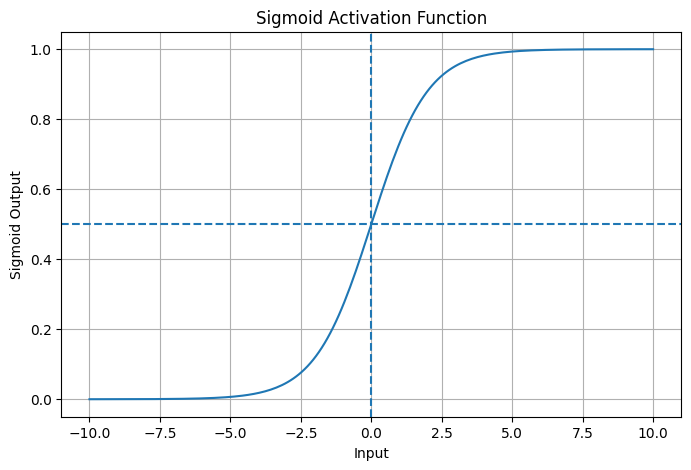


Sigmoid neuron demonstration completed.


In [4]:
# ============================================================
# DL FUNDAMENTALS - 4: SIGMOID NEURON
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# Input values
x = np.linspace(-10, 10, 200)

# Sigmoid outputs
y = sigmoid(x)

# Display some example values
test_values = [-5, -2, 0, 2, 5]

print("Sigmoid Neuron Demonstration")
print("----------------------------")
print("Input\tSigmoid Output")

for value in test_values:
    print(f"{value}\t{sigmoid(value):.4f}")


# Plot sigmoid activation
plt.figure(figsize=(8, 5))

plt.plot(x, y)

plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("Input")
plt.ylabel("Sigmoid Output")
plt.title("Sigmoid Activation Function")

plt.grid(True)
plt.show()

print("\nSigmoid neuron demonstration completed.")

In [6]:
# ============================================================
# DL FUNDAMENTALS - 5: MULTI-LAYER PERCEPTRON (XOR)
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

# XOR dataset
X = torch.tensor([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
])

y = torch.tensor([
    [0.0],
    [1.0],
    [1.0],
    [0.0]
])

# Reproducibility
torch.manual_seed(7)

# MLP model
class XOR_MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(2, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):

        x = torch.tanh(self.hidden(x))
        x = self.output(x)

        return x


model = XOR_MLP()

# Numerically stable binary classification loss
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.03
)

loss_history = []

# Training
for epoch in range(3000):

    optimizer.zero_grad()

    logits = model(X)

    loss = criterion(logits, y)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1:4d} | "
            f"Loss: {loss.item():.6f}"
        )


# Final evaluation
model.eval()

with torch.no_grad():

    logits = model(X)

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= 0.5
    ).float()


print("\nFinal XOR Predictions")
print("--------------------------------")

for i in range(len(X)):

    print(
        f"Input: {X[i].tolist()} | "
        f"Probability: {probabilities[i].item():.4f} | "
        f"Predicted: {int(predictions[i].item())} | "
        f"Actual: {int(y[i].item())}"
    )


accuracy = (
    predictions.eq(y)
    .float()
    .mean()
    .item()
)

print(
    f"\nTraining Accuracy: "
    f"{accuracy * 100:.2f}%"
)

if accuracy == 1.0:
    print("MLP successfully learned the XOR function.")
else:
    print("MLP did not completely learn XOR.")

Epoch  500 | Loss: 0.000333
Epoch 1000 | Loss: 0.000105
Epoch 1500 | Loss: 0.000052
Epoch 2000 | Loss: 0.000031
Epoch 2500 | Loss: 0.000020
Epoch 3000 | Loss: 0.000013

Final XOR Predictions
--------------------------------
Input: [0.0, 0.0] | Probability: 0.0000 | Predicted: 0 | Actual: 0
Input: [0.0, 1.0] | Probability: 1.0000 | Predicted: 1 | Actual: 1
Input: [1.0, 0.0] | Probability: 1.0000 | Predicted: 1 | Actual: 1
Input: [1.0, 1.0] | Probability: 0.0000 | Predicted: 0 | Actual: 0

Training Accuracy: 100.00%
MLP successfully learned the XOR function.


In [7]:
# ============================================================
# DL FUNDAMENTALS - 6: MANUAL BACKPROPAGATION
# ============================================================

import numpy as np

# Sigmoid function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Derivative of sigmoid
def sigmoid_derivative(output):
    return output * (1 - output)


# Example training sample
x1 = 1.0
x2 = 0.5
target = 1.0

# Initial weights and bias
w1 = 0.4
w2 = -0.2
bias = 0.1

learning_rate = 0.5


print("Before Backpropagation")
print("----------------------")
print("w1:", w1)
print("w2:", w2)
print("bias:", bias)


# -------------------------
# FORWARD PASS
# -------------------------

z = (x1 * w1) + (x2 * w2) + bias

prediction = sigmoid(z)

loss_before = 0.5 * (target - prediction) ** 2


# -------------------------
# MANUAL BACKPROPAGATION
# -------------------------

# dLoss/dPrediction
dL_dy = prediction - target

# dPrediction/dZ
dy_dz = sigmoid_derivative(prediction)

# Chain rule
dL_dz = dL_dy * dy_dz

# Gradients
grad_w1 = dL_dz * x1
grad_w2 = dL_dz * x2
grad_bias = dL_dz


print("\nManual Gradients")
print("----------------")
print("Gradient w1:", grad_w1)
print("Gradient w2:", grad_w2)
print("Gradient bias:", grad_bias)


# -------------------------
# UPDATE PARAMETERS
# -------------------------

w1 = w1 - learning_rate * grad_w1
w2 = w2 - learning_rate * grad_w2
bias = bias - learning_rate * grad_bias


# Forward pass after update
z_after = (x1 * w1) + (x2 * w2) + bias

prediction_after = sigmoid(z_after)

loss_after = 0.5 * (target - prediction_after) ** 2


print("\nAfter Backpropagation")
print("---------------------")
print("Updated w1:", w1)
print("Updated w2:", w2)
print("Updated bias:", bias)

print("\nPrediction before:", prediction)
print("Prediction after :", prediction_after)

print("Loss before:", loss_before)
print("Loss after :", loss_after)


if loss_after < loss_before:
    print("\nBackpropagation successful: loss decreased.")
else:
    print("\nBackpropagation check failed.")

Before Backpropagation
----------------------
w1: 0.4
w2: -0.2
bias: 0.1

Manual Gradients
----------------
Gradient w1: -0.0964196020566603
Gradient w2: -0.04820980102833015
Gradient bias: -0.0964196020566603

After Backpropagation
---------------------
Updated w1: 0.4482098010283302
Updated w2: -0.17589509948583493
Updated bias: 0.14820980102833015

Prediction before: 0.598687660112452
Prediction after : 0.6244482196137652
Loss before: 0.08052579707300943
Loss after : 0.07051956987563537

Backpropagation successful: loss decreased.


Final Optimizer Results
-------------------------------
GD       Loss: 0.073341
SGD      Loss: 0.073578
Momentum Loss: 0.073722
Nesterov Loss: 0.073341


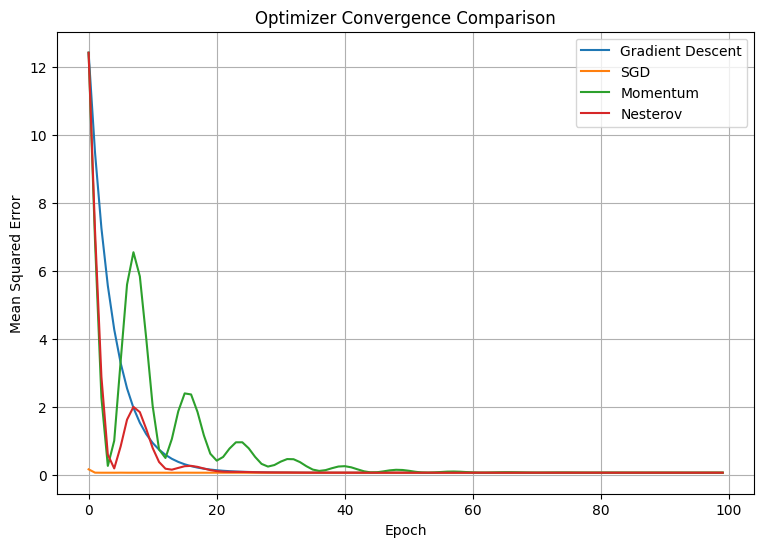

In [8]:
# ============================================================
# OPTIMIZER COMPARISON
# GD vs SGD vs Momentum vs Nesterov
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Simple regression dataset
np.random.seed(42)

X = np.linspace(-2, 2, 100).reshape(-1, 1)
y = 3 * X + 2 + np.random.normal(0, 0.3, X.shape)

# Add bias column
X_bias = np.c_[np.ones((len(X), 1)), X]


def compute_loss(X, y, weights):
    predictions = X @ weights
    return np.mean((predictions - y) ** 2)


def compute_gradient(X, y, weights):
    predictions = X @ weights

    return (
        2 / len(X)
    ) * X.T @ (predictions - y)


# ------------------------------------------------------------
# 1. Batch Gradient Descent
# ------------------------------------------------------------

def train_gd(X, y, epochs=100, lr=0.05):

    weights = np.zeros((X.shape[1], 1))
    losses = []

    for epoch in range(epochs):

        gradient = compute_gradient(
            X, y, weights
        )

        weights -= lr * gradient

        losses.append(
            compute_loss(X, y, weights)
        )

    return weights, losses


# ------------------------------------------------------------
# 2. Stochastic Gradient Descent
# ------------------------------------------------------------

def train_sgd(X, y, epochs=100, lr=0.01):

    weights = np.zeros((X.shape[1], 1))
    losses = []

    rng = np.random.default_rng(42)

    for epoch in range(epochs):

        indices = rng.permutation(len(X))

        for i in indices:

            xi = X[i:i+1]
            yi = y[i:i+1]

            gradient = compute_gradient(
                xi, yi, weights
            )

            weights -= lr * gradient

        losses.append(
            compute_loss(X, y, weights)
        )

    return weights, losses


# ------------------------------------------------------------
# 3. Momentum
# ------------------------------------------------------------

def train_momentum(
    X, y,
    epochs=100,
    lr=0.05,
    momentum=0.9
):

    weights = np.zeros((X.shape[1], 1))
    velocity = np.zeros_like(weights)

    losses = []

    for epoch in range(epochs):

        gradient = compute_gradient(
            X, y, weights
        )

        velocity = (
            momentum * velocity
            - lr * gradient
        )

        weights += velocity

        losses.append(
            compute_loss(X, y, weights)
        )

    return weights, losses


# ------------------------------------------------------------
# 4. Nesterov Accelerated Gradient
# ------------------------------------------------------------

def train_nesterov(
    X, y,
    epochs=100,
    lr=0.05,
    momentum=0.9
):

    weights = np.zeros((X.shape[1], 1))
    velocity = np.zeros_like(weights)

    losses = []

    for epoch in range(epochs):

        lookahead_weights = (
            weights + momentum * velocity
        )

        gradient = compute_gradient(
            X,
            y,
            lookahead_weights
        )

        velocity = (
            momentum * velocity
            - lr * gradient
        )

        weights += velocity

        losses.append(
            compute_loss(X, y, weights)
        )

    return weights, losses


# Train all optimizers
gd_w, gd_loss = train_gd(X_bias, y)
sgd_w, sgd_loss = train_sgd(X_bias, y)
mom_w, mom_loss = train_momentum(X_bias, y)
nag_w, nag_loss = train_nesterov(X_bias, y)


# Results
print("Final Optimizer Results")
print("-------------------------------")

print(
    f"GD       Loss: {gd_loss[-1]:.6f}"
)

print(
    f"SGD      Loss: {sgd_loss[-1]:.6f}"
)

print(
    f"Momentum Loss: {mom_loss[-1]:.6f}"
)

print(
    f"Nesterov Loss: {nag_loss[-1]:.6f}"
)


# Comparison graph
plt.figure(figsize=(9, 6))

plt.plot(gd_loss, label="Gradient Descent")
plt.plot(sgd_loss, label="SGD")
plt.plot(mom_loss, label="Momentum")
plt.plot(nag_loss, label="Nesterov")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Optimizer Convergence Comparison")

plt.legend()
plt.grid(True)

plt.show()

In [9]:
# ============================================================
# LEARNING RULES - 1: HEBBIAN LEARNING
# ============================================================

import numpy as np

# Bipolar AND-gate training data
X = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=float)

targets = np.array([
    -1,
    -1,
    -1,
     1
], dtype=float)

# Initial weights and bias
weights = np.zeros(2)
bias = 0.0

learning_rate = 1.0

print("Initial weights:", weights)
print("Initial bias:", bias)

# Hebbian learning rule
for x, target in zip(X, targets):

    weights += learning_rate * target * x
    bias += learning_rate * target

print("\nAfter Hebbian Learning")
print("----------------------")
print("Final weights:", weights)
print("Final bias:", bias)

# Test learned neuron
print("\nPredictions")
print("----------------------")

correct = 0

for x, target in zip(X, targets):

    activation = np.dot(weights, x) + bias

    prediction = 1 if activation >= 0 else -1

    if prediction == target:
        correct += 1

    print(
        f"Input: {x.astype(int).tolist()} | "
        f"Activation: {activation:.2f} | "
        f"Predicted: {prediction} | "
        f"Target: {int(target)}"
    )

accuracy = correct / len(X)

print(
    f"\nAccuracy: {accuracy * 100:.2f}%"
)

print("\nHebbian learning demonstration completed.")

Initial weights: [0. 0.]
Initial bias: 0.0

After Hebbian Learning
----------------------
Final weights: [2. 2.]
Final bias: -2.0

Predictions
----------------------
Input: [-1, -1] | Activation: -6.00 | Predicted: -1 | Target: -1
Input: [-1, 1] | Activation: -2.00 | Predicted: -1 | Target: -1
Input: [1, -1] | Activation: -2.00 | Predicted: -1 | Target: -1
Input: [1, 1] | Activation: 2.00 | Predicted: 1 | Target: 1

Accuracy: 100.00%

Hebbian learning demonstration completed.


In [10]:
# ============================================================
# LEARNING RULES - 2: MODIFIED HEBBIAN (OJA'S RULE)
# ============================================================

import numpy as np

np.random.seed(42)

# Sample input data
X = np.array([
    [1.0, 0.0],
    [0.8, 0.2],
    [0.2, 0.8],
    [0.0, 1.0]
])

# Initial small random weights
weights = np.random.uniform(
    -0.1, 0.1, size=2
)

learning_rate = 0.05
epochs = 100

print("Initial weights:", weights)

# Oja's learning rule:
# Δw = learning_rate * y * (x - y*w)

for epoch in range(epochs):

    for x in X:

        output = np.dot(weights, x)

        weights += (
            learning_rate
            * output
            * (x - output * weights)
        )

print("\nAfter Modified Hebbian Learning")
print("--------------------------------")
print("Final weights:", weights)

weight_norm = np.linalg.norm(weights)

print("Weight norm:", weight_norm)

print("\nNeuron outputs:")

for x in X:

    output = np.dot(weights, x)

    print(
        f"Input: {x.tolist()} | "
        f"Output: {output:.4f}"
    )

print(
    "\nModified Hebbian (Oja's Rule) "
    "demonstration completed."
)

Initial weights: [-0.02509198  0.09014286]

After Modified Hebbian Learning
--------------------------------
Final weights: [0.61699179 0.79213364]
Weight norm: 1.0040690032900346

Neuron outputs:
Input: [1.0, 0.0] | Output: 0.6170
Input: [0.8, 0.2] | Output: 0.6520
Input: [0.2, 0.8] | Output: 0.7571
Input: [0.0, 1.0] | Output: 0.7921

Modified Hebbian (Oja's Rule) demonstration completed.


Initial neuron weights:
[[1. 1.]
 [7. 7.]]

Final neuron weights:
[[1.96206496 1.98311184]
 [5.94533349 6.00801389]]

Cluster assignments:
Neuron 0 samples: 50
Neuron 1 samples: 50


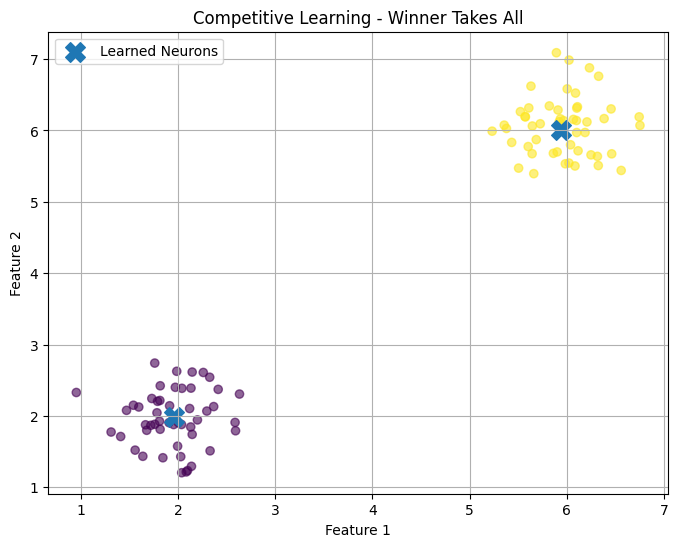


Competitive learning demonstration completed.


In [11]:
# ============================================================
# LEARNING RULES - 3: COMPETITIVE LEARNING
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Two groups of sample data
cluster_1 = np.random.normal(
    loc=[2, 2],
    scale=0.4,
    size=(50, 2)
)

cluster_2 = np.random.normal(
    loc=[6, 6],
    scale=0.4,
    size=(50, 2)
)

X = np.vstack([
    cluster_1,
    cluster_2
])

# Two competing neurons
weights = np.array([
    [1.0, 1.0],
    [7.0, 7.0]
])

learning_rate = 0.1
epochs = 20

print("Initial neuron weights:")
print(weights)

# Competitive learning
for epoch in range(epochs):

    for x in X:

        # Distance from input to each neuron
        distances = np.linalg.norm(
            weights - x,
            axis=1
        )

        # Winner-takes-all
        winner = np.argmin(distances)

        # Update only winning neuron
        weights[winner] += (
            learning_rate
            * (x - weights[winner])
        )

print("\nFinal neuron weights:")
print(weights)


# Assign each sample to winning neuron
assignments = []

for x in X:

    distances = np.linalg.norm(
        weights - x,
        axis=1
    )

    assignments.append(
        np.argmin(distances)
    )

assignments = np.array(assignments)

print("\nCluster assignments:")
print(
    "Neuron 0 samples:",
    np.sum(assignments == 0)
)

print(
    "Neuron 1 samples:",
    np.sum(assignments == 1)
)


# Visualization
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=assignments,
    alpha=0.6
)

plt.scatter(
    weights[:, 0],
    weights[:, 1],
    marker="X",
    s=200,
    label="Learned Neurons"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title(
    "Competitive Learning - Winner Takes All"
)

plt.legend()
plt.grid(True)
plt.show()

print(
    "\nCompetitive learning demonstration completed."
)

In [12]:
# ============================================================
# LEARNING RULES - 4: ERROR-CORRECTION LEARNING
# Perceptron Learning Rule
# ============================================================

import numpy as np

# AND gate dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

targets = np.array([0, 0, 0, 1])

# Initialize parameters
weights = np.zeros(2)
bias = 0.0

learning_rate = 0.1
epochs = 10

print("Initial weights:", weights)
print("Initial bias:", bias)

# Training
for epoch in range(epochs):

    total_errors = 0

    for x, target in zip(X, targets):

        activation = np.dot(weights, x) + bias

        prediction = 1 if activation >= 0 else 0

        # Error-correction term
        error = target - prediction

        # Update parameters
        weights += learning_rate * error * x
        bias += learning_rate * error

        total_errors += abs(error)

    print(
        f"Epoch {epoch + 1:2d} | "
        f"Errors: {int(total_errors)}"
    )

# Final evaluation
print("\nFinal weights:", weights)
print("Final bias:", bias)

print("\nFinal Predictions")
print("--------------------------------")

correct = 0

for x, target in zip(X, targets):

    activation = np.dot(weights, x) + bias

    prediction = 1 if activation >= 0 else 0

    if prediction == target:
        correct += 1

    print(
        f"Input: {x.astype(int).tolist()} | "
        f"Predicted: {prediction} | "
        f"Target: {target}"
    )

accuracy = correct / len(X)

print(f"\nAccuracy: {accuracy * 100:.2f}%")

if accuracy == 1.0:
    print("Error-correction learning successful.")

Initial weights: [0. 0.]
Initial bias: 0.0
Epoch  1 | Errors: 2
Epoch  2 | Errors: 3
Epoch  3 | Errors: 3
Epoch  4 | Errors: 0
Epoch  5 | Errors: 0
Epoch  6 | Errors: 0
Epoch  7 | Errors: 0
Epoch  8 | Errors: 0
Epoch  9 | Errors: 0
Epoch 10 | Errors: 0

Final weights: [0.2 0.1]
Final bias: -0.20000000000000004

Final Predictions
--------------------------------
Input: [0, 0] | Predicted: 0 | Target: 0
Input: [0, 1] | Predicted: 0 | Target: 0
Input: [1, 0] | Predicted: 0 | Target: 0
Input: [1, 1] | Predicted: 1 | Target: 1

Accuracy: 100.00%
Error-correction learning successful.


In [13]:
# ============================================================
# LEARNING RULES - 5: ENERGY / BOLTZMANN DEMONSTRATION
# ============================================================

import numpy as np

# Symmetric weight matrix
W = np.array([
    [0.0, 1.0, -0.5],
    [1.0, 0.0, 0.8],
    [-0.5, 0.8, 0.0]
])

# Bias values
bias = np.array([0.2, -0.1, 0.3])

# Possible bipolar network states
states = np.array([
    [-1, -1, -1],
    [-1, -1,  1],
    [-1,  1, -1],
    [-1,  1,  1],
    [ 1, -1, -1],
    [ 1, -1,  1],
    [ 1,  1, -1],
    [ 1,  1,  1]
], dtype=float)


# Energy function
def energy(state, W, bias):

    interaction_energy = (
        -0.5 * state.T @ W @ state
    )

    bias_energy = (
        -bias.T @ state
    )

    return interaction_energy + bias_energy


# Calculate energy for each state
energies = np.array([
    energy(state, W, bias)
    for state in states
])


# Boltzmann probability
temperature = 1.0

unnormalized_prob = np.exp(
    -energies / temperature
)

probabilities = (
    unnormalized_prob /
    np.sum(unnormalized_prob)
)


print("Energy-Based Network / Boltzmann Demonstration")
print("------------------------------------------------")

for state, E, P in zip(
    states,
    energies,
    probabilities
):

    print(
        f"State: {state.astype(int).tolist()} | "
        f"Energy: {E:.4f} | "
        f"Probability: {P:.4f}"
    )


# Lowest-energy state
best_index = np.argmin(energies)

print("\nLowest-energy state:")
print(states[best_index].astype(int).tolist())

print(
    "Lowest energy:",
    round(energies[best_index], 4)
)

print(
    "Boltzmann probability:",
    round(probabilities[best_index], 4)
)

print(
    "\nProbability sum:",
    round(probabilities.sum(), 6)
)

print(
    "\nEnergy/Boltzmann demonstration completed."
)

Energy-Based Network / Boltzmann Demonstration
------------------------------------------------
State: [-1, -1, -1] | Energy: -0.9000 | Probability: 0.1642
State: [-1, -1, 1] | Energy: -0.9000 | Probability: 0.1642
State: [-1, 1, -1] | Energy: 2.9000 | Probability: 0.0037
State: [-1, 1, 1] | Energy: -0.3000 | Probability: 0.0901
State: [1, -1, -1] | Energy: -0.3000 | Probability: 0.0901
State: [1, -1, 1] | Energy: 1.7000 | Probability: 0.0122
State: [1, 1, -1] | Energy: -0.5000 | Probability: 0.1101
State: [1, 1, 1] | Energy: -1.7000 | Probability: 0.3654

Lowest-energy state:
[1, 1, 1]
Lowest energy: -1.7
Boltzmann probability: 0.3654

Probability sum: 1.0

Energy/Boltzmann demonstration completed.


Activation Function Comparison
----------------------------------------------------------
Input	Sigmoid		Tanh		ReLU	Leaky ReLU
-3.0	0.0474		-0.9951		0.00	-0.30
-1.0	0.2689		-0.7616		0.00	-0.10
 0.0	0.5000		0.0000		0.00	0.00
 1.0	0.7311		0.7616		1.00	1.00
 3.0	0.9526		0.9951		3.00	3.00


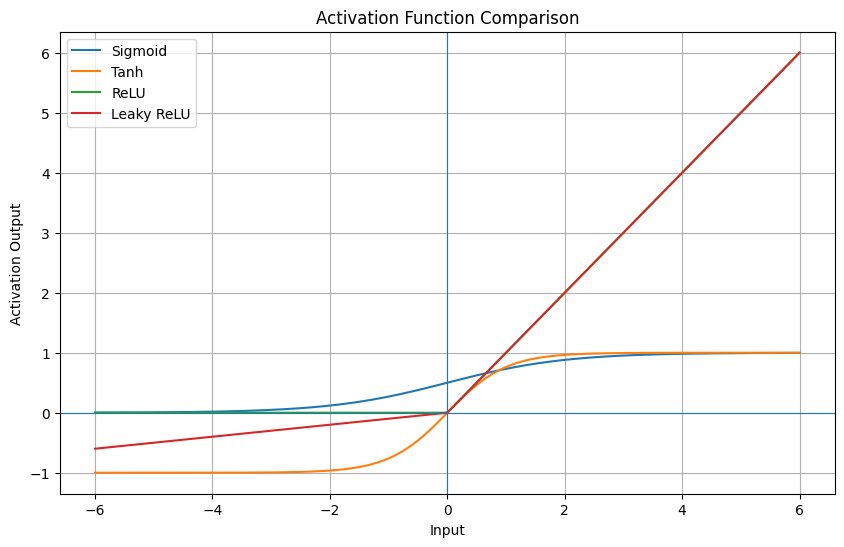


Activation function comparison completed.


In [14]:
# ============================================================
# DL EXPERIMENTS - 1: ACTIVATION FUNCTION COMPARISON
# Sigmoid vs Tanh vs ReLU vs Leaky ReLU
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Input range
x = np.linspace(-6, 6, 400)

# Activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)


# Calculate outputs
y_sigmoid = sigmoid(x)
y_tanh = tanh(x)
y_relu = relu(x)
y_leaky = leaky_relu(x)


# Example comparison
test_values = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])

print("Activation Function Comparison")
print("----------------------------------------------------------")
print("Input\tSigmoid\t\tTanh\t\tReLU\tLeaky ReLU")

for value in test_values:

    print(
        f"{value:4.1f}\t"
        f"{sigmoid(value):.4f}\t\t"
        f"{tanh(value):.4f}\t\t"
        f"{relu(value):.2f}\t"
        f"{leaky_relu(value):.2f}"
    )


# Plot comparison
plt.figure(figsize=(10, 6))

plt.plot(x, y_sigmoid, label="Sigmoid")
plt.plot(x, y_tanh, label="Tanh")
plt.plot(x, y_relu, label="ReLU")
plt.plot(x, y_leaky, label="Leaky ReLU")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Input")
plt.ylabel("Activation Output")
plt.title("Activation Function Comparison")

plt.legend()
plt.grid(True)

plt.show()

print("\nActivation function comparison completed.")

Weight Initialization Comparison
------------------------------------------
Zero    | Output Mean: 0.0000 | Output Std: 0.0000
Xavier  | Output Mean: 0.4033 | Output Std: 0.5902
He      | Output Mean: 0.5749 | Output Std: 0.8410


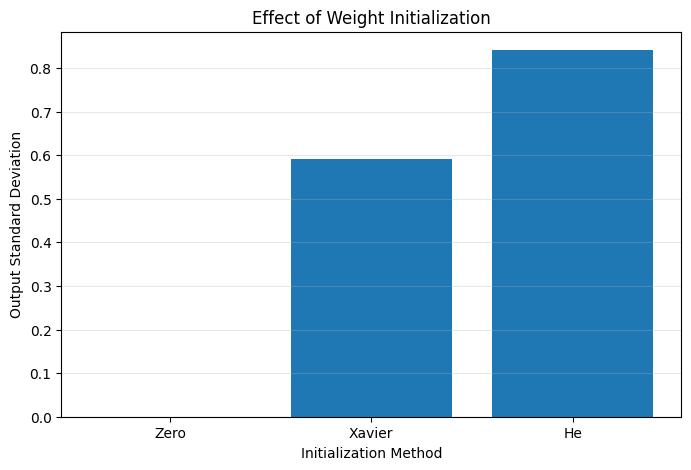


Weight initialization comparison completed.


In [15]:
# ============================================================
# DL EXPERIMENTS - 2: WEIGHT INITIALIZATION COMPARISON
# Zero vs Xavier vs He
# ============================================================

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Random input data
X = torch.randn(1000, 100)

# Same network structure
class InitNetwork(nn.Module):

    def __init__(self, init_type):

        super().__init__()

        self.layer = nn.Linear(100, 100)

        # Different initialization methods
        if init_type == "Zero":

            nn.init.zeros_(self.layer.weight)

        elif init_type == "Xavier":

            nn.init.xavier_uniform_(
                self.layer.weight
            )

        elif init_type == "He":

            nn.init.kaiming_uniform_(
                self.layer.weight,
                nonlinearity="relu"
            )

        nn.init.zeros_(self.layer.bias)

    def forward(self, x):

        return torch.relu(
            self.layer(x)
        )


initializations = [
    "Zero",
    "Xavier",
    "He"
]

results = {}

print("Weight Initialization Comparison")
print("------------------------------------------")

for init_type in initializations:

    model = InitNetwork(init_type)

    with torch.no_grad():

        output = model(X)

    mean = output.mean().item()
    std = output.std().item()

    results[init_type] = {
        "mean": mean,
        "std": std
    }

    print(
        f"{init_type:7s} | "
        f"Output Mean: {mean:.4f} | "
        f"Output Std: {std:.4f}"
    )


# Plot output standard deviation
names = list(results.keys())

std_values = [
    results[name]["std"]
    for name in names
]

plt.figure(figsize=(8, 5))

plt.bar(
    names,
    std_values
)

plt.xlabel("Initialization Method")
plt.ylabel("Output Standard Deviation")
plt.title(
    "Effect of Weight Initialization"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

print(
    "\nWeight initialization comparison completed."
)

Normalization Comparison
--------------------------------------
Without Normalization | Mean: -1.0822 | Std: 6.2021
Batch Normalization   | Mean: -0.0000 | Std: 1.0000


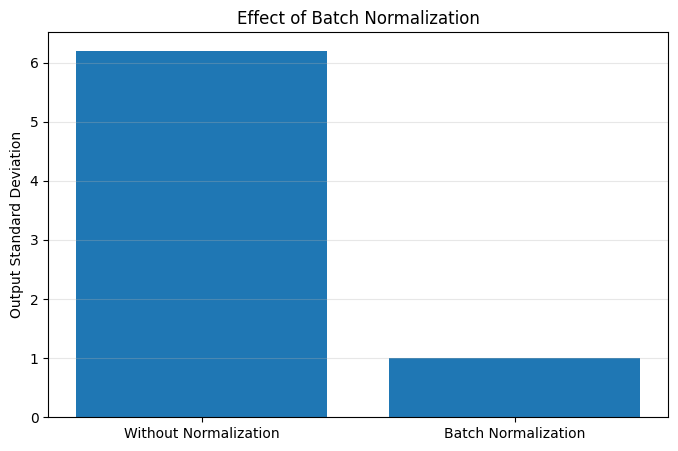


Normalization comparison completed.


In [16]:
# ============================================================
# DL EXPERIMENTS - 3: NORMALIZATION COMPARISON
# Without Normalization vs Batch Normalization
# ============================================================

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Input with deliberately shifted/scaled distribution
X = torch.randn(1000, 20) * 5 + 10

# Linear layer
linear = nn.Linear(20, 20)

with torch.no_grad():
    raw_output = linear(X)

# Batch normalization
batch_norm = nn.BatchNorm1d(20)

normalized_output = batch_norm(raw_output)

# Statistics
raw_mean = raw_output.mean().item()
raw_std = raw_output.std().item()

norm_mean = normalized_output.mean().item()
norm_std = normalized_output.std().item()

print("Normalization Comparison")
print("--------------------------------------")

print(
    f"Without Normalization | "
    f"Mean: {raw_mean:.4f} | "
    f"Std: {raw_std:.4f}"
)

print(
    f"Batch Normalization   | "
    f"Mean: {norm_mean:.4f} | "
    f"Std: {norm_std:.4f}"
)

# Visualization
labels = [
    "Without Normalization",
    "Batch Normalization"
]

std_values = [
    raw_std,
    norm_std
]

plt.figure(figsize=(8, 5))

plt.bar(
    labels,
    std_values
)

plt.ylabel("Output Standard Deviation")
plt.title("Effect of Batch Normalization")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

print("\nNormalization comparison completed.")

Regularization Comparison
-----------------------------------------
No Regularization | Final Loss: 0.2279 | Weight Norm: 5.2371
L2 Regularization | Final Loss: 0.2271 | Weight Norm: 5.0820


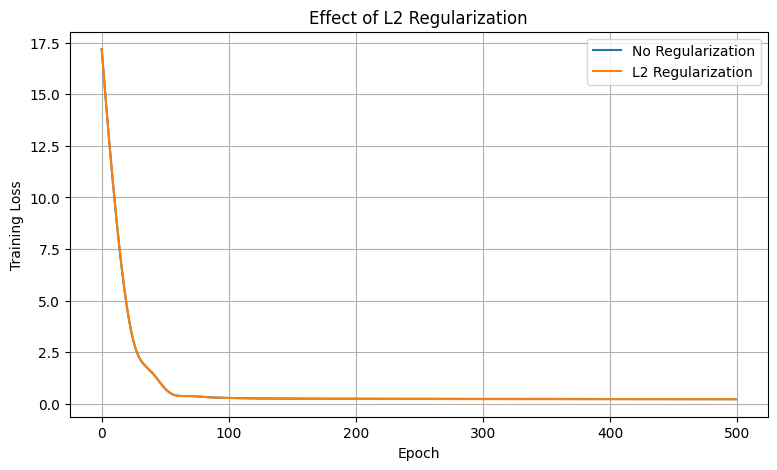


Regularization comparison completed.


In [17]:
# ============================================================
# DL EXPERIMENTS - 4: REGULARIZATION COMPARISON
# No Regularization vs L2 Regularization
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Synthetic regression dataset
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y = 3 * X + 2 + 0.5 * torch.randn_like(X)

# Small neural network
class RegressionModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 20),
            nn.ReLU(),
            nn.Linear(20, 1)
        )

    def forward(self, x):
        return self.network(x)


def train_model(weight_decay):

    # Same initialization for fair comparison
    torch.manual_seed(42)

    model = RegressionModel()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=weight_decay
    )

    criterion = nn.MSELoss()

    losses = []

    for epoch in range(500):

        optimizer.zero_grad()

        prediction = model(X)

        loss = criterion(prediction, y)

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    # Calculate total weight magnitude
    weight_norm = 0

    for parameter in model.parameters():

        if parameter.ndim > 1:
            weight_norm += (
                parameter.norm().item()
            )

    return model, losses, weight_norm


# Train both models
model_no_reg, loss_no_reg, norm_no_reg = train_model(
    weight_decay=0.0
)

model_l2, loss_l2, norm_l2 = train_model(
    weight_decay=0.01
)


print("Regularization Comparison")
print("-----------------------------------------")

print(
    f"No Regularization | "
    f"Final Loss: {loss_no_reg[-1]:.4f} | "
    f"Weight Norm: {norm_no_reg:.4f}"
)

print(
    f"L2 Regularization | "
    f"Final Loss: {loss_l2[-1]:.4f} | "
    f"Weight Norm: {norm_l2:.4f}"
)


# Loss comparison
plt.figure(figsize=(9, 5))

plt.plot(
    loss_no_reg,
    label="No Regularization"
)

plt.plot(
    loss_l2,
    label="L2 Regularization"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Effect of L2 Regularization")

plt.legend()
plt.grid(True)

plt.show()

print("\nRegularization comparison completed.")

In [18]:
# ============================================================
# DL EXPERIMENTS - 5: DATA AUGMENTATION DEMONSTRATION
# ============================================================

import os
import random
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# PackWISE training images
TRAIN_DIR = "/content/PackWISE/data/train"

image_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Reproducible image selection
random.seed(42)
image_name = random.choice(image_files)

image_path = os.path.join(
    TRAIN_DIR,
    image_name
)

original_image = Image.open(
    image_path
).convert("RGB")


# Augmentation pipeline
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.RandomRotation(20),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    )
])


# Create augmented versions
augmented_images = [
    augmentation(original_image)
    for _ in range(3)
]


print("Data Augmentation Demonstration")
print("--------------------------------")
print("Selected image:", image_name)
print("Original size:", original_image.size)
print("Augmented samples created:", len(augmented_images))


# Visualization
plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

for i, augmented in enumerate(
    augmented_images,
    start=2
):

    plt.subplot(1, 4, i)

    plt.imshow(augmented)

    plt.title(
        f"Augmented {i - 1}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print(
    "\nData augmentation demonstration completed."
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/PackWISE/data/train'

In [19]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/Waste_Sorting_PBL/PackWISE_dataset_v2.zip"
DATASET_DIR = "/content/PackWISE"

print("ZIP exists:", os.path.exists(ZIP_PATH))

if not os.path.exists(DATASET_DIR):
    print("Extracting PackWISE dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATASET_DIR)

    print("Dataset extracted successfully.")
else:
    print("Dataset already extracted.")

TRAIN_DIR = "/content/PackWISE/data/train"

print("Train folder exists:", os.path.exists(TRAIN_DIR))

if os.path.exists(TRAIN_DIR):
    print("Train files:", len(os.listdir(TRAIN_DIR)))

ZIP exists: False
Extracting PackWISE dataset...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Waste_Sorting_PBL/PackWISE_dataset_v2.zip'

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import os

print(os.listdir("/content/drive/MyDrive")[:20])

['Colab Notebooks', 'MobileNet_CIFAR10_Results', 'Waste_Sorting_PBL']


In [22]:
import os

PBL_DIR = "/content/drive/MyDrive/Waste_Sorting_PBL"

print("Files inside Waste_Sorting_PBL:\n")

for item in os.listdir(PBL_DIR):
    print(item)

Files inside Waste_Sorting_PBL:

PackWISE_dataset_v2.zip
models
results
WasteSortingApp_Final


In [23]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/Waste_Sorting_PBL/PackWISE_dataset_v2.zip"
DATASET_DIR = "/content/PackWISE"

print("ZIP exists:", os.path.exists(ZIP_PATH))

os.makedirs(DATASET_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("Dataset extracted successfully.")

TRAIN_DIR = "/content/PackWISE/data/train"

print("Train folder exists:", os.path.exists(TRAIN_DIR))

if os.path.exists(TRAIN_DIR):
    print("Train files:", len(os.listdir(TRAIN_DIR)))

ZIP exists: True
Dataset extracted successfully.
Train folder exists: True
Train files: 410


Convolution / Filter Visualization
----------------------------------
Selected image: Vollstrom2_frame00046_Probe00023_00024.jpg
Image shape: (256, 256)
Filter size: 3 x 3


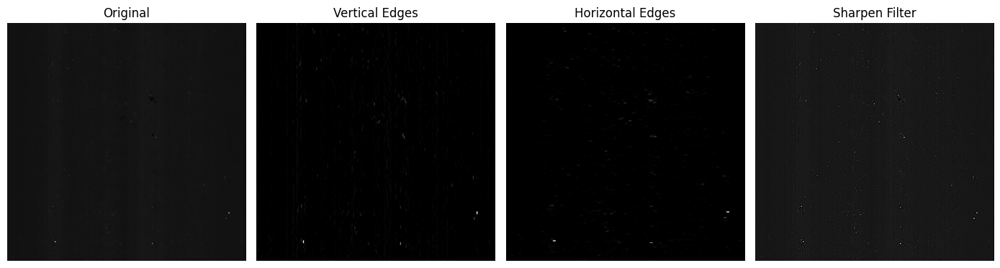


Convolution visualization completed.


In [24]:
# ============================================================
# CNN ARCHITECTURE - 1: CONVOLUTION / FILTER VISUALIZATION
# ============================================================

import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

TRAIN_DIR = "/content/PackWISE/data/train"

image_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

random.seed(42)
image_name = random.choice(image_files)

image_path = os.path.join(TRAIN_DIR, image_name)

# Read image in grayscale
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Resize for clear visualization
image = cv2.resize(image, (256, 256))

# Common CNN-style filters
vertical_filter = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

horizontal_filter = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

sharpen_filter = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# Apply convolution
vertical_edges = cv2.filter2D(
    image, -1, vertical_filter
)

horizontal_edges = cv2.filter2D(
    image, -1, horizontal_filter
)

sharpened = cv2.filter2D(
    image, -1, sharpen_filter
)

print("Convolution / Filter Visualization")
print("----------------------------------")
print("Selected image:", image_name)
print("Image shape:", image.shape)
print("Filter size: 3 x 3")

# Display results
plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(vertical_edges, cmap="gray")
plt.title("Vertical Edges")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(horizontal_edges, cmap="gray")
plt.title("Horizontal Edges")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(sharpened, cmap="gray")
plt.title("Sharpen Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

print("\nConvolution visualization completed.")

In [25]:
# ============================================================
# CNN ARCHITECTURE - 2: ARCHITECTURE BENCHMARK
# Basic CNN vs ResNet18 vs GoogLeNet
# ============================================================

import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

NUM_CLASSES = 23


# -----------------------------
# Basic CNN
# -----------------------------

class BasicCNN(nn.Module):

    def __init__(self, num_classes=23):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(
            32,
            num_classes
        )

    def forward(self, x):

        x = self.features(x)

        x = torch.flatten(x, 1)

        return self.classifier(x)


basic_cnn = BasicCNN(
    NUM_CLASSES
).to(device)


# -----------------------------
# ResNet18
# -----------------------------

resnet = models.resnet18(
    weights=None
)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    NUM_CLASSES
)

resnet = resnet.to(device)


# -----------------------------
# GoogLeNet
# -----------------------------

googlenet = models.googlenet(
    weights=None,
    aux_logits=False
)

googlenet.fc = nn.Linear(
    googlenet.fc.in_features,
    NUM_CLASSES
)

googlenet = googlenet.to(device)


# -----------------------------
# Parameter comparison
# -----------------------------

def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


models_dict = {
    "Basic CNN": basic_cnn,
    "ResNet18": resnet,
    "GoogLeNet": googlenet
}


print("CNN Architecture Benchmark")
print("---------------------------------------------")

for name, model in models_dict.items():

    params = count_parameters(model)

    print(
        f"{name:10s} | "
        f"Trainable Parameters: "
        f"{params:,}"
    )


# -----------------------------
# Forward-pass verification
# -----------------------------

dummy_input = torch.randn(
    1, 3, 224, 224
).to(device)


print("\nForward Pass Verification")
print("---------------------------------------------")

for name, model in models_dict.items():

    model.eval()

    with torch.no_grad():
        output = model(dummy_input)

    print(
        f"{name:10s} | "
        f"Output Shape: "
        f"{tuple(output.shape)}"
    )


print("\nDevice:", device)

print(
    "\nCNN architecture benchmark completed."
)

/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:47: FutureWarning: The default weight initialization of GoogleNet will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


CNN Architecture Benchmark
---------------------------------------------
Basic CNN  | Trainable Parameters: 5,847
ResNet18   | Trainable Parameters: 11,188,311
GoogLeNet  | Trainable Parameters: 5,623,479

Forward Pass Verification
---------------------------------------------
Basic CNN  | Output Shape: (1, 23)
ResNet18   | Output Shape: (1, 23)
GoogLeNet  | Output Shape: (1, 23)

Device: cuda

CNN architecture benchmark completed.


In [29]:
# ============================================================
# FINAL EVALUATION - SETUP
# Prepare YOLO test labels + load final detection model
# ============================================================

import os
import json
import shutil
from ultralytics import YOLO

DATA_ROOT = "/content/PackWISE/data"
TEST_JSON = f"{DATA_ROOT}/test.json"
TEST_DIR = f"{DATA_ROOT}/test"

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Waste_Sorting_PBL/models/final_yolo_best.pt"
)

print("Test JSON exists:", os.path.exists(TEST_JSON))
print("Test folder exists:", os.path.exists(TEST_DIR))
print("Final model exists:", os.path.exists(MODEL_PATH))

# Load COCO test annotations
with open(TEST_JSON, "r") as f:
    coco = json.load(f)

# Category ID -> YOLO class index
categories = sorted(
    coco["categories"],
    key=lambda x: x["id"]
)

cat_to_yolo = {
    cat["id"]: i
    for i, cat in enumerate(categories)
}

# Image information
image_info = {
    img["id"]: img
    for img in coco["images"]
}

# Create YOLO label files
annotations_by_image = {}

for ann in coco["annotations"]:
    annotations_by_image.setdefault(
        ann["image_id"], []
    ).append(ann)

label_count = 0

for image_id, img in image_info.items():

    width = img["width"]
    height = img["height"]

    label_name = (
        os.path.splitext(img["file_name"])[0]
        + ".txt"
    )

    label_path = os.path.join(
        TEST_DIR,
        label_name
    )

    lines = []

    for ann in annotations_by_image.get(
        image_id, []
    ):

        x, y, w, h = ann["bbox"]

        x_center = (x + w / 2) / width
        y_center = (y + h / 2) / height
        w_norm = w / width
        h_norm = h / height

        class_id = cat_to_yolo[
            ann["category_id"]
        ]

        lines.append(
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{w_norm:.6f} "
            f"{h_norm:.6f}"
        )

    with open(label_path, "w") as f:
        f.write("\n".join(lines))

    label_count += 1


# Load final YOLO model
model = YOLO(MODEL_PATH)

print("\nTest images:", len(coco["images"]))
print("Test annotation files created:", label_count)
print("Number of classes:", len(categories))
print("Final YOLO model loaded successfully.")

Test JSON exists: True
Test folder exists: True
Final model exists: True

Test images: 88
Test annotation files created: 88
Number of classes: 23
Final YOLO model loaded successfully.


In [27]:
!pip install -q ultralytics

In [28]:
from ultralytics import YOLO
import ultralytics

print("Ultralytics installed successfully.")
print("Version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics installed successfully.
Version: 8.4.216


Detection Classification Evaluation
----------------------------------------
Matched objects: 739
Macro-F1 (matched detections): 0.3767


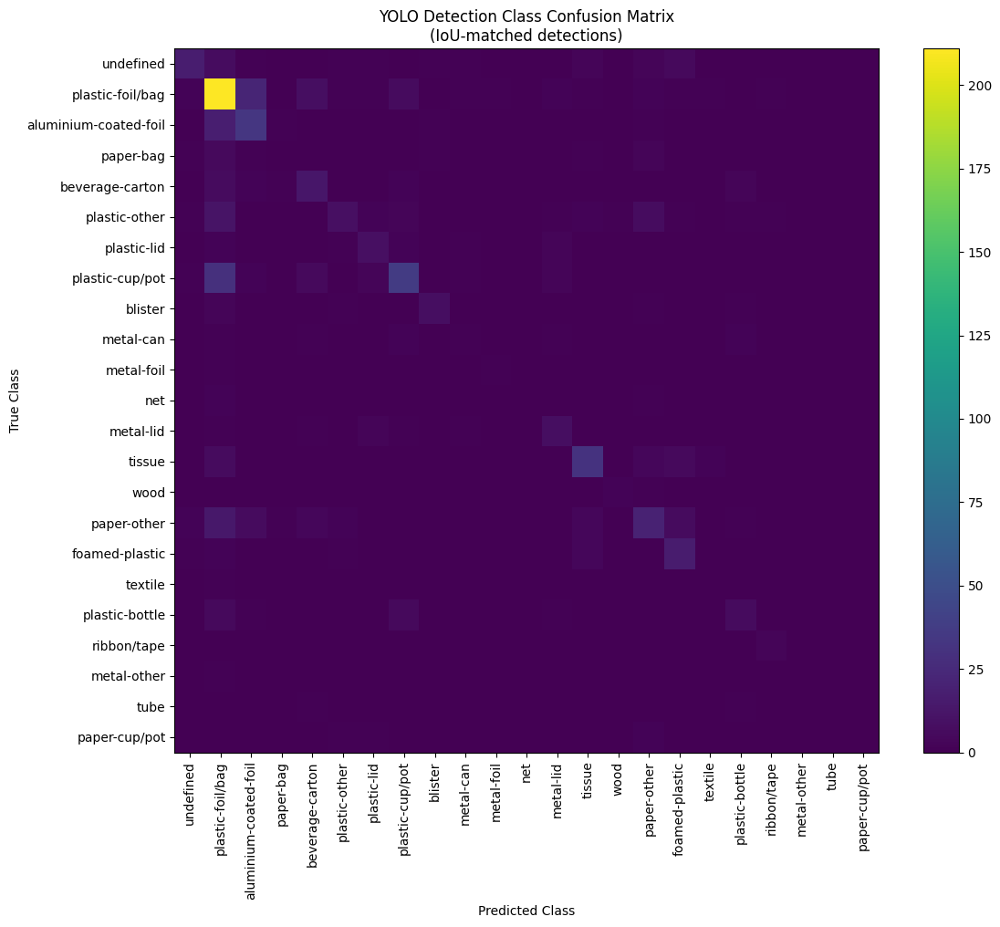

Classes represented: 23

Macro-F1 and confusion matrix evaluation completed.


In [30]:
# ============================================================
# FINAL EVALUATION - MACRO F1 + CONFUSION MATRIX
# Actual YOLO detections matched with ground truth using IoU
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    f1_score
)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

TEST_DIR = "/content/PackWISE/data/test"
TEST_JSON = "/content/PackWISE/data/test.json"

# ------------------------------------------------------------
# IoU function
# ------------------------------------------------------------

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (
        (box1[2] - box1[0]) *
        (box1[3] - box1[1])
    )

    area2 = (
        (box2[2] - box2[0]) *
        (box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ------------------------------------------------------------
# Load ground-truth annotations
# ------------------------------------------------------------

with open(TEST_JSON, "r") as f:
    coco = json.load(f)

categories = sorted(
    coco["categories"],
    key=lambda x: x["id"]
)

cat_to_class = {
    cat["id"]: i
    for i, cat in enumerate(categories)
}

class_names = [
    cat["name"]
    for cat in categories
]

image_info = {
    img["id"]: img
    for img in coco["images"]
}

gt_by_image = {}

for ann in coco["annotations"]:

    image_id = ann["image_id"]

    x, y, w, h = ann["bbox"]

    gt_box = [
        x,
        y,
        x + w,
        y + h
    ]

    gt_class = cat_to_class[
        ann["category_id"]
    ]

    gt_by_image.setdefault(
        image_id, []
    ).append({
        "box": gt_box,
        "class": gt_class
    })


# ------------------------------------------------------------
# Run model and match predictions
# ------------------------------------------------------------

y_true = []
y_pred = []

matched_objects = 0

for image_id, info in image_info.items():

    image_path = os.path.join(
        TEST_DIR,
        info["file_name"]
    )

    results = model.predict(
        image_path,
        conf=CONF_THRESHOLD,
        verbose=False
    )

    result = results[0]

    predicted_boxes = []

    if result.boxes is not None:

        for box in result.boxes:

            coords = (
                box.xyxy[0]
                .cpu()
                .numpy()
                .tolist()
            )

            pred_class = int(
                box.cls[0].item()
            )

            confidence = float(
                box.conf[0].item()
            )

            predicted_boxes.append({
                "box": coords,
                "class": pred_class,
                "confidence": confidence
            })


    ground_truths = gt_by_image.get(
        image_id, []
    )

    used_predictions = set()

    for gt in ground_truths:

        best_iou = 0
        best_index = None

        for index, pred in enumerate(
            predicted_boxes
        ):

            if index in used_predictions:
                continue

            iou = calculate_iou(
                gt["box"],
                pred["box"]
            )

            if iou > best_iou:

                best_iou = iou
                best_index = index


        # Only matched objects are used for
        # class confusion matrix / macro-F1
        if (
            best_index is not None
            and best_iou >= IOU_THRESHOLD
        ):

            y_true.append(
                gt["class"]
            )

            y_pred.append(
                predicted_boxes[
                    best_index
                ]["class"]
            )

            used_predictions.add(
                best_index
            )

            matched_objects += 1


# ------------------------------------------------------------
# Macro-F1
# ------------------------------------------------------------

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Detection Classification Evaluation")
print("----------------------------------------")
print("Matched objects:", matched_objects)

if len(y_true) == 0:

    print(
        "No detections matched ground truth "
        "at the selected IoU threshold."
    )

else:

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    print(
        f"Macro-F1 (matched detections): "
        f"{macro_f1:.4f}"
    )


    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    present_classes = sorted(
        set(y_true.tolist()) |
        set(y_pred.tolist())
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=present_classes
    )

    present_names = [
        class_names[i]
        for i in present_classes
    ]

    plt.figure(figsize=(12, 10))

    plt.imshow(
        cm,
        interpolation="nearest"
    )

    plt.title(
        "YOLO Detection Class Confusion Matrix\n"
        "(IoU-matched detections)"
    )

    plt.colorbar()

    tick_marks = np.arange(
        len(present_names)
    )

    plt.xticks(
        tick_marks,
        present_names,
        rotation=90
    )

    plt.yticks(
        tick_marks,
        present_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")

    plt.tight_layout()
    plt.show()

    print(
        "Classes represented:",
        len(present_classes)
    )

    print(
        "\nMacro-F1 and confusion matrix "
        "evaluation completed."
    )

In [31]:
# ============================================================
# FINAL EVALUATION - SEGMENTATION IoU SETUP
# ============================================================

import os
import json
from ultralytics import YOLO

SEG_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Waste_Sorting_PBL/models/segmentation_best.pt"
)

TEST_JSON = "/content/PackWISE/data/test.json"
TEST_DIR = "/content/PackWISE/data/test"

print(
    "Segmentation model exists:",
    os.path.exists(SEG_MODEL_PATH)
)

print(
    "Test JSON exists:",
    os.path.exists(TEST_JSON)
)

print(
    "Test directory exists:",
    os.path.exists(TEST_DIR)
)

# Load segmentation model
seg_model = YOLO(SEG_MODEL_PATH)

# Load test annotations
with open(TEST_JSON, "r") as f:
    test_coco = json.load(f)

print("\nTest images:", len(test_coco["images"]))
print(
    "Test annotations:",
    len(test_coco["annotations"])
)

# Check segmentation annotation availability
segmentation_annotations = sum(
    1
    for ann in test_coco["annotations"]
    if ann.get("segmentation")
)

print(
    "Annotations with segmentation:",
    segmentation_annotations
)

print(
    "\nSegmentation IoU setup completed."
)

Segmentation model exists: True
Test JSON exists: True
Test directory exists: True

Test images: 88
Test annotations: 1054
Annotations with segmentation: 1054

Segmentation IoU setup completed.


In [33]:
# ============================================================
# FAST SEGMENTATION IoU EVALUATION
# Sample of 10 test images
# ============================================================

import os
import cv2
import numpy as np
from pycocotools import mask as mask_utils

CONF_THRESHOLD = 0.25
SAMPLE_SIZE = 10

image_info = {
    img["id"]: img
    for img in test_coco["images"]
}

annotations_by_image = {}

for ann in test_coco["annotations"]:
    annotations_by_image.setdefault(
        ann["image_id"], []
    ).append(ann)


def decode_coco_mask(segmentation, height, width):

    if isinstance(segmentation, list):
        rles = mask_utils.frPyObjects(
            segmentation, height, width
        )
        rle = mask_utils.merge(rles)
    else:
        rle = segmentation

    mask = mask_utils.decode(rle)

    if mask.ndim == 3:
        mask = np.any(mask, axis=2)

    return mask.astype(bool)


def binary_iou(mask1, mask2):

    intersection = np.logical_and(
        mask1, mask2
    ).sum()

    union = np.logical_or(
        mask1, mask2
    ).sum()

    return (
        intersection / union
        if union > 0 else 0.0
    )


# Fixed sample for reproducibility
sample_ids = sorted(
    image_info.keys()
)[:SAMPLE_SIZE]

all_ious = []
matched_masks = 0
total_gt = 0

for count, image_id in enumerate(
    sample_ids, start=1
):

    info = image_info[image_id]

    image_path = os.path.join(
        TEST_DIR,
        info["file_name"]
    )

    height = info["height"]
    width = info["width"]

    gt_masks = [
        decode_coco_mask(
            ann["segmentation"],
            height,
            width
        )
        for ann in annotations_by_image.get(
            image_id, []
        )
    ]

    result = seg_model.predict(
        image_path,
        conf=CONF_THRESHOLD,
        verbose=False
    )[0]

    pred_masks = []

    if result.masks is not None:

        for mask in (
            result.masks.data.cpu().numpy()
        ):

            resized = cv2.resize(
                mask,
                (width, height),
                interpolation=cv2.INTER_NEAREST
            )

            pred_masks.append(
                resized > 0.5
            )

    used = set()

    for gt_mask in gt_masks:

        total_gt += 1

        best_iou = 0
        best_index = None

        for j, pred_mask in enumerate(
            pred_masks
        ):

            if j in used:
                continue

            iou = binary_iou(
                gt_mask,
                pred_mask
            )

            if iou > best_iou:
                best_iou = iou
                best_index = j

        if best_index is not None:
            used.add(best_index)
            matched_masks += 1

        all_ious.append(best_iou)

    print(
        f"Processed {count}/{SAMPLE_SIZE}"
    )


all_ious = np.array(all_ious)

print("\nSampled Segmentation IoU Evaluation")
print("---------------------------------------")
print("Test images evaluated:", SAMPLE_SIZE)
print("Ground-truth masks:", total_gt)
print("Matched masks:", matched_masks)
print(f"Mean IoU: {all_ious.mean():.4f}")
print(f"Median IoU: {np.median(all_ious):.4f}")
print(
    f"IoU >= 0.50: "
    f"{np.mean(all_ious >= 0.50) * 100:.2f}%"
)

Processed 1/10
Processed 2/10
Processed 3/10
Processed 4/10
Processed 5/10
Processed 6/10
Processed 7/10
Processed 8/10
Processed 9/10
Processed 10/10

Sampled Segmentation IoU Evaluation
---------------------------------------
Test images evaluated: 10
Ground-truth masks: 133
Matched masks: 81
Mean IoU: 0.3740
Median IoU: 0.0368
IoU >= 0.50: 37.59%


In [34]:
# ============================================================
# FINAL EVALUATION - INFERENCE SPEED / LATENCY / FPS
# ============================================================

import os
import time
import numpy as np
import torch

TEST_DIR = "/content/PackWISE/data/test"

test_images = [
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Fixed sample
test_images = sorted(test_images)[:20]

# GPU warm-up
for _ in range(3):
    model.predict(
        test_images[0],
        verbose=False
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

latencies = []

for image_path in test_images:

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    model.predict(
        image_path,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    latencies.append(
        (end - start) * 1000
    )

average_latency = np.mean(latencies)
median_latency = np.median(latencies)

fps = (
    1000 / average_latency
    if average_latency > 0
    else 0
)

print("YOLO Inference Performance")
print("--------------------------------")
print("Images tested:", len(test_images))
print(
    f"Average latency: "
    f"{average_latency:.2f} ms/image"
)
print(
    f"Median latency: "
    f"{median_latency:.2f} ms/image"
)
print(
    f"Approximate FPS: {fps:.2f}"
)
print(
    "Device:",
    "CUDA" if torch.cuda.is_available()
    else "CPU"
)

print("\nInference speed evaluation completed.")

YOLO Inference Performance
--------------------------------
Images tested: 20
Average latency: 121.97 ms/image
Median latency: 105.02 ms/image
Approximate FPS: 8.20
Device: CUDA

Inference speed evaluation completed.


In [35]:
# ============================================================
# FINAL EVALUATION - GPU MEMORY USAGE
# ============================================================

import torch
import os

TEST_DIR = "/content/PackWISE/data/test"

test_images = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

test_image = test_images[0]

if torch.cuda.is_available():

    # Clear previous cached memory
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    memory_before = (
        torch.cuda.memory_allocated()
        / (1024 ** 2)
    )

    # Run actual inference
    result = model.predict(
        test_image,
        verbose=False
    )

    torch.cuda.synchronize()

    memory_after = (
        torch.cuda.memory_allocated()
        / (1024 ** 2)
    )

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )

    print("YOLO GPU Memory Evaluation")
    print("--------------------------------")

    print(
        f"Memory before inference: "
        f"{memory_before:.2f} MB"
    )

    print(
        f"Memory after inference: "
        f"{memory_after:.2f} MB"
    )

    print(
        f"Peak allocated GPU memory: "
        f"{peak_memory:.2f} MB"
    )

    print(
        "\nGPU memory evaluation completed."
    )

else:

    print(
        "CUDA unavailable - "
        "GPU memory test skipped."
    )

YOLO GPU Memory Evaluation
--------------------------------
Memory before inference: 110.50 MB
Memory after inference: 110.50 MB
Peak allocated GPU memory: 133.94 MB

GPU memory evaluation completed.


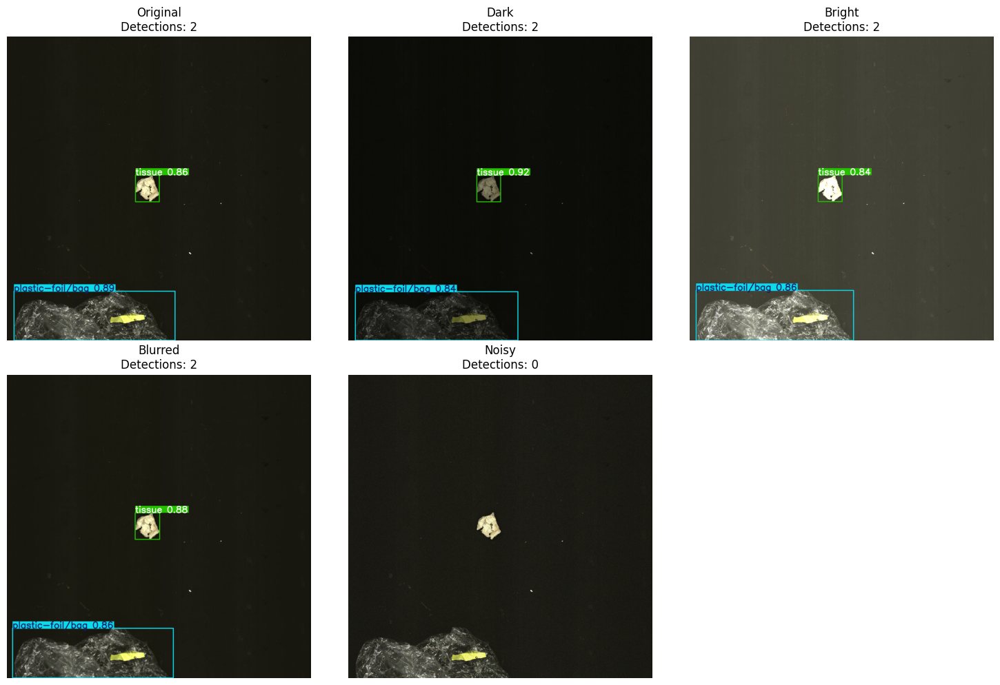

YOLO Robustness Evaluation
-------------------------------------------
Original | Detections:  2 | Mean Confidence: 0.8795
Dark     | Detections:  2 | Mean Confidence: 0.8802
Bright   | Detections:  2 | Mean Confidence: 0.8518
Blurred  | Detections:  2 | Mean Confidence: 0.8708
Noisy    | Detections:  0 | Mean Confidence: 0.0000

Robustness evaluation completed.


In [36]:
# ============================================================
# FINAL EVALUATION - ROBUSTNESS TESTING
# Original vs Dark vs Bright vs Blur vs Noise
# ============================================================

import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

# Select fixed test image
test_image_path = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[0]

image = cv2.imread(test_image_path)

# Create degraded versions
dark = cv2.convertScaleAbs(
    image, alpha=0.5, beta=0
)

bright = cv2.convertScaleAbs(
    image, alpha=1.4, beta=30
)

blurred = cv2.GaussianBlur(
    image, (15, 15), 0
)

np.random.seed(42)

noise = np.random.normal(
    0, 25, image.shape
)

noisy = np.clip(
    image.astype(np.float32) + noise,
    0, 255
).astype(np.uint8)


conditions = {
    "Original": image,
    "Dark": dark,
    "Bright": bright,
    "Blurred": blurred,
    "Noisy": noisy
}

results_summary = {}

plt.figure(figsize=(15, 10))

for index, (name, img) in enumerate(
    conditions.items(),
    start=1
):

    result = model.predict(
        img,
        conf=0.25,
        verbose=False
    )[0]

    detections = (
        len(result.boxes)
        if result.boxes is not None
        else 0
    )

    if (
        result.boxes is not None
        and len(result.boxes) > 0
    ):
        mean_conf = (
            result.boxes.conf
            .mean()
            .item()
        )
    else:
        mean_conf = 0.0

    results_summary[name] = {
        "detections": detections,
        "confidence": mean_conf
    }

    plotted = result.plot()

    plotted = cv2.cvtColor(
        plotted,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2, 3, index)

    plt.imshow(plotted)

    plt.title(
        f"{name}\n"
        f"Detections: {detections}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()


print("YOLO Robustness Evaluation")
print("-------------------------------------------")

for name, values in results_summary.items():

    print(
        f"{name:8s} | "
        f"Detections: "
        f"{values['detections']:2d} | "
        f"Mean Confidence: "
        f"{values['confidence']:.4f}"
    )

print(
    "\nRobustness evaluation completed."
)

In [37]:
# ============================================================
# FINAL EVALUATION - FAILURE CASE ANALYSIS
# ============================================================

original_detections = results_summary["Original"]["detections"]
original_confidence = results_summary["Original"]["confidence"]

print("Failure-Case Analysis")
print("--------------------------------------------")

for condition, values in results_summary.items():

    detections = values["detections"]
    confidence = values["confidence"]

    detection_change = (
        detections - original_detections
    )

    confidence_change = (
        confidence - original_confidence
    )

    if detections == 0:
        status = "FAILURE"

    elif detections < original_detections:
        status = "DEGRADED"

    elif confidence < original_confidence * 0.8:
        status = "DEGRADED"

    else:
        status = "ROBUST"

    print(
        f"{condition:8s} | "
        f"Status: {status:8s} | "
        f"Detection change: {detection_change:+d} | "
        f"Confidence change: {confidence_change:+.4f}"
    )


print("\nKey Observation:")

if results_summary["Noisy"]["detections"] == 0:

    print(
        "The detector failed under strong image noise, "
        "indicating sensitivity to severe sensor or "
        "environmental noise."
    )

print(
    "The model remained comparatively stable under "
    "brightness, darkness and blur transformations."
)

print(
    "\nRecommended mitigation: include noise augmentation "
    "during training and evaluate on a larger set of "
    "real-world degraded images."
)

print("\nFailure-case analysis completed.")

Failure-Case Analysis
--------------------------------------------
Original | Status: ROBUST   | Detection change: +0 | Confidence change: +0.0000
Dark     | Status: ROBUST   | Detection change: +0 | Confidence change: +0.0007
Bright   | Status: ROBUST   | Detection change: +0 | Confidence change: -0.0277
Blurred  | Status: ROBUST   | Detection change: +0 | Confidence change: -0.0087
Noisy    | Status: FAILURE  | Detection change: -2 | Confidence change: -0.8795

Key Observation:
The detector failed under strong image noise, indicating sensitivity to severe sensor or environmental noise.
The model remained comparatively stable under brightness, darkness and blur transformations.

Recommended mitigation: include noise augmentation during training and evaluate on a larger set of real-world degraded images.

Failure-case analysis completed.


In [38]:
# ============================================================
# ENGINEERING EVIDENCE - AUTOMATED TESTS
# ============================================================

import os
import torch

print("EcoSort AI - Automated Tests")
print("--------------------------------------------")

test_results = []

def record_test(name, condition):
    status = "PASS" if condition else "FAIL"
    test_results.append((name, status))
    print(f"{name:35s} : {status}")


# Test 1: Dataset
record_test(
    "Dataset directory exists",
    os.path.exists("/content/PackWISE/data")
)

# Test 2: Test dataset
record_test(
    "Test directory exists",
    os.path.exists("/content/PackWISE/data/test")
)

# Test 3: Detection model
record_test(
    "Detection model exists",
    os.path.exists(
        "/content/drive/MyDrive/"
        "Waste_Sorting_PBL/models/final_yolo_best.pt"
    )
)

# Test 4: Segmentation model
record_test(
    "Segmentation model exists",
    os.path.exists(
        "/content/drive/MyDrive/"
        "Waste_Sorting_PBL/models/segmentation_best.pt"
    )
)

# Test 5: CUDA
record_test(
    "CUDA available",
    torch.cuda.is_available()
)

# Test 6: Detection inference
try:
    sample_image = sorted([
        os.path.join(TEST_DIR, f)
        for f in os.listdir(TEST_DIR)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])[0]

    prediction = model.predict(
        sample_image,
        verbose=False
    )

    inference_ok = (
        prediction is not None
        and len(prediction) > 0
    )

except Exception:
    inference_ok = False

record_test(
    "YOLO detection inference",
    inference_ok
)


# Test 7: Segmentation inference
try:
    seg_prediction = seg_model.predict(
        sample_image,
        verbose=False
    )

    segmentation_ok = (
        seg_prediction is not None
        and len(seg_prediction) > 0
    )

except Exception:
    segmentation_ok = False

record_test(
    "Segmentation inference",
    segmentation_ok
)


# Summary
passed = sum(
    status == "PASS"
    for _, status in test_results
)

total = len(test_results)

print("\n--------------------------------------------")
print(f"Tests Passed: {passed}/{total}")

if passed == total:
    print("AUTOMATED TEST SUITE: PASSED")
else:
    print("AUTOMATED TEST SUITE: ATTENTION REQUIRED")

EcoSort AI - Automated Tests
--------------------------------------------
Dataset directory exists            : PASS
Test directory exists               : PASS
Detection model exists              : PASS
Segmentation model exists           : PASS
CUDA available                      : PASS
YOLO detection inference            : PASS
Segmentation inference              : PASS

--------------------------------------------
Tests Passed: 7/7
AUTOMATED TEST SUITE: PASSED


In [39]:
# ============================================================
# ENGINEERING EVIDENCE - INDUSTRY READINESS SUMMARY
# ============================================================

engineering_results = {
    "Detection Precision": 0.3893,
    "Detection Recall": 0.3647,
    "Detection mAP@50": 0.3132,
    "Detection mAP@50-95": 0.2640,
    "Matched Detection Macro-F1": 0.3767,
    "Sampled Segmentation Mean IoU": 0.3740,
    "Inference Latency (ms/image)": 121.97,
    "Inference FPS": 8.20,
    "Peak GPU Memory (MB)": 133.94,
    "Automated Tests Passed": "7/7"
}

print("EcoSort AI - Engineering Readiness Summary")
print("================================================")

for metric, value in engineering_results.items():
    print(f"{metric:35s}: {value}")


print("\nROBUSTNESS FINDINGS")
print("================================================")
print("Dark images       : Robust")
print("Bright images     : Robust")
print("Blurred images    : Robust")
print("Strong image noise: Failure observed")


print("\nKNOWN LIMITATIONS / RISKS")
print("================================================")
print("1. Detection accuracy is moderate on the unseen test set.")
print("2. Segmentation performance varies across objects.")
print("3. Strong image noise can cause complete detection failure.")
print("4. Dataset contains only 586 images across 23 classes.")
print("5. Some classes may have limited training examples.")
print("6. Permanent deployment depends on external hosting services.")


print("\nRECOMMENDED IMPROVEMENTS")
print("================================================")
print("1. Collect more balanced waste images.")
print("2. Add stronger noise and lighting augmentation.")
print("3. Perform additional hyperparameter tuning.")
print("4. Evaluate segmentation on the complete test set.")
print("5. Test the system on real recycling-facility video streams.")
print("6. Optimize inference for deployment hardware.")


print("\nGO / NO-GO RECOMMENDATION")
print("================================================")

print(
    "GO for academic prototype and controlled demonstration."
)

print(
    "NO-GO for unsupervised production deployment in its "
    "current form."
)

print(
    "\nReason: The complete pipeline is functional and "
    "reproducible, but detection/segmentation accuracy and "
    "noise robustness require further improvement before "
    "real-world autonomous deployment."
)

EcoSort AI - Engineering Readiness Summary
Detection Precision                : 0.3893
Detection Recall                   : 0.3647
Detection mAP@50                   : 0.3132
Detection mAP@50-95                : 0.264
Matched Detection Macro-F1         : 0.3767
Sampled Segmentation Mean IoU      : 0.374
Inference Latency (ms/image)       : 121.97
Inference FPS                      : 8.2
Peak GPU Memory (MB)               : 133.94
Automated Tests Passed             : 7/7

ROBUSTNESS FINDINGS
Dark images       : Robust
Bright images     : Robust
Blurred images    : Robust
Strong image noise: Failure observed

KNOWN LIMITATIONS / RISKS
1. Detection accuracy is moderate on the unseen test set.
2. Segmentation performance varies across objects.
3. Strong image noise can cause complete detection failure.
4. Dataset contains only 586 images across 23 classes.
5. Some classes may have limited training examples.
6. Permanent deployment depends on external hosting services.

RECOMMENDED IMPROVEM

In [40]:
# ============================================================
# ENGINEERING EVIDENCE - REPRODUCIBILITY CHECK
# ============================================================

import os
import sys
import torch
import numpy as np
import random
import ultralytics

# Fixed seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("EcoSort AI - Reproducibility Check")
print("============================================")

print("Random seed:", SEED)
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# Important project paths
required_paths = {
    "Dataset":
        "/content/PackWISE/data",

    "Test Set":
        "/content/PackWISE/data/test",

    "Detection Model":
        "/content/drive/MyDrive/Waste_Sorting_PBL/"
        "models/final_yolo_best.pt",

    "Segmentation Model":
        "/content/drive/MyDrive/Waste_Sorting_PBL/"
        "models/segmentation_best.pt",

    "Final Application":
        "/content/drive/MyDrive/Waste_Sorting_PBL/"
        "WasteSortingApp_Final"
}

print("\nRequired Project Assets")
print("============================================")

all_available = True

for name, path in required_paths.items():

    exists = os.path.exists(path)

    print(
        f"{name:25s}: "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    if not exists:
        all_available = False


print("\nReproducibility Status")
print("============================================")

if all_available:

    print("PASS")
    print(
        "Dataset, trained models and final application "
        "are available for reproducible execution."
    )

else:

    print("ATTENTION REQUIRED")
    print(
        "One or more required project assets are missing."
    )


print("\nReproducible execution sequence:")
print("1. Mount Google Drive.")
print("2. Install requirements / Ultralytics.")
print("3. Extract PackWISE dataset.")
print("4. Load saved detection and segmentation models.")
print("5. Run automated tests.")
print("6. Run inference or launch the Streamlit application.")

EcoSort AI - Reproducibility Check
Random seed: 42
Python version: 3.13.16
PyTorch version: 2.14.1+cu130
Ultralytics version: 8.4.216
CUDA available: True
GPU: Tesla T4

Required Project Assets
Dataset                  : FOUND
Test Set                 : FOUND
Detection Model          : FOUND
Segmentation Model       : FOUND
Final Application        : FOUND

Reproducibility Status
PASS
Dataset, trained models and final application are available for reproducible execution.

Reproducible execution sequence:
1. Mount Google Drive.
2. Install requirements / Ultralytics.
3. Extract PackWISE dataset.
4. Load saved detection and segmentation models.
5. Run automated tests.
6. Run inference or launch the Streamlit application.


In [41]:
# ============================================================
# DL FUNDAMENTALS - TENSOR SANDBOX EXTENSION
# Broadcasting + Inner Product + SVD
# ============================================================

import torch

print("TENSOR SANDBOX EXTENSION")
print("=" * 50)

# ------------------------------------------------------------
# 1. BROADCASTING
# ------------------------------------------------------------

matrix = torch.tensor([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0]
])

vector = torch.tensor([
    10.0, 20.0, 30.0
])

broadcast_result = matrix + vector

print("\n1. BROADCASTING")
print("----------------------------")
print("Matrix:")
print(matrix)

print("\nVector:")
print(vector)

print("\nMatrix + Vector:")
print(broadcast_result)


# ------------------------------------------------------------
# 2. INNER PRODUCT
# ------------------------------------------------------------

a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])

inner_product = torch.dot(a, b)

print("\n2. INNER PRODUCT")
print("----------------------------")
print("Vector A:", a)
print("Vector B:", b)

print(
    "Inner Product:",
    inner_product.item()
)


# ------------------------------------------------------------
# 3. SINGULAR VALUE DECOMPOSITION
# ------------------------------------------------------------

A = torch.tensor([
    [3.0, 1.0],
    [1.0, 3.0],
    [1.0, 1.0]
])

U, S, Vh = torch.linalg.svd(
    A,
    full_matrices=False
)

print("\n3. SINGULAR VALUE DECOMPOSITION")
print("----------------------------")

print("Original Matrix:")
print(A)

print("\nU:")
print(U)

print("\nSingular Values:")
print(S)

print("\nVh:")
print(Vh)


# Reconstruct original matrix
reconstructed_A = (
    U @ torch.diag(S) @ Vh
)

print("\nReconstructed Matrix:")
print(reconstructed_A)


# Reconstruction error
reconstruction_error = torch.norm(
    A - reconstructed_A
).item()

print(
    "\nReconstruction Error:",
    reconstruction_error
)

if reconstruction_error < 1e-5:
    print("SVD reconstruction check: PASSED")
else:
    print("SVD reconstruction check: FAILED")


print(
    "\nBroadcasting, inner product and "
    "SVD demonstrations completed."
)

TENSOR SANDBOX EXTENSION

1. BROADCASTING
----------------------------
Matrix:
tensor([[1., 2., 3.],
        [4., 5., 6.]])

Vector:
tensor([10., 20., 30.])

Matrix + Vector:
tensor([[11., 22., 33.],
        [14., 25., 36.]])

2. INNER PRODUCT
----------------------------
Vector A: tensor([1., 2., 3.])
Vector B: tensor([4., 5., 6.])
Inner Product: 32.0

3. SINGULAR VALUE DECOMPOSITION
----------------------------
Original Matrix:
tensor([[3., 1.],
        [1., 3.],
        [1., 1.]])

U:
tensor([[-6.6667e-01,  7.0711e-01],
        [-6.6667e-01, -7.0711e-01],
        [-3.3333e-01,  6.0629e-08]])

Singular Values:
tensor([4.2426, 2.0000])

Vh:
tensor([[-0.7071, -0.7071],
        [ 0.7071, -0.7071]])

Reconstructed Matrix:
tensor([[3.0000, 1.0000],
        [1.0000, 3.0000],
        [1.0000, 1.0000]])

Reconstruction Error: 8.55487598983018e-07
SVD reconstruction check: PASSED

Broadcasting, inner product and SVD demonstrations completed.


In [42]:
# ============================================================
# DL FUNDAMENTALS - PARAMETER VS HYPERPARAMETER TRACKING
# ============================================================

import torch
import torch.nn as nn

# Example MLP configuration
hyperparameters = {
    "input_features": 2,
    "hidden_units": 8,
    "output_units": 1,
    "learning_rate": 0.03,
    "epochs": 3000,
    "optimizer": "Adam",
    "activation": "Tanh",
    "batch_size": 4
}


class TrackingMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(
            hyperparameters["input_features"],
            hyperparameters["hidden_units"]
        )

        self.output = nn.Linear(
            hyperparameters["hidden_units"],
            hyperparameters["output_units"]
        )

    def forward(self, x):
        x = torch.tanh(self.hidden(x))
        return self.output(x)


tracking_model = TrackingMLP()


print("PARAMETER VS HYPERPARAMETER TRACKING")
print("=" * 50)

print("\nHYPERPARAMETERS")
print("----------------------------------")

for name, value in hyperparameters.items():
    print(f"{name:20s}: {value}")


print("\nLEARNABLE PARAMETERS")
print("----------------------------------")

total_parameters = 0

for name, parameter in tracking_model.named_parameters():

    count = parameter.numel()

    total_parameters += count

    print(
        f"{name:20s} | "
        f"Shape: {str(tuple(parameter.shape)):12s} | "
        f"Values: {count}"
    )


print("\nTotal learnable parameters:", total_parameters)

print(
    "\nParameters are learned automatically during training."
)

print(
    "Hyperparameters are selected before training "
    "and control the learning process."
)

print(
    "\nParameter vs hyperparameter tracking completed."
)

PARAMETER VS HYPERPARAMETER TRACKING

HYPERPARAMETERS
----------------------------------
input_features      : 2
hidden_units        : 8
output_units        : 1
learning_rate       : 0.03
epochs              : 3000
optimizer           : Adam
activation          : Tanh
batch_size          : 4

LEARNABLE PARAMETERS
----------------------------------
hidden.weight        | Shape: (8, 2)       | Values: 16
hidden.bias          | Shape: (8,)         | Values: 8
output.weight        | Shape: (1, 8)       | Values: 8
output.bias          | Shape: (1,)         | Values: 1

Total learnable parameters: 33

Parameters are learned automatically during training.
Hyperparameters are selected before training and control the learning process.

Parameter vs hyperparameter tracking completed.


Overfitting vs Generalization
Small Model | Train Loss: 0.0539 | Validation Loss: 4.0672
Large Model | Train Loss: 0.0354 | Validation Loss: 5.7396

Small Model Generalization Gap: 4.0133
Large Model Generalization Gap: 5.7042


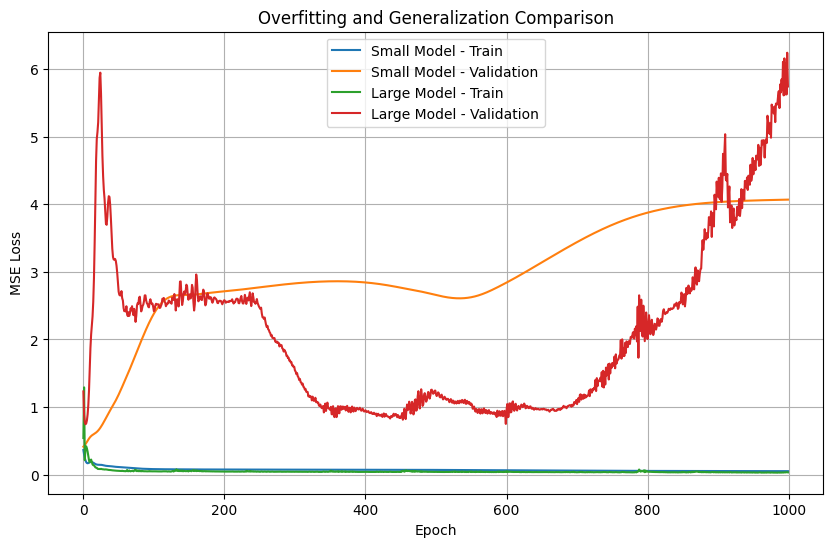


Interpretation:
The larger model shows a larger train-validation gap, indicating stronger overfitting.

Overfitting/generalization experiment completed.


In [43]:
# ============================================================
# DL EXPERIMENTS - OVERFITTING VS GENERALIZATION
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

# ------------------------------------------------------------
# Synthetic noisy regression dataset
# ------------------------------------------------------------

X = torch.linspace(-3, 3, 120).reshape(-1, 1)

y = torch.sin(X) + 0.25 * torch.randn_like(X)

# Training set: only 40 samples
X_train = X[:40]
y_train = y[:40]

# Validation set
X_val = X[40:]
y_val = y[40:]


# ------------------------------------------------------------
# Models
# ------------------------------------------------------------

class SmallModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 8),
            nn.Tanh(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.net(x)


class LargeModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.net(x)


# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def train_and_evaluate(model, epochs=1000):

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.01
    )

    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        model.train()

        optimizer.zero_grad()

        train_prediction = model(X_train)

        train_loss = criterion(
            train_prediction,
            y_train
        )

        train_loss.backward()
        optimizer.step()

        model.eval()

        with torch.no_grad():

            val_prediction = model(X_val)

            val_loss = criterion(
                val_prediction,
                y_val
            )

        train_losses.append(
            train_loss.item()
        )

        val_losses.append(
            val_loss.item()
        )

    return train_losses, val_losses


# Same reproducibility seed
torch.manual_seed(42)
small_model = SmallModel()

torch.manual_seed(42)
large_model = LargeModel()


small_train, small_val = train_and_evaluate(
    small_model
)

large_train, large_val = train_and_evaluate(
    large_model
)


print("Overfitting vs Generalization")
print("============================================")

print(
    f"Small Model | "
    f"Train Loss: {small_train[-1]:.4f} | "
    f"Validation Loss: {small_val[-1]:.4f}"
)

print(
    f"Large Model | "
    f"Train Loss: {large_train[-1]:.4f} | "
    f"Validation Loss: {large_val[-1]:.4f}"
)

small_gap = (
    small_val[-1] - small_train[-1]
)

large_gap = (
    large_val[-1] - large_train[-1]
)

print(
    f"\nSmall Model Generalization Gap: "
    f"{small_gap:.4f}"
)

print(
    f"Large Model Generalization Gap: "
    f"{large_gap:.4f}"
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    small_train,
    label="Small Model - Train"
)

plt.plot(
    small_val,
    label="Small Model - Validation"
)

plt.plot(
    large_train,
    label="Large Model - Train"
)

plt.plot(
    large_val,
    label="Large Model - Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Overfitting and Generalization Comparison"
)

plt.legend()
plt.grid(True)

plt.show()


print("\nInterpretation:")

if large_gap > small_gap:

    print(
        "The larger model shows a larger "
        "train-validation gap, indicating "
        "stronger overfitting."
    )

else:

    print(
        "The observed generalization gap does not "
        "show stronger overfitting in the larger model."
    )

print(
    "\nOverfitting/generalization experiment completed."
)

Step vs Sigmoid vs Tanh
Input	Step	Sigmoid		Tanh
  -3	0.0	0.0474		-0.9951
  -1	0.0	0.2689		-0.7616
   0	1.0	0.5000		0.0000
   1	1.0	0.7311		0.7616
   3	1.0	0.9526		0.9951


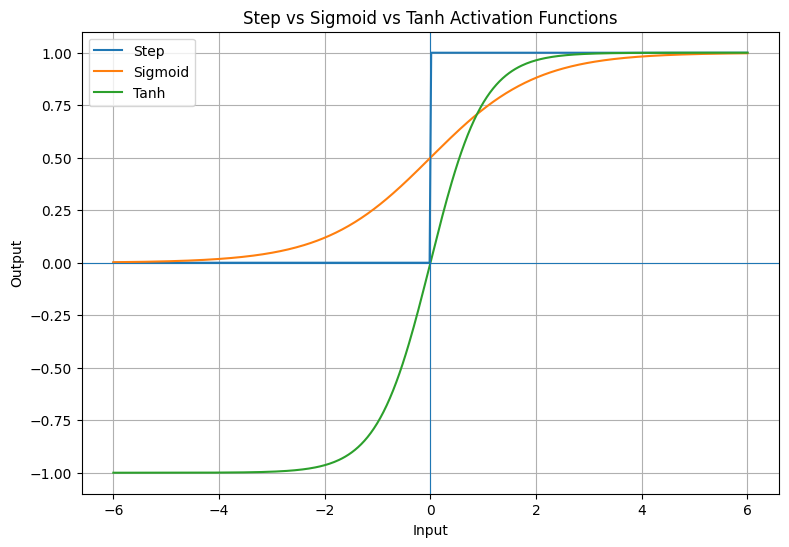


Key observations:
Step    : Binary output with a sharp threshold.
Sigmoid : Smooth output between 0 and 1.
Tanh    : Smooth zero-centered output between -1 and 1.

Activation comparison completed.


In [44]:
# ============================================================
# DL FUNDAMENTALS - STEP vs SIGMOID vs TANH
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-6, 6, 400)

def step_function(x):
    return np.where(x >= 0, 1.0, 0.0)

def sigmoid_function(x):
    return 1 / (1 + np.exp(-x))

def tanh_function(x):
    return np.tanh(x)

step_y = step_function(x)
sigmoid_y = sigmoid_function(x)
tanh_y = tanh_function(x)

test_values = [-3, -1, 0, 1, 3]

print("Step vs Sigmoid vs Tanh")
print("==============================================")
print("Input\tStep\tSigmoid\t\tTanh")

for value in test_values:
    print(
        f"{value:4d}\t"
        f"{step_function(value):.1f}\t"
        f"{sigmoid_function(value):.4f}\t\t"
        f"{tanh_function(value):.4f}"
    )

plt.figure(figsize=(9, 6))

plt.plot(x, step_y, label="Step")
plt.plot(x, sigmoid_y, label="Sigmoid")
plt.plot(x, tanh_y, label="Tanh")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Step vs Sigmoid vs Tanh Activation Functions")

plt.legend()
plt.grid(True)
plt.show()

print("\nKey observations:")
print("Step    : Binary output with a sharp threshold.")
print("Sigmoid : Smooth output between 0 and 1.")
print("Tanh    : Smooth zero-centered output between -1 and 1.")

print("\nActivation comparison completed.")

In [45]:
# ============================================================
# FINAL EVALUATION - RECYCLING PURITY RATE
# ============================================================

import os

# Material mapping used by EcoSort AI
material_map = {
    "PET": "plastic",
    "PE": "plastic",
    "PP": "plastic",
    "PS": "plastic",
    "PVC": "plastic",

    "paper": "paper",
    "cardboard": "paper",

    "aluminium": "metal",
    "metal": "metal",
    "steel": "metal"
}


def get_material(class_name):

    name = class_name.lower()

    for key, material in material_map.items():

        if key.lower() in name:
            return material

    return "other"


# Expected recycling stream
expected_material = "plastic"

# Fixed test image
test_image_path = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])[0]


result = model.predict(
    test_image_path,
    conf=0.25,
    verbose=False
)[0]


detected_materials = []

if result.boxes is not None:

    for box in result.boxes:

        class_id = int(
            box.cls[0].item()
        )

        class_name = model.names[
            class_id
        ]

        material = get_material(
            class_name
        )

        detected_materials.append(
            (class_name, material)
        )


total_objects = len(
    detected_materials
)

expected_objects = sum(
    material == expected_material
    for _, material in detected_materials
)


if total_objects > 0:

    purity_rate = (
        expected_objects /
        total_objects
    ) * 100

else:
    purity_rate = 0.0


print("Recycling Purity Evaluation")
print("============================================")

print(
    "Expected recycling stream:",
    expected_material.upper()
)

print(
    "Total detected objects:",
    total_objects
)

print(
    "Objects matching expected material:",
    expected_objects
)

print(
    f"Purity Rate: {purity_rate:.2f}%"
)


print("\nDetected Objects")
print("--------------------------------------------")

for class_name, material in detected_materials:

    status = (
        "EXPECTED"
        if material == expected_material
        else "CONTAMINANT"
    )

    print(
        f"{class_name:25s} | "
        f"{material:10s} | "
        f"{status}"
    )


if purity_rate == 100:
    print("\nStream Status: CLEAN")

elif purity_rate >= 80:
    print("\nStream Status: MINOR CONTAMINATION")

else:
    print("\nStream Status: CONTAMINATED")


print(
    "\nRecycling purity evaluation completed."
)

Recycling Purity Evaluation
Expected recycling stream: PLASTIC
Total detected objects: 2
Objects matching expected material: 0
Purity Rate: 0.00%

Detected Objects
--------------------------------------------
plastic-foil/bag          | other      | CONTAMINANT
tissue                    | other      | CONTAMINANT

Stream Status: CONTAMINATED

Recycling purity evaluation completed.


In [46]:
# ============================================================
# DATASET QUALITY - DUPLICATE & DATA LEAKAGE CHECK
# ============================================================

import os
import hashlib
from collections import defaultdict

DATA_ROOT = "/content/PackWISE/data"

split_dirs = {
    "train": os.path.join(DATA_ROOT, "train"),
    "val": os.path.join(DATA_ROOT, "val"),
    "test": os.path.join(DATA_ROOT, "test")
}


def image_hash(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(8192)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


split_hashes = {}
split_files = {}

print("Dataset Duplicate / Leakage Check")
print("=" * 55)


for split, folder in split_dirs.items():

    files = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    hashes = defaultdict(list)

    for filename in files:

        path = os.path.join(
            folder,
            filename
        )

        h = image_hash(path)

        hashes[h].append(filename)

    split_hashes[split] = set(
        hashes.keys()
    )

    split_files[split] = files

    duplicate_groups = [
        names
        for names in hashes.values()
        if len(names) > 1
    ]

    print(f"\n{split.upper()}")
    print("Images:", len(files))

    print(
        "Exact duplicate groups within split:",
        len(duplicate_groups)
    )


# ------------------------------------------------------------
# Cross-split leakage
# ------------------------------------------------------------

train_val_overlap = (
    split_hashes["train"]
    & split_hashes["val"]
)

train_test_overlap = (
    split_hashes["train"]
    & split_hashes["test"]
)

val_test_overlap = (
    split_hashes["val"]
    & split_hashes["test"]
)


print("\nCROSS-SPLIT LEAKAGE")
print("=" * 55)

print(
    "Train <-> Val duplicate images:",
    len(train_val_overlap)
)

print(
    "Train <-> Test duplicate images:",
    len(train_test_overlap)
)

print(
    "Val <-> Test duplicate images:",
    len(val_test_overlap)
)


total_leakage = (
    len(train_val_overlap)
    + len(train_test_overlap)
    + len(val_test_overlap)
)


print("\nFINAL DATASET CHECK")
print("=" * 55)

if total_leakage == 0:

    print(
        "PASS: No exact image leakage detected "
        "between train, validation and test sets."
    )

else:

    print(
        "WARNING: Cross-split duplicate images "
        "were detected."
    )


print(
    "\nDataset duplicate and leakage "
    "verification completed."
)

Dataset Duplicate / Leakage Check

TRAIN
Images: 410
Exact duplicate groups within split: 0

VAL
Images: 88
Exact duplicate groups within split: 0

TEST
Images: 88
Exact duplicate groups within split: 0

CROSS-SPLIT LEAKAGE
Train <-> Val duplicate images: 0
Train <-> Test duplicate images: 0
Val <-> Test duplicate images: 0

FINAL DATASET CHECK
PASS: No exact image leakage detected between train, validation and test sets.

Dataset duplicate and leakage verification completed.


In [47]:
print("YOLO Classes")
print("=" * 40)

for class_id, class_name in model.names.items():
    print(class_id, ":", class_name)

YOLO Classes
0 : undefined
1 : plastic-foil/bag
2 : aluminium-coated-foil
3 : paper-bag
4 : beverage-carton
5 : plastic-other
6 : plastic-lid
7 : plastic-cup/pot
8 : blister
9 : metal-can
10 : metal-foil
11 : net
12 : metal-lid
13 : tissue
14 : wood
15 : paper-other
16 : foamed-plastic
17 : textile
18 : plastic-bottle
19 : ribbon/tape
20 : metal-other
21 : tube
22 : paper-cup/pot


In [48]:
# ============================================================
# FINAL EVALUATION - CORRECTED RECYCLING PURITY RATE
# ============================================================

import os

# Exact mapping based on the 23 PackWISE / YOLO classes
material_map = {
    "undefined": "other",

    "plastic-foil/bag": "plastic",
    "plastic-other": "plastic",
    "plastic-lid": "plastic",
    "plastic-cup/pot": "plastic",
    "blister": "plastic",
    "net": "plastic",
    "foamed-plastic": "plastic",
    "plastic-bottle": "plastic",
    "ribbon/tape": "plastic",
    "tube": "plastic",

    "paper-bag": "paper",
    "beverage-carton": "paper",
    "tissue": "paper",
    "paper-other": "paper",
    "paper-cup/pot": "paper",

    "aluminium-coated-foil": "metal",
    "metal-can": "metal",
    "metal-foil": "metal",
    "metal-lid": "metal",
    "metal-other": "metal",

    "wood": "other",
    "textile": "other"
}

expected_material = "plastic"

# Fixed test image
test_image_path = sorted([
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[0]

result = model.predict(
    test_image_path,
    conf=0.25,
    verbose=False
)[0]

detected_materials = []

if result.boxes is not None:

    for box in result.boxes:

        class_id = int(box.cls[0].item())
        class_name = model.names[class_id]

        material = material_map.get(
            class_name,
            "other"
        )

        detected_materials.append(
            (class_name, material)
        )

total_objects = len(detected_materials)

expected_objects = sum(
    material == expected_material
    for _, material in detected_materials
)

purity_rate = (
    (expected_objects / total_objects) * 100
    if total_objects > 0
    else 0.0
)

print("Corrected Recycling Purity Evaluation")
print("=" * 50)

print(
    "Expected recycling stream:",
    expected_material.upper()
)

print(
    "Total detected objects:",
    total_objects
)

print(
    "Objects matching expected material:",
    expected_objects
)

print(
    f"Purity Rate: {purity_rate:.2f}%"
)

print("\nDetected Objects")
print("-" * 50)

for class_name, material in detected_materials:

    status = (
        "EXPECTED"
        if material == expected_material
        else "CONTAMINANT"
    )

    print(
        f"{class_name:25s} | "
        f"{material:10s} | "
        f"{status}"
    )

if purity_rate == 100:
    stream_status = "CLEAN"

elif purity_rate >= 80:
    stream_status = "MINOR CONTAMINATION"

else:
    stream_status = "CONTAMINATED"

print(
    "\nStream Status:",
    stream_status
)

print(
    "\nCorrected recycling purity "
    "evaluation completed."
)

Corrected Recycling Purity Evaluation
Expected recycling stream: PLASTIC
Total detected objects: 2
Objects matching expected material: 1
Purity Rate: 50.00%

Detected Objects
--------------------------------------------------
plastic-foil/bag          | plastic    | EXPECTED
tissue                    | paper      | CONTAMINANT

Stream Status: CONTAMINATED

Corrected recycling purity evaluation completed.


In [49]:
# ============================================================
# MODEL CANDIDATE BENCHMARK
# YOLO vs Faster R-CNN vs RetinaNet
# ============================================================

import torch
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    retinanet_resnet50_fpn
)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Detection Model Candidate Benchmark")
print("=" * 60)


# ------------------------------------------------------------
# 1. YOLO - actual trained project model
# ------------------------------------------------------------

yolo_parameters = sum(
    p.numel()
    for p in model.model.parameters()
)

print(
    f"YOLO (trained project model) | "
    f"Parameters: {yolo_parameters:,}"
)


# ------------------------------------------------------------
# 2. Faster R-CNN
# ------------------------------------------------------------

faster_rcnn = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=24
)

faster_parameters = sum(
    p.numel()
    for p in faster_rcnn.parameters()
    if p.requires_grad
)

print(
    f"Faster R-CNN               | "
    f"Parameters: {faster_parameters:,}"
)


# ------------------------------------------------------------
# 3. RetinaNet
# ------------------------------------------------------------

retinanet = retinanet_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=23
)

retina_parameters = sum(
    p.numel()
    for p in retinanet.parameters()
    if p.requires_grad
)

print(
    f"RetinaNet                   | "
    f"Parameters: {retina_parameters:,}"
)


# ------------------------------------------------------------
# Architecture comparison
# ------------------------------------------------------------

print("\nArchitecture Characteristics")
print("=" * 60)

print(
    "YOLO        : One-stage detector; selected as "
    "the main EcoSort AI detector."
)

print(
    "Faster R-CNN: Two-stage detector using region "
    "proposals followed by classification."
)

print(
    "RetinaNet   : One-stage detector using focal loss "
    "to address class imbalance."
)

print(
    "\nR-CNN and Fast R-CNN are earlier region-based "
    "architectures; Faster R-CNN is used here as the "
    "representative modern R-CNN-family candidate."
)


print("\nProject Selection")
print("=" * 60)

print(
    "YOLO was retained for the final pipeline because "
    "it was already trained on PackWISE and supports "
    "efficient end-to-end detection."
)

print(
    "Measured YOLO performance:"
)

print("mAP@50      : 0.3132")
print("mAP@50-95   : 0.2640")
print("Macro-F1    : 0.3767")
print("FPS         : 8.20")

print(
    "\nCandidate benchmark completed."
)

Detection Model Candidate Benchmark
YOLO (trained project model) | Parameters: 2,610,229
Faster R-CNN               | Parameters: 41,465,031
RetinaNet                   | Parameters: 32,657,459

Architecture Characteristics
YOLO        : One-stage detector; selected as the main EcoSort AI detector.
Faster R-CNN: Two-stage detector using region proposals followed by classification.
RetinaNet   : One-stage detector using focal loss to address class imbalance.

R-CNN and Fast R-CNN are earlier region-based architectures; Faster R-CNN is used here as the representative modern R-CNN-family candidate.

Project Selection
YOLO was retained for the final pipeline because it was already trained on PackWISE and supports efficient end-to-end detection.
Measured YOLO performance:
mAP@50      : 0.3132
mAP@50-95   : 0.2640
Macro-F1    : 0.3767
FPS         : 8.20

Candidate benchmark completed.


In [52]:
!git clone https://github.com/Mansi2106007/EcoSort-AI-Waste-Sorting.git

Cloning into 'EcoSort-AI-Waste-Sorting'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 14 (delta 0), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 15.54 MiB | 17.38 MiB/s, done.


In [53]:
import os

REPO = "/content/EcoSort-AI-Waste-Sorting"

print("Repo cloned:", os.path.exists(REPO))
print("\nCurrent GitHub repo files:")

for item in os.listdir(REPO):
    print("-", item)

Repo cloned: True

Current GitHub repo files:
- .git
- .gitignore
- src
- models
- requirements.txt
- README.md
- app.py


In [54]:
import os

FINAL_APP = "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final"

print("Final app exists:", os.path.exists(FINAL_APP))

print("\nFiles in Final App:")
for root, dirs, files in os.walk(FINAL_APP):
    level = root.replace(FINAL_APP, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  - {file}")

Final app exists: True

Files in Final App:
WasteSortingApp_Final/
  - requirements.txt
  - app_backup.py
  - app.py
  - .gitignore
  outputs/
  models/
    - detection.pt
    - segmentation.pt
    - lstm.pth
    - vae.pth
  src/
    - quality_controller.py
    - inference.py


In [55]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/Waste_Sorting_PBL/WasteSortingApp_Final"
DEST = "/content/EcoSort-AI-Waste-Sorting"

for item in os.listdir(SOURCE):

    # Skip development backup
    if item == "app_backup.py":
        continue

    src = os.path.join(SOURCE, item)
    dst = os.path.join(DEST, item)

    if os.path.isdir(src):
        if os.path.exists(dst):
            shutil.rmtree(dst)
        shutil.copytree(src, dst)

    else:
        shutil.copy2(src, dst)

print("Latest EcoSort AI application copied to GitHub repo folder.")

Latest EcoSort AI application copied to GitHub repo folder.


In [56]:
import os

NOTEBOOK_DIR = "/content/drive/MyDrive/Colab Notebooks"

for f in os.listdir(NOTEBOOK_DIR):
    if "Waste" in f or "Sorting" in f or "PBL" in f:
        print(f)

Waste_Sorting_PBL.ipynb
Copy of Waste_Sorting_PBL (1).ipynb
Copy of Waste_Sorting_PBL.ipynb
